# A complete tour of Petrophys

This notebook walks one real North Sea well from raw LAS file to per-formation
net pay, and then goes wider: four wells side by side, core calibration, cutoff
and parameter sensitivity, and a gallery of the library's plots. Every section
runs on data bundled with the package, so the notebook works offline and every
number you see is computed in the cell above it.

The tour uses two levels of the library, and it is worth knowing which is which:

- **The front door**, `import petrophys as pp`: `pp.read` loads a well,
  `pp.interpret` runs the whole interpretation on a copy of it, and `pp.plot`
  draws it. This is what you use for whole-well work.
- **The domain modules**, `petrophys.interpretation.*` (one equation or module
  per property), `petrophys.evaluation.*` (net pay, intervals, summaries),
  `petrophys.preprocessing`, `petrophys.io` and `petrophys.visualization`. The
  front door is built from these; you call them directly when you want to see
  or control one step.

Sections 1-9 build the interpretation by hand with the domain modules, so you
see each equation. Section 10 runs the same interpretation through
`pp.interpret` and compares the two.

## Learning goals

By the end of this tour you will be able to:

- Load a LAS well with formation tops and lithology intervals, and inspect its
  curves, units and header parameters.
- Standardize curves and run the basic quality checks (value ranges, bad hole).
- Compute clay volume, porosity, water saturation (four models), permeability
  and net-pay flags with the individual equations, and explain each choice.
- Summarize results per formation, per zone and per depth window, and roll them
  up to hydrocarbon pore volume.
- Run the full interpretation with `pp.interpret`, read its trace, and export it.
- Compare several wells, calibrate logs against core, and test how sensitive net
  pay is to cutoffs and parameters.
- Pick the right plot from the visualization toolbox.

### Prerequisites

Install the package with the tutorial extra (`python -m pip install -e ".[tutorials]"`
from the repository root). No other extra is needed. The
[quickstart](quickstart.ipynb) is a gentler first contact; this tour assumes you
know what a well log is but nothing about the library.

## Why this matters

A petrophysical answer such as "30 m of net pay" is the end of a long chain:
curve names and units, bad-hole screening, clay volume, porosity, formation-water
resistivity at the right temperature, a saturation model, cutoffs, and the depth
window you add it up over. A mistake anywhere in the chain changes the answer,
and a tool that hides the chain makes the mistake hard to find. This tour opens
every link once, so that when you later call `pp.interpret` you know what it did
and where to look when a number surprises you.

### How this tour relates to the lessons

Each section here is a summary. The lesson in the right-hand column covers the
same ground in depth, with the theory and more exercises.

| Tour section | Lesson that goes deeper |
|---|---|
| 1. Loading and inspecting a LAS file | [01 - Loading and inspecting data](part_a_foundations/01_loading_and_inspecting_data.ipynb) |
| 2. Curve standardization and QC | [02 - QA/QC and standardization](part_a_foundations/02_qaqc_and_standardization.ipynb) |
| 3. Lithology and formation tops | [05 - Lithology and mineral solver](part_a_foundations/05_lithology_and_mineral_solver.ipynb), [11 - Formation and interval analysis](part_b_advanced/11_formation_and_interval_analysis.ipynb) |
| 4. Clay volume | [03 - Clay volume](part_a_foundations/03_clay_volume.ipynb) |
| 5. Porosity | [04 - Porosity](part_a_foundations/04_porosity.ipynb) |
| 6. Water saturation | [06 - Formation water and environment](part_a_foundations/06_formation_water_and_environment.ipynb), [07 - Water saturation](part_a_foundations/07_water_saturation.ipynb) |
| 7. Permeability | [08 - Permeability](part_a_foundations/08_permeability.ipynb) |
| 8. Net pay | [09 - Reservoir quality and net pay](part_a_foundations/09_reservoir_quality_and_net_pay.ipynb) |
| 9. Formation-level interval analysis | [11 - Formation and interval analysis](part_b_advanced/11_formation_and_interval_analysis.ipynb) |
| 10. The full workflow with `pp.interpret` | [10 - Dynamic workflow glass box](part_b_advanced/10_dynamic_workflow_glass_box.ipynb) |
| 11. Multi-well comparison | [18 - Multi-well field study](part_b_advanced/18_multiwell_field_study.ipynb) |
| 12. Additional reservoir calculations | [09 - Reservoir quality and net pay](part_a_foundations/09_reservoir_quality_and_net_pay.ipynb) |
| 13. Zone summaries and HCPV | [11 - Formation and interval analysis](part_b_advanced/11_formation_and_interval_analysis.ipynb) |
| 14. Exporting results | [10 - Dynamic workflow glass box](part_b_advanced/10_dynamic_workflow_glass_box.ipynb) |
| 15. Core data and log-core calibration | [12 - Core calibration and digital core](part_b_advanced/12_core_calibration_and_digital_core.ipynb) |
| 15b. Sensitivity analysis | [10 - Dynamic workflow glass box](part_b_advanced/10_dynamic_workflow_glass_box.ipynb) |
| 16. Visualization gallery | [17 - Visualization masterclass](part_b_advanced/17_visualization_masterclass.ipynb) |

The case studies in `examples/case_studies/` apply the same tools to complete
problems; CS1 (30/6-5) and CS5 (saturation-model sensitivity) are the closest
to this tour.

### Data and working assumptions

Everything comes from the bundled samples (`pp.list_samples()`):

- **Main well: GeoLink 30/6-5** (Oseberg Øst, Norwegian North Sea, depths in
  metres). Its reservoir is the **Brent Group, 2841-2958 m** (labelled
  `BAAT GP.` in the bundled tops): the Ness Fm. (2841-2865 m) over the Etive Fm.
  (2865-2958 m). The Dunlin Group lies below, the Statfjord Fm. deeper still.
  Formation tops: `pp.sample("formations_30_6-5")`; lithology intervals:
  `pp.sample("lithology_30_6-5")`; core plugs are stored in the LAS as the
  curves `PHIC` (porosity), `KH_CORE` (permeability) and `SWC` (water saturation).
- **Formation water for 30/6-5: Rw = 0.070 ohm.m measured at 230 degF**, with
  Archie constants a = 0.80, m = n = 2 (the operator values used in lessons 07-09).
  The bundled LAS header records the same value (`RW = 0.07` ohm.m with
  `RWT = 230` degF). The temperature matters: an Rw without its temperature is
  taken at the median formation temperature, which changes saturation strongly.
- **Other wells:** 25/5-1, 15/9-14 and 16/7-1 in the multi-well section, and
  25/5-1 again for a second core data set. Section 11 lists the Rw and
  temperature used for each and where they come from.

Reservoir numbers are reported for the Brent window or per formation, never as
whole-well totals. Section 8 shows why: shallow, poorly compacted sediments can
pass porosity and saturation cutoffs too.

In [1]:
%matplotlib inline
from petrophys.visualization import use_plot_style
use_plot_style()
import contextlib
import io
import tempfile
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import petrophys as pp

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)
print("petrophys", pp.__version__)

# Working assumptions for 30/6-5, used throughout the tour.
RW, RW_TEMP_F = 0.070, 230.0        # formation-water resistivity (ohm.m) and the temperature it applies at (degF)
A, M, N = 0.80, 2.0, 2.0            # operator Archie constants for 30/6-5
CUTOFFS = dict(vcl_cutoff=0.40, phie_cutoff=0.10, sw_cutoff=0.60)
BRENT_TOP, BRENT_BASE = 2841.0, 2958.0   # Brent Group ("BAAT GP." in the tops): Ness + Etive
WINDOW = (2800.0, 3000.0)           # plotting window around the Brent reservoir, metres
FM_CSV = pp.sample("formations_30_6-5")
LITH_CSV = pp.sample("lithology_30_6-5")

petrophys 3.0.0


---
## 1. Loading and inspecting a LAS file

`pp.read` reads a LAS (or DLIS, CSV, TSV) file and returns a `Well`: the
library's central object, holding depth-indexed curves, the LAS header and any
parameters. Reading never calculates anything; curves keep the names and units
found in the file.

In [2]:
raw = pp.read(pp.sample("30_6-5"))
print(raw.info())

Well: 30/6-5
UWI: 30/6-5
Field: OSEBERG ØST
Depth range: 176.60999 - 3556.08032 m
Step: 0.15235000000029686 m
Number of curves: 20
Number of samples: 22176

Curves:
  LITHOLOGY_GEOLINK: _, 10732 valid
  CALI: in, 22084 valid
  DRHO: g/cm3, 17421 valid
  NPHI: m3/m3, 17421 valid
  RHOB: g/cm3, 22171 valid
  PEF: b/e, 2569 valid
  GR: gAPI, 22176 valid
  DTC: us/ft, 22081 valid
  DTE: us/ft, 22081 valid
  RDEP: ohm.m, 22171 valid
  SP: mV, 22169 valid
  RSHA: ohm.m, 22079 valid
  RMED: ohm.m, 22171 valid
  BS: in, 22176 valid
  PHIC: v/v, 200 valid
  GDEN: g/c3, 200 valid
  KH_CORE: mD, 198 valid
  KV_CORE: mD, 198 valid
  SWC: frac, 74 valid
  SOC: frac, 44 valid


In [3]:
print(f"Well name   : {raw.name}")
print(f"Depth range : {raw.top:.1f} - {raw.bottom:.1f} {raw.depth_unit}")
print(f"Step        : {raw.step:.4f} {raw.depth_unit}")
print(f"Samples     : {raw.n_samples}")
print(f"Curves      : {raw.n_curves}")

gr = raw["GR"]                       # a Curve: data array plus unit and description
print(f"\nGR: unit {gr.unit!r}, {np.isfinite(gr.data).sum()} valid samples, "
      f"range {np.nanmin(gr.data):.1f} - {np.nanmax(gr.data):.1f}")
print("Has NPHI?", raw.has_curve("NPHI"), "| Has DTS (shear sonic)?", raw.has_curve("DTS"))
print("Header ~Params: RW =", raw.get_parameter("RW"), "ohm.m at RWT =", raw.get_parameter("RWT"), "degF",
      "| RMF =", raw.get_parameter("RMF"),
      "| BHT =", raw.get_parameter("BHT"), raw.header.bht_unit)

Well name   : 30/6-5
Depth range : 176.6 - 3556.1 m
Step        : 0.1524 m
Samples     : 22176
Curves      : 20

GR: unit 'gAPI', 22176 valid samples, range -12.6 - 238.0
Has NPHI? True | Has DTS (shear sonic)? False
Header ~Params: RW = 0.07 ohm.m at RWT = 230.0 degF | RMF = 0.08 | BHT = 126.0 degC


The header block carries `RW = 0.07` ohm.m together with the temperature it was
measured at (`RWT = 230` degF), the documented operator value we use throughout,
and a maximum bottom-hole temperature `BHT` in degC. Section 6 builds a
temperature profile from the BHT and moves Rw along it.

`to_dataframe()` gives a pandas view with a `DEPTH` column. The top of the well
has no density-neutron data, so we look at a few rows inside the Brent reservoir.

In [4]:
df = raw.to_dataframe()
print("DataFrame shape:", df.shape)
brent_rows = df[df["DEPTH"].between(BRENT_TOP, BRENT_BASE)]
brent_rows[["DEPTH", "GR", "RDEP", "RSHA", "RHOB", "NPHI", "DTC", "PHIC", "KH_CORE"]].head(8).round(3)

DataFrame shape: (22176, 21)


,DEPTH,GR,RDEP,RSHA,RHOB,NPHI,DTC,PHIC,KH_CORE
17483,2841.019,130.875,5.313,9.211,2.596,0.284,77.067,NaN,NaN
17484,2841.172,105.750,5.004,8.703,2.601,0.273,75.141,NaN,NaN
17485,2841.324,81.438,4.820,5.980,2.577,0.248,75.539,NaN,NaN
17486,2841.477,65.375,4.969,7.730,2.535,0.222,78.639,NaN,NaN
17487,2841.629,58.625,5.262,6.461,2.501,0.212,82.614,NaN,NaN
17488,2841.781,54.906,5.465,3.764,2.495,0.225,84.185,NaN,NaN
17489,2841.934,54.500,5.461,3.930,2.513,0.250,81.508,NaN,NaN
17490,2842.086,54.281,5.262,4.242,2.523,0.272,77.660,NaN,NaN


Wells in the same data set rarely have identical curve suites. A second GeoLink
well, 25/5-1, adds spectral gamma (`THOR`, `URAN`) and drilling curves, and its
header records its own Rw with a reference temperature.

In [5]:
other = pp.read(pp.sample("25_5-1"))
print(f"{other.name}: {other.top:.1f} - {other.bottom:.1f} {other.depth_unit}, {other.n_curves} curves")
print("Only in 25/5-1:", sorted(set(other.curves) - set(raw.curves)))
print("Only in 30/6-5:", sorted(set(raw.curves) - set(other.curves)) or "none")
print("25/5-1 header: RW =", other.get_parameter("RW"), "ohm.m at", other.get_parameter("RWT"), "degF")

25/5-1 Froey: 590.2 - 3432.1 m, 24 curves
Only in 25/5-1: ['MUDWEIGHT', 'ROP', 'THOR', 'URAN']
Only in 30/6-5: none
25/5-1 header: RW = 0.047 ohm.m at 200.0 degF


A quick look at the raw logs over the whole well, drawn with plain matplotlib
from the `Well` arrays. The top ~1900 m (Nordland and Hordaland groups) is soft,
young sediment: low density (mostly below 1.95 g/cm3), high neutron porosity
(mostly above 0.45 v/v) and low resistivity. The density-neutron track below is
scaled wide enough to show those values. The large hole of that section is not
drawn here; the caliper appears in section 2.

findfont: Font family ['STIXGeneral'] not found. Falling back to DejaVu Sans.


findfont: Font family ['STIXGeneral'] not found. Falling back to DejaVu Sans.


findfont: Font family ['STIXGeneral'] not found. Falling back to DejaVu Sans.


findfont: Font family ['STIXGeneral'] not found. Falling back to DejaVu Sans.


findfont: Failed to find font weight bold for DejaVu Sans, now using 400.


findfont: Font family ['STIXNonUnicode'] not found. Falling back to DejaVu Sans.


... (13 outputs left out)

findfont: Font family ['cmss10'] not found. Falling back to DejaVu Sans.


findfont: Font family ['cmex10'] not found. Falling back to DejaVu Sans.


findfont: Failed to find font weight bold for DejaVu Sans, now using 400.


findfont: Font family ['DejaVu Sans Mono'] not found. Falling back to DejaVu Sans.


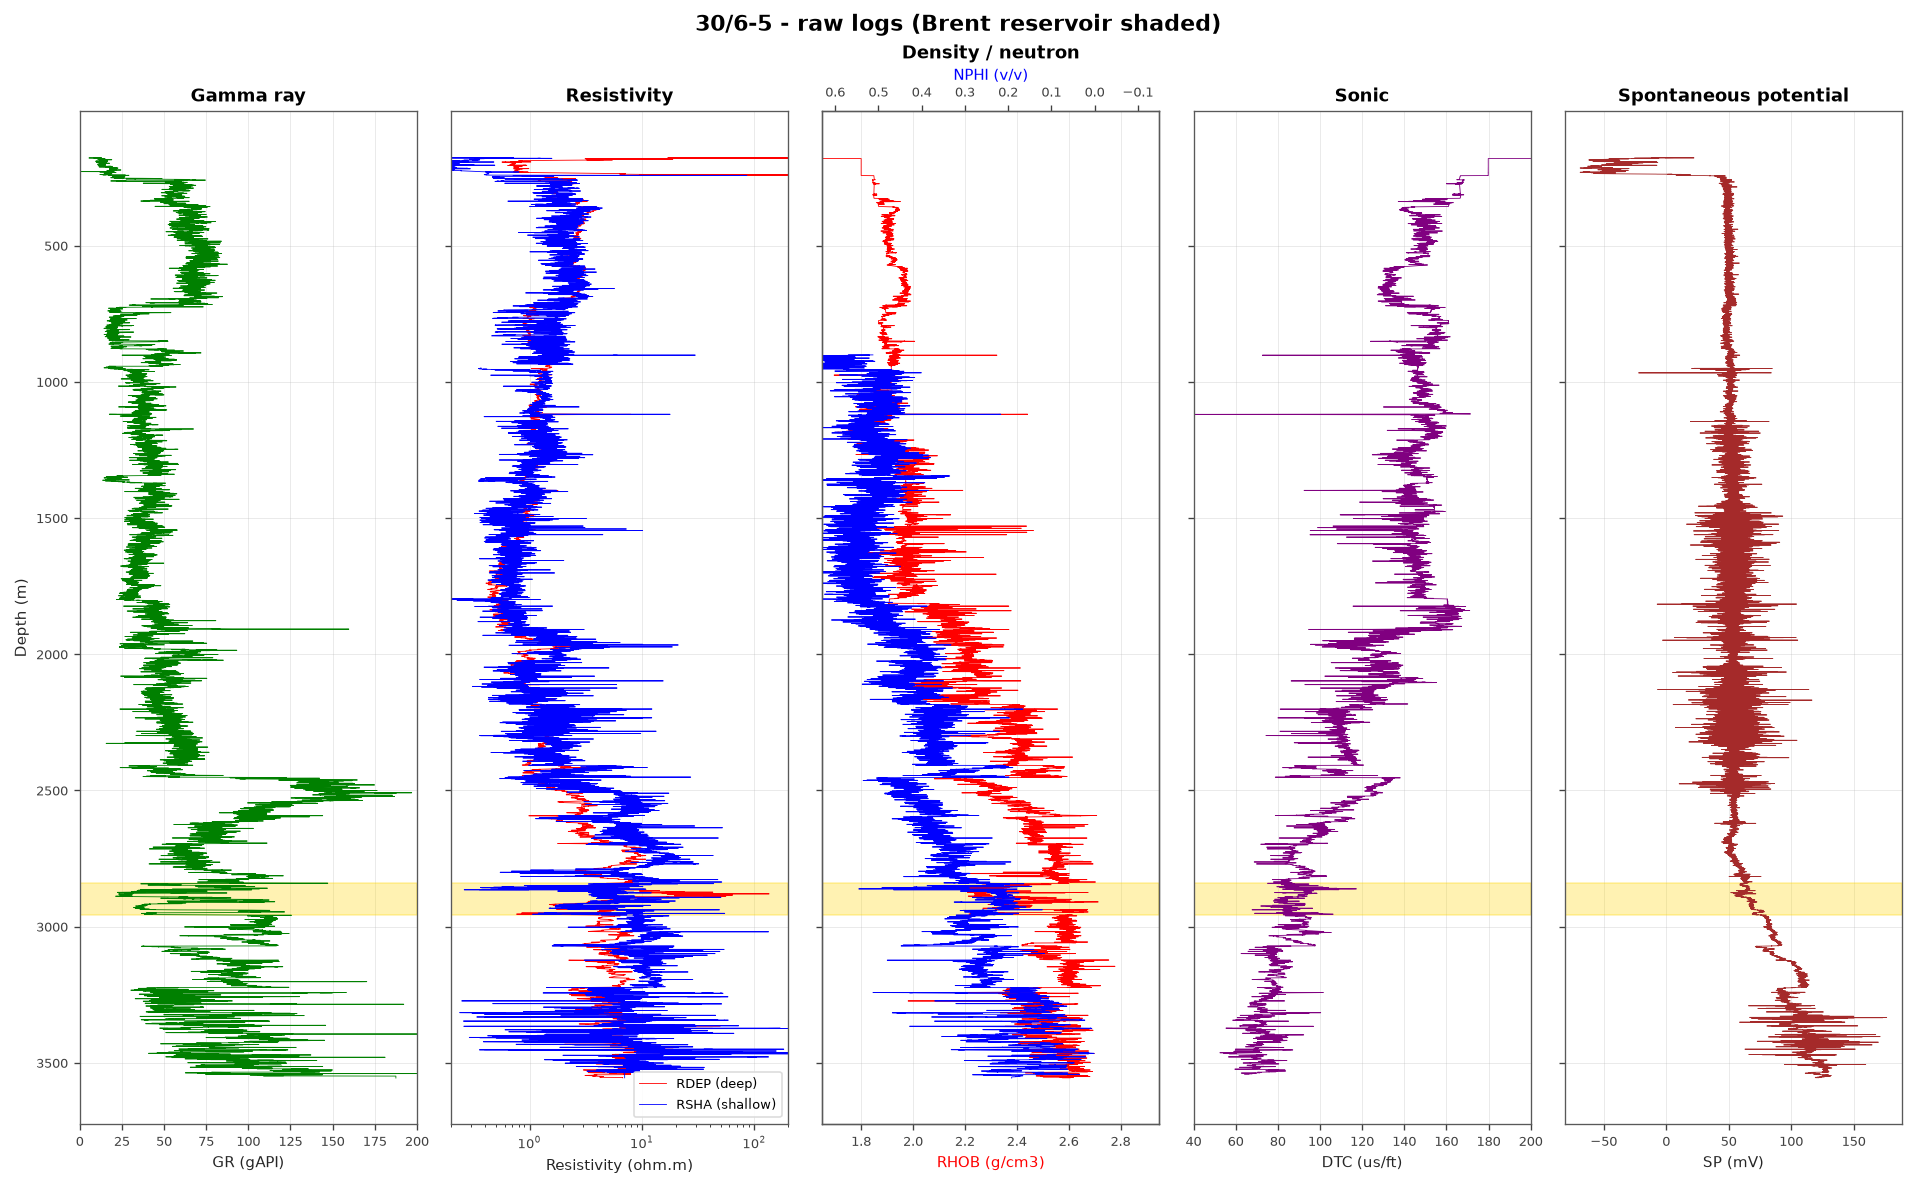

In [6]:
depth = raw.depth
fig, axes = plt.subplots(1, 5, figsize=(16, 10), sharey=True)

ax = axes[0]
ax.plot(raw["GR"].data, depth, color="green", lw=0.5)
ax.set_xlim(0, 200); ax.set_xlabel("GR (gAPI)"); ax.set_ylabel("Depth (m)"); ax.set_title("Gamma ray")

ax = axes[1]
ax.semilogx(raw["RDEP"].data, depth, color="red", lw=0.5, label="RDEP (deep)")
ax.semilogx(raw["RSHA"].data, depth, color="blue", lw=0.5, label="RSHA (shallow)")
ax.set_xlim(0.2, 200); ax.set_xlabel("Resistivity (ohm.m)"); ax.set_title("Resistivity")
ax.legend(fontsize=8, loc="lower right")

ax = axes[2]
ax.plot(raw["RHOB"].data, depth, color="red", lw=0.5)
ax.set_xlim(1.65, 2.95); ax.set_xlabel("RHOB (g/cm3)", color="red"); ax.set_title("Density / neutron")
ax2 = ax.twiny()
ax2.plot(raw["NPHI"].data, depth, color="blue", lw=0.5)
ax2.set_xlim(0.63, -0.15); ax2.set_xlabel("NPHI (v/v)", color="blue")

ax = axes[3]
ax.plot(raw["DTC"].data, depth, color="purple", lw=0.5)
ax.set_xlim(40, 200); ax.set_xlabel("DTC (us/ft)"); ax.set_title("Sonic")

ax = axes[4]
ax.plot(raw["SP"].data, depth, color="brown", lw=0.5)
ax.set_xlabel("SP (mV)"); ax.set_title("Spontaneous potential")

for ax in axes:
    ax.grid(alpha=0.3)
    ax.axhspan(BRENT_TOP, BRENT_BASE, color="gold", alpha=0.3)
axes[0].invert_yaxis()
fig.suptitle(f"{raw.name} - raw logs (Brent reservoir shaded)", fontweight="bold")
plt.tight_layout()
plt.show()

The library's own viewer, `pp.plot`, builds the tracks from whatever curves are
present, including the core plugs as points. We zoom to the reservoir window.

The core saturation curve `SWC` is stored in percent although the LAS labels it
`frac`. For display, `pp.plot` divides it by 100 and records a note in
`viewer.warnings` (printed below the figure); it does not raise a Python
warning, and the curve on the well stays in percent. Section 2 shows what
standardization does with it.

[repository]\src\petrophys\preprocessing\standardization\curve_standardizer.py:758: UserWarning: SWC: inferred percent core saturation despite unit 'frac'; divided by 100 to v/v. Verify source units.
  standardize_core_saturation(new_curve, inplace=True)
[repository]\src\petrophys\preprocessing\standardization\curve_standardizer.py:758: UserWarning: SOC: inferred percent core saturation despite unit 'frac'; divided by 100 to v/v. Verify source units.
  standardize_core_saturation(new_curve, inplace=True)


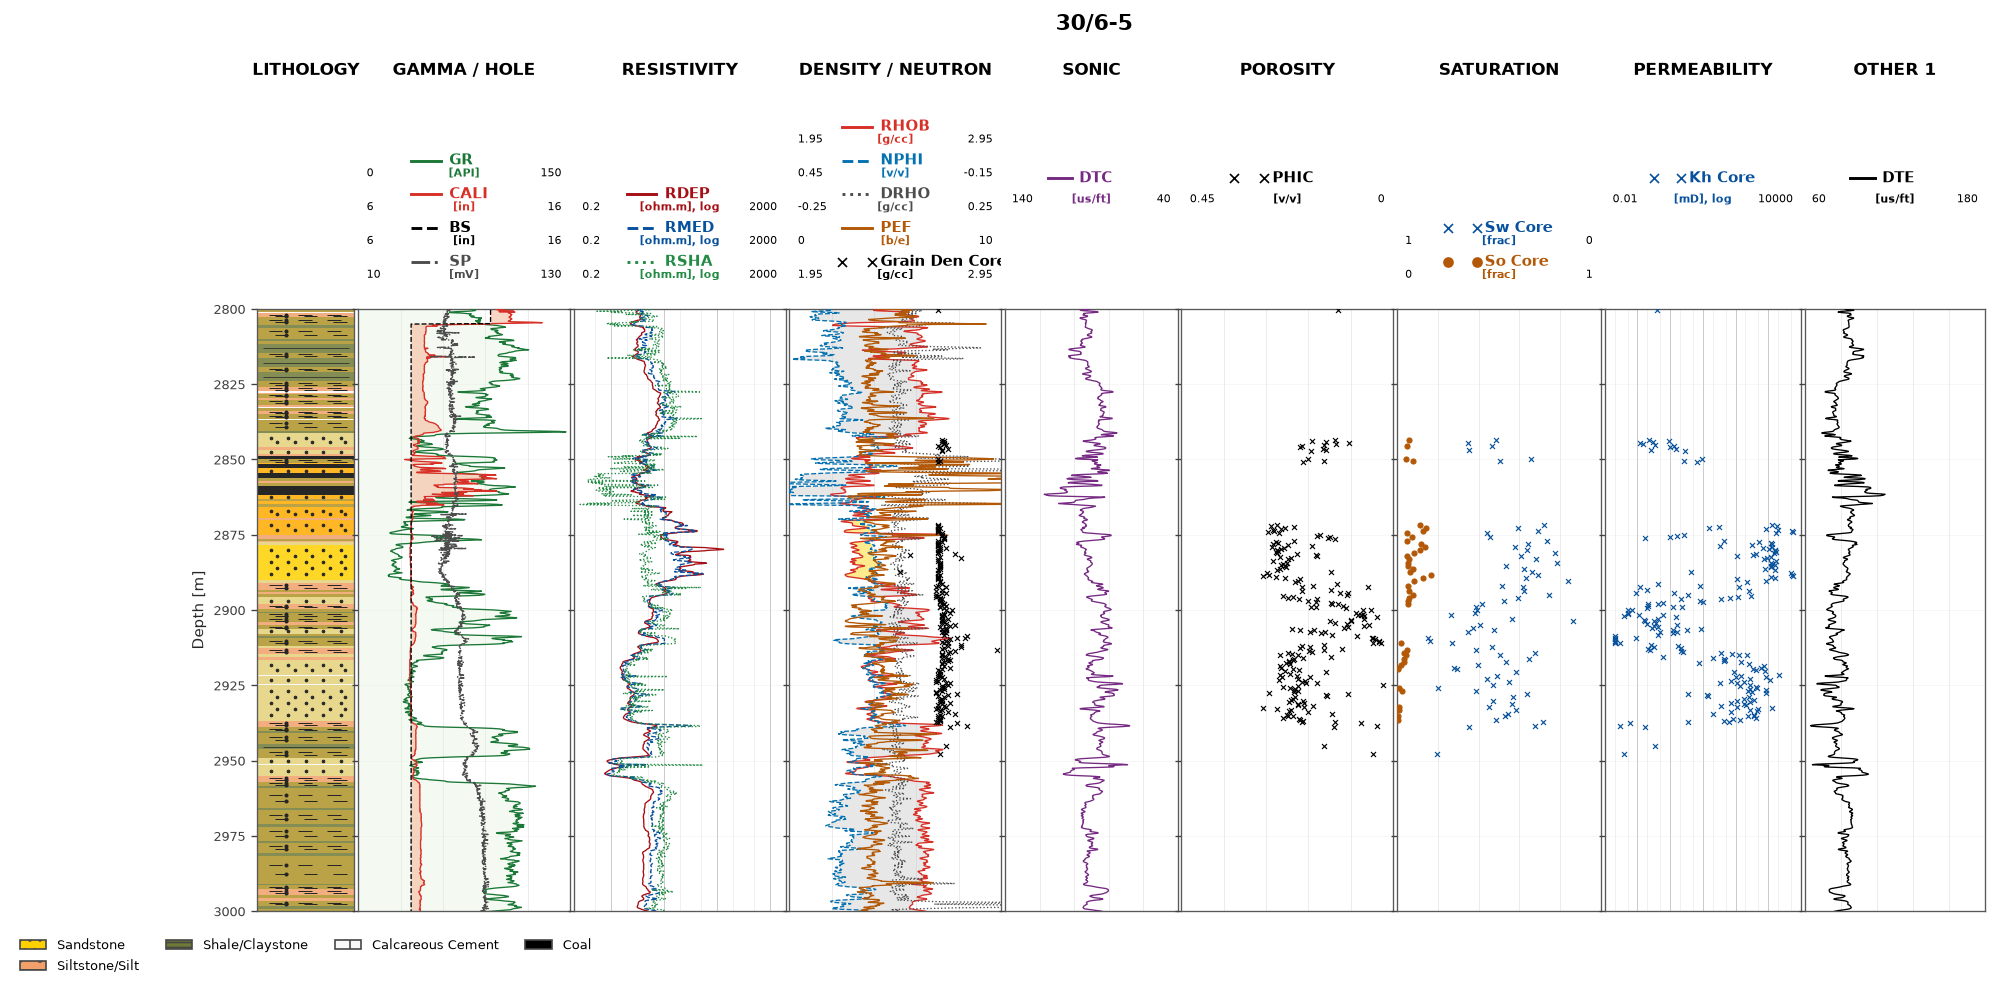

Tracks drawn: ['DEPTH', 'LITHOLOGY', 'GAMMA / HOLE', 'RESISTIVITY', 'DENSITY / NEUTRON', 'SONIC', 'POROSITY', 'SATURATION', 'PERMEABILITY', 'OTHER 1']
Viewer notes: ["SWC: inferred percent core saturation despite unit 'frac'; divided by 100 to v/v. Verify source units.", "SOC: inferred percent core saturation despite unit 'frac'; divided by 100 to v/v. Verify source units."]


In [7]:
viewer = pp.plot(raw, top=WINDOW[0], bottom=WINDOW[1], figsize=(15, 8))
viewer.show()
viewer.close()
print("Tracks drawn:", [track.display_name for track in viewer.template.tracks])
print("Viewer notes:", viewer.warnings)

---
## 2. Curve standardization and quality control

Before any calculation, curves need standard mnemonics and units, implausible
values need screening, and depths in bad hole need flagging.
`CurveStandardizer` maps common aliases to standard names and converts units;
its `report` shows what it would do without changing anything. The GeoLink files
already use standard names, so here it mostly confirms units.

You rarely call these yourself: `pp.interpret` standardizes its input by
default. They are shown so you know what happens first.

In [8]:
from petrophys.preprocessing import CurveStandardizer, standardize_curves

report = CurveStandardizer(rename_curves=True, convert_units=True).report(raw)
print("Curves in file  :", report["total_curves"])
print("Recognised      :", len(report["recognized"]))
print("Not recognised  :", ", ".join(report["unrecognized"]))
print("Duplicates      :", report["duplicates"] or "none")
print("Unit conversions:")
for item in report["unit_conversions"]:
    print(f"   {item['curve']}: {item['from_unit']} -> {item['to_unit']}")

Curves in file  : 20
Recognised      : 14
Not recognised  : LITHOLOGY_GEOLINK, DTE, PHIC, GDEN, KH_CORE, KV_CORE
Duplicates      : none
Unit conversions:
   NPHI: m3/m3 -> v/v
   GR: gAPI -> API
   SWC: frac -> v/v
   SOC: frac -> v/v


The unrecognised curves are the vendor lithology code, a second sonic (`DTE`)
and the core curves; they are kept unchanged. `standardize_curves` applies the
conversions to the well and returns the same object. Note what it does **not**
do: `SWC: frac -> v/v` is a relabel between two names for a fraction, so the
percent values stay as stored and no warning is raised. To get core saturation
as a fraction, convert it explicitly with `standardize_core_saturation`
(`petrophys.preprocessing`) and say that the source is in percent. Sections 6
and 10 do that for their plots; `core_data_from_well` (section 15) does it
itself and warns that it did.

In [9]:
from petrophys.preprocessing import standardize_core_saturation

std = pp.read(pp.sample("30_6-5"))
swc_max_before = np.nanmax(std["SWC"].data)
std = standardize_curves(std)        # modifies and returns the same Well
print(f"SWC maximum: {swc_max_before:.1f} (as stored) -> {np.nanmax(std['SWC'].data):.1f} "
      f"after standardize_curves (unit now {std['SWC'].unit!r}, values unchanged)")
swc_fraction = standardize_core_saturation(std["SWC"], source_unit="%")
print(f"SWC maximum after standardize_core_saturation(source_unit='%'): "
      f"{np.nanmax(swc_fraction.data):.3f} {swc_fraction.unit}")
print("GR unit:", std["GR"].unit, "| NPHI unit:", std["NPHI"].unit)

SWC maximum: 84.6 (as stored) -> 0.8 after standardize_curves (unit now 'v/v', values unchanged)
SWC maximum after standardize_core_saturation(source_unit='%'): 0.008 v/v
GR unit: API | NPHI unit: v/v


[repository]\src\petrophys\preprocessing\standardization\curve_standardizer.py:758: UserWarning: SWC: inferred percent core saturation despite unit 'frac'; divided by 100 to v/v. Verify source units.
  standardize_core_saturation(new_curve, inplace=True)
[repository]\src\petrophys\preprocessing\standardization\curve_standardizer.py:758: UserWarning: SOC: inferred percent core saturation despite unit 'frac'; divided by 100 to v/v. Verify source units.
  standardize_core_saturation(new_curve, inplace=True)


In [10]:
# pp.interpret (section 10) and core_data_from_well (section 15) convert SWC and
# SOC from percent for their own use and emit a UserWarning for each curve.
# The note is explained above, so hide only that message to keep it from
# repeating for every interpretation below; every other warning still shows.
warnings.filterwarnings(
    "ignore", message=r"(SWC|SOC): inferred percent core saturation", category=UserWarning
)

**Value-range QC** replaces physically implausible values with NaN and records
what it changed. `apply_value_range_qc` works in place, so we give it its own
copy of the well.

In [11]:
from petrophys.preprocessing import apply_value_range_qc

qc_well = pp.read(pp.sample("30_6-5"))
qc_report = pd.DataFrame(apply_value_range_qc(qc_well))
print(qc_report.loc[qc_report["changed"] > 0, ["curve", "low", "high", "changed", "below", "above"]]
      .to_string(index=False))

curve   low   high  changed  below  above
 NPHI -0.15    0.6      299      0    299
  PEF  0.00   15.0       35      0     35
   GR  0.00  400.0        3      3      0
 RDEP  0.01 2000.0        9      0      9


**Bad-hole flags** mark depths where pad tools (density, PEF) may read the mud
instead of the rock: caliper well above bit size (washout), large hole, low
density, a high density correction `DRHO`, or implausible PEF.

         flag  whole well (%)  Brent window (%)
      washout            34.0               8.5
   large_hole            23.0               0.0
  low_density            49.8               0.0
pef_exclusion             0.4               6.1
     bad_hole            57.0               8.5


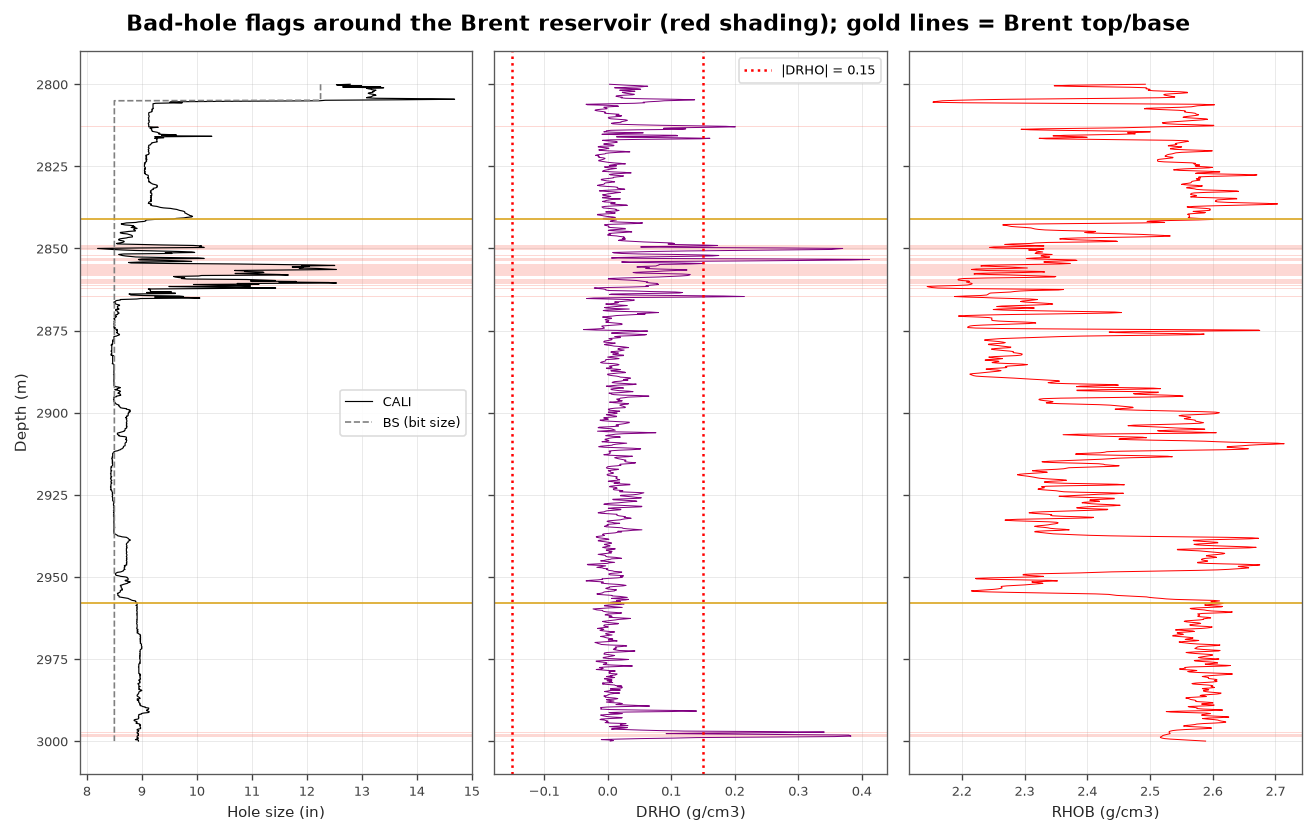

In [12]:
from petrophys.preprocessing import generate_bad_hole_flags

flags = generate_bad_hole_flags(std)
d = std.depth
in_brent = (d >= BRENT_TOP) & (d <= BRENT_BASE)
flag_table = pd.DataFrame([
    {"flag": name, "whole well (%)": 100 * np.mean(values > 0.5),
     "Brent window (%)": 100 * np.mean(values[in_brent] > 0.5)}
    for name, values in flags.items()
])
print(flag_table.round(1).to_string(index=False))

win = (d >= WINDOW[0]) & (d <= WINDOW[1])
bad = flags["bad_hole"][win] > 0.5
fig, axes = plt.subplots(1, 3, figsize=(11, 7), sharey=True)
axes[0].plot(std["CALI"].data[win], d[win], color="black", lw=0.7, label="CALI")
axes[0].plot(std["BS"].data[win], d[win], color="gray", ls="--", lw=1, label="BS (bit size)")
axes[0].set_xlabel("Hole size (in)"); axes[0].set_ylabel("Depth (m)"); axes[0].legend(fontsize=8)
axes[1].plot(std["DRHO"].data[win], d[win], color="purple", lw=0.6)
axes[1].axvline(0.15, color="red", ls=":", label="|DRHO| = 0.15")
axes[1].axvline(-0.15, color="red", ls=":")
axes[1].set_xlabel("DRHO (g/cm3)"); axes[1].legend(fontsize=8)
axes[2].plot(std["RHOB"].data[win], d[win], color="red", lw=0.6)
axes[2].set_xlabel("RHOB (g/cm3)")
for ax in axes:
    ax.fill_betweenx(d[win], 0, 1, where=bad, transform=ax.get_yaxis_transform(),
                     color="salmon", alpha=0.3, lw=0)
    ax.axhline(BRENT_TOP, color="goldenrod", lw=1); ax.axhline(BRENT_BASE, color="goldenrod", lw=1)
    ax.grid(alpha=0.3)
axes[0].invert_yaxis()
fig.suptitle("Bad-hole flags around the Brent reservoir (red shading); gold lines = Brent top/base",
             fontweight="bold")
plt.tight_layout()
plt.show()

The whole-well percentages are dominated by the top hole section, where the
bit is large and the sediment soft. Inside the reservoir window the combined
flag covers a short washed-out stretch of the Ness Fm. at the top of the Brent;
treat density-based porosity there with suspicion. The workflow in section 10
runs the same checks, stores the combined flag as a `BAD_HOLE` curve, which
`pp.plot` shades, and leaves those samples out of net reservoir and net pay.

---
## 3. Linking lithology and formation tops to the log data

Formation tops and lithology intervals are optional context: plots can label
them, interval summaries need them, and the interpretation can use lithology to
choose matrix properties. `pp.read(..., formations=..., lithology=...)` attaches
both when reading; `pp.read_formations` and `petrophys.io.read_lithology_intervals` load
them as validated tables. They accept CSV, Excel or a DataFrame, map column
names, and check depth units against the well.

The bundled 30/6-5 tops mix **groups** and their member **formations**, so some
rows overlap (the `BAAT GP.` row covers both Ness and Etive). The `rank` column
says which is which.

In [13]:
well = pp.read(pp.sample("30_6-5"), formations=FM_CSV, lithology=LITH_CSV)
well = standardize_curves(well)      # our working well for sections 3-9

tops_table = pp.read_formations(FM_CSV, well=well)
print("Rows:", len(tops_table), "| by rank:", tops_table["rank"].value_counts().to_dict())
for note in tops_table.attrs["import_report"]["diagnostics"]:
    print("note:", note)
tops_table

Rows: 20 | by rank: {'formation': 12, 'group': 8}
note: No geology depth_reference supplied; assumed to match the well (not independently verified).
note: No geology datum supplied; assumed to match the well (not independently verified).


,formation_name,top_depth,bottom_depth,lithology,rank,parent,depth_unit
0,NORDLAND GP.,181.0,726.0,Shale,group,,m
1,Utsira Fm.,726.0,879.0,Sandstone,formation,,m
2,HORDALAND GP.,879.0,1908.0,Shale,group,,m
3,ROGALAND GP.,1908.0,2203.0,Shale,group,,m
4,Balder Fm.,1908.0,2023.0,Sandstone,formation,ROGALAND GP.,m
5,Sele Fm.,2023.0,2123.0,Shale,formation,ROGALAND GP.,m
6,Lista Fm.,2123.0,2203.0,Shale,formation,ROGALAND GP.,m
7,SHETLAND GP.,2203.0,2408.0,Chalk,group,,m
8,CROMER KNOLL GP.,2408.0,2452.0,Marl,group,,m
9,VIKING GP.,2452.0,2841.0,Shale,group,,m


The two notes are honest bookkeeping: the CSV does not say whether its depths
are measured depth from the same datum as the log, so the reader assumes they
are and says so.

To label every log sample, pick one non-overlapping level (`rank="formation"`)
and look each depth up in the interval table with `label_depths` (in
`petrophys.model`, also exported from `petrophys.evaluation.intervals`). It
finds the table's top, bottom and name columns, gives each interval
`top <= depth < bottom`, and refuses overlapping intervals unless you ask for
the thinnest or thickest one (`overlap="thinnest"` / `"thickest"`). The vendor lithology
curve `LITHOLOGY_GEOLINK` stores numeric codes; `LITHOLOGY_CODE_LABELS`
is the built-in code table the log viewer uses to name them.

In [14]:
from petrophys.evaluation.intervals import label_depths
from petrophys.io import read_lithology_intervals
from petrophys.visualization.log_viewer import LITHOLOGY_CODE_LABELS

fm_table = pp.read_formations(FM_CSV, well=well, rank="formation")
lith_table = read_lithology_intervals(LITH_CSV, well=well)

codes = well["LITHOLOGY_GEOLINK"].data
vendor_names = np.array(
    [LITHOLOGY_CODE_LABELS.get(int(round(c)), "") if np.isfinite(c) else "" for c in codes],
    dtype=object,
)
samples = pd.DataFrame({
    "DEPTH": well.depth,
    "FORMATION": label_depths(well, fm_table),
    "LITHOLOGY (intervals)": label_depths(well, lith_table, label="lithology"),
    "LITHOLOGY (vendor code)": vendor_names,
    "GR": well["GR"].data,
})
print(samples[samples["DEPTH"].between(2836.0, 2872.0)].iloc[::18].round(2).to_string(index=False))

  DEPTH   FORMATION LITHOLOGY (intervals) LITHOLOGY (vendor code)     GR
2836.14 Heather Fm.                 shale              Shaly Silt  89.94
2838.89 Heather Fm.                 shale              Shaly Silt  90.31
2841.63    Ness Fm.             sandstone              Silty Sand  58.62
2844.37    Ness Fm.             sandstone              Silty Sand  44.19
2847.12    Ness Fm.             sandstone              Silty Sand  46.12
2849.86    Ness Fm.             sandstone              Shaly Silt  96.12
2852.60    Ness Fm.             sandstone                    Coal  93.88
2855.34    Ness Fm.             sandstone                    Coal  87.88
2858.09    Ness Fm.             sandstone              Shaly Silt  86.06
2860.83    Ness Fm.             sandstone                    Coal 100.06
2863.57    Ness Fm.             sandstone              Shaly Silt  97.62
2866.32   Etive Fm.             sandstone        Cross Bedded Sst  48.47
2869.06   Etive Fm.             sandstone        Cr

The vendor curve only covers part of the well. We count its labels and group
them into three broad classes. A `Well` stores numeric arrays, so the class
goes on the well as a numeric code curve while the names stay in Python.

In [15]:
CARBONATE = {"Chalk", "Porous Limestone", "Limestone", "Argillaceous Limestone",
             "Marlstone", "Calcareous Cement", "Dolomite"}
OTHER = {"Coal", "Cinerite", "Volcanic Tuff", "Volcanic Rock", "Halite", "Anhydrite"}


def lithology_class(name):
    if not name:
        return np.nan                # no vendor code at this depth
    if name in CARBONATE:
        return 2.0
    if name in OTHER:
        return 3.0
    return 1.0                       # sandstones, silts and shales


class_code = np.array([lithology_class(n) for n in vendor_names])
well.add_curve("LITH_CLASS", class_code, "", "Vendor lithology class: 1 clastic, 2 carbonate, 3 other")

coded = vendor_names != ""
print(f"Samples with a vendor code: {coded.sum()} of {well.n_samples} "
      f"({well.depth[coded].min():.0f} - {well.depth[coded].max():.0f} m)")
for value, label in [(1.0, "clastic"), (2.0, "carbonate"), (3.0, "coal / volcanic / other")]:
    print(f"   {label:<24s} {np.sum(class_code == value):6d} samples")
print("\nMost common vendor labels:")
print(pd.Series(vendor_names[coded]).value_counts().head(8).to_string())

Samples with a vendor code: 10732 of 22176 (1910 - 3545 m)
   clastic                    8638 samples
   carbonate                  1783 samples
   coal / volcanic / other     311 samples

Most common vendor labels:
Shaly Silt                3599
Silt                      2407
Marlstone                 1301
Silty Shale               1172
Cross Bedded Sst          1038
Silty Sand                 345
Cinerite                   264
Argillaceous Limestone     263


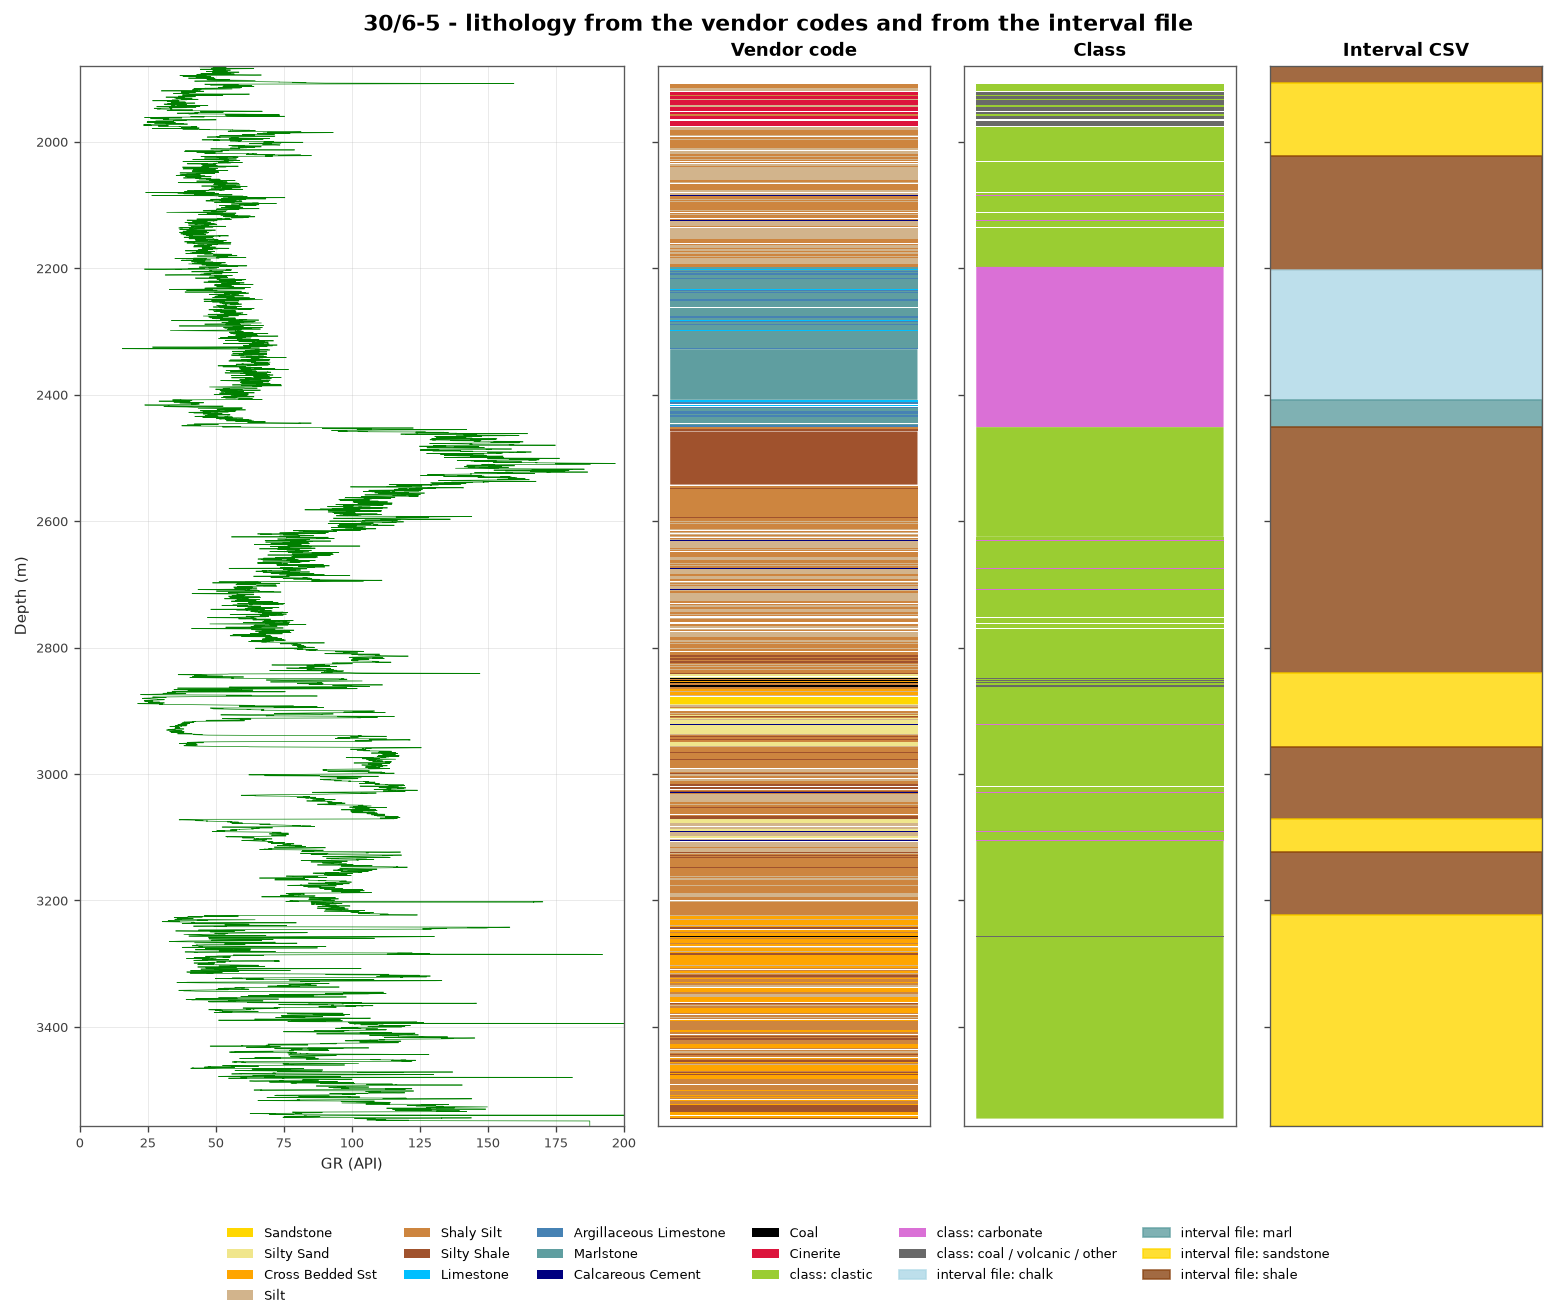

In [16]:
LITH_COLORS = {
    "Sandstone": "gold", "Silty Sand": "khaki", "Cross Bedded Sst": "orange",
    "Sandy Silt": "burlywood", "Silt": "tan", "Shaly Silt": "peru",
    "Silty Shale": "sienna", "Shale": "saddlebrown", "Chalk": "lightblue",
    "Limestone": "deepskyblue", "Argillaceous Limestone": "steelblue", "Marlstone": "cadetblue",
    "Calcareous Cement": "navy", "Coal": "black", "Cinerite": "crimson",
}
INTERVAL_COLORS = {"sandstone": "gold", "shale": "saddlebrown", "chalk": "lightblue", "marl": "cadetblue"}

d = well.depth
show = d >= 1880.0
fig, axes = plt.subplots(1, 4, figsize=(13, 11), sharey=True,
                         gridspec_kw={"width_ratios": [2, 1, 1, 1]})
axes[0].plot(well["GR"].data[show], d[show], color="green", lw=0.4)
axes[0].set_xlim(0, 200); axes[0].set_xlabel("GR (API)"); axes[0].set_ylabel("Depth (m)")
axes[0].grid(alpha=0.3)

for name, color in LITH_COLORS.items():
    mask = (vendor_names == name) & show
    if mask.any():
        axes[1].fill_betweenx(d[show], 0, 1, where=mask[show], color=color, lw=0, label=name)
axes[1].set_title("Vendor code")

for value, color, label in [(1.0, "yellowgreen", "class: clastic"), (2.0, "orchid", "class: carbonate"),
                            (3.0, "dimgray", "class: coal / volcanic / other")]:
    axes[2].fill_betweenx(d[show], 0, 1, where=(class_code == value)[show], color=color, lw=0, label=label)
axes[2].set_title("Class")

for row in lith_table.itertuples():
    axes[3].axhspan(row.top, row.bottom, color=INTERVAL_COLORS.get(row.lithology, "gray"), alpha=0.8)
axes[3].set_title("Interval CSV")
for ax in axes[1:]:
    ax.set_xticks([])
axes[0].set_ylim(d[show].max(), d[show].min())
handles, labels = [], []
for ax in axes[1:3]:
    h, l = ax.get_legend_handles_labels()
    handles += h; labels += l
from matplotlib.patches import Patch
for lith in sorted(set(lith_table["lithology"])):
    handles.append(Patch(color=INTERVAL_COLORS.get(lith, "gray"), alpha=0.8))
    labels.append(f"interval file: {lith}")
fig.legend(handles, labels, loc="lower center", ncol=6, fontsize=8, frameon=False)
fig.suptitle(f"{well.name} - lithology from the vendor codes and from the interval file", fontweight="bold")
plt.tight_layout(rect=(0, 0.09, 1, 1))
plt.show()

The vendor codes resolve thin beds (silts inside the Brent sands, a coal in the
Ness), while the interval file is a coarse column with one lithology per
formation-scale interval. Both are useful: the codes for detail, the intervals
for labelling and for the interpretation's matrix choice.

Now the formation tops over the whole well, groups and member formations side
by side.

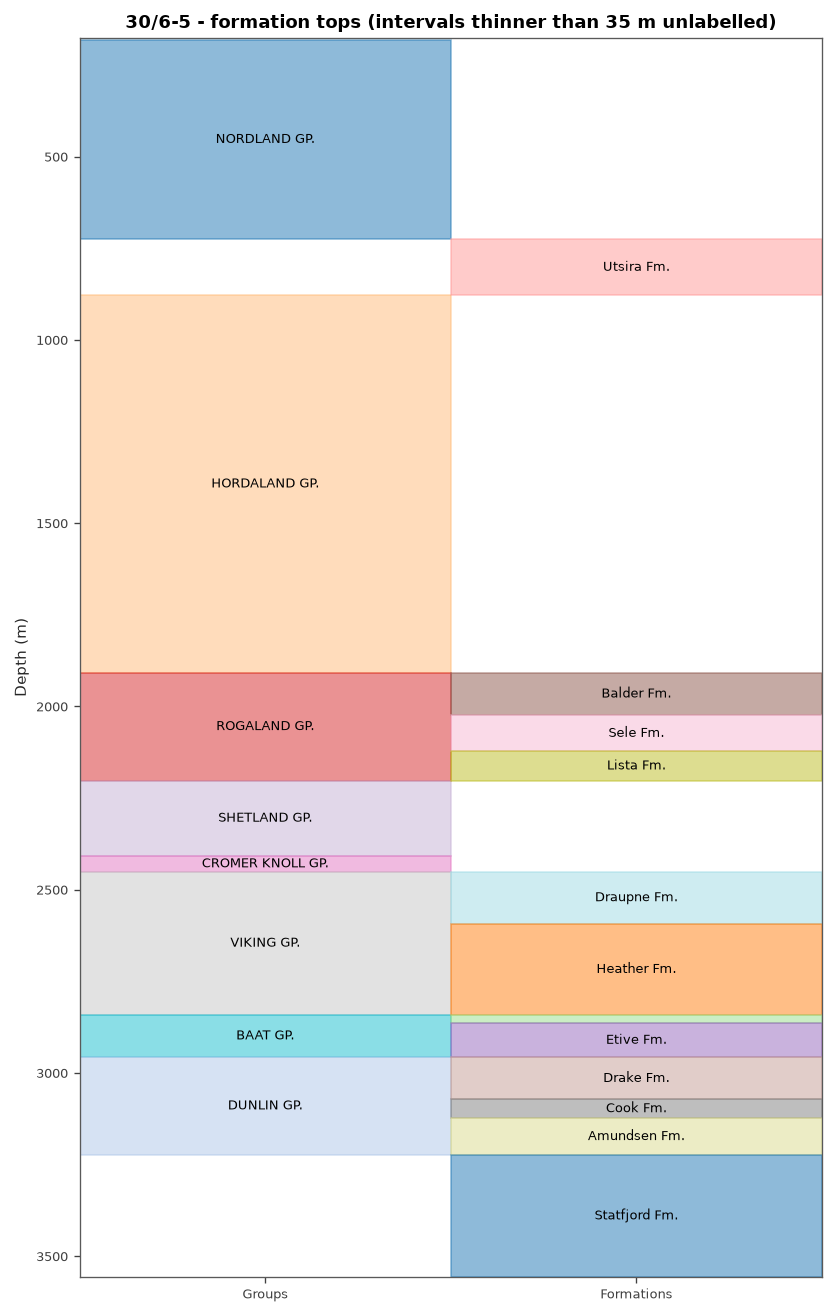

In [17]:
groups = tops_table[tops_table["rank"] == "group"]
formations = tops_table[tops_table["rank"] == "formation"]
palette = plt.cm.tab20(np.linspace(0, 1, len(tops_table)))

fig, ax = plt.subplots(figsize=(7, 11))
for column, table in [(0, groups), (1, formations)]:
    for i, row in enumerate(table.itertuples()):
        color = palette[(i * 3 + column * 7) % len(palette)]
        ax.axhspan(row.top_depth, row.bottom_depth, xmin=column / 2, xmax=(column + 1) / 2,
                   color=color, alpha=0.5)
        if row.bottom_depth - row.top_depth > 35:
            ax.text(column + 0.5, 0.5 * (row.top_depth + row.bottom_depth), row.formation_name,
                    ha="center", va="center", fontsize=8)
ax.set_xlim(0, 2); ax.set_xticks([0.5, 1.5]); ax.set_xticklabels(["Groups", "Formations"])
ax.set_ylim(well.bottom, well.top); ax.set_ylabel("Depth (m)")
ax.set_title(f"{well.name} - formation tops (intervals thinner than 35 m unlabelled)")
plt.tight_layout()
plt.show()

---
## 4. Clay volume (VCL)

Clay volume drives every later step: it corrects porosity, feeds the shaly-sand
saturation models and is the first net-pay cutoff. `petrophys.interpretation.clay_volume`
offers:

- **Gamma ray**: a linear gamma-ray index IGR = (GR - GR_clean) / (GR_shale - GR_clean),
  optionally bent by the Larionov (Tertiary or older rocks), Steiber or Clavier
  curves, which all give less clay than the linear index;
- **SP**: from the spontaneous-potential deflection;
- **Neutron-density**: from the separation of the two porosity logs.

The GR endpoints are a choice. We take the 5th and 95th GR percentiles over the
Jurassic section (Heather Fm. top at 2593 m to TD), which holds both the
reservoir sands and the shales around them.

GR endpoints: clean = 39.2 API, shale = 119.6 API

Mean VCL over the Brent window:
   Linear (IGR)           0.284
   Larionov, Tertiary     0.161
   Larionov, older rocks  0.211
   Steiber                0.173
   Clavier                0.199


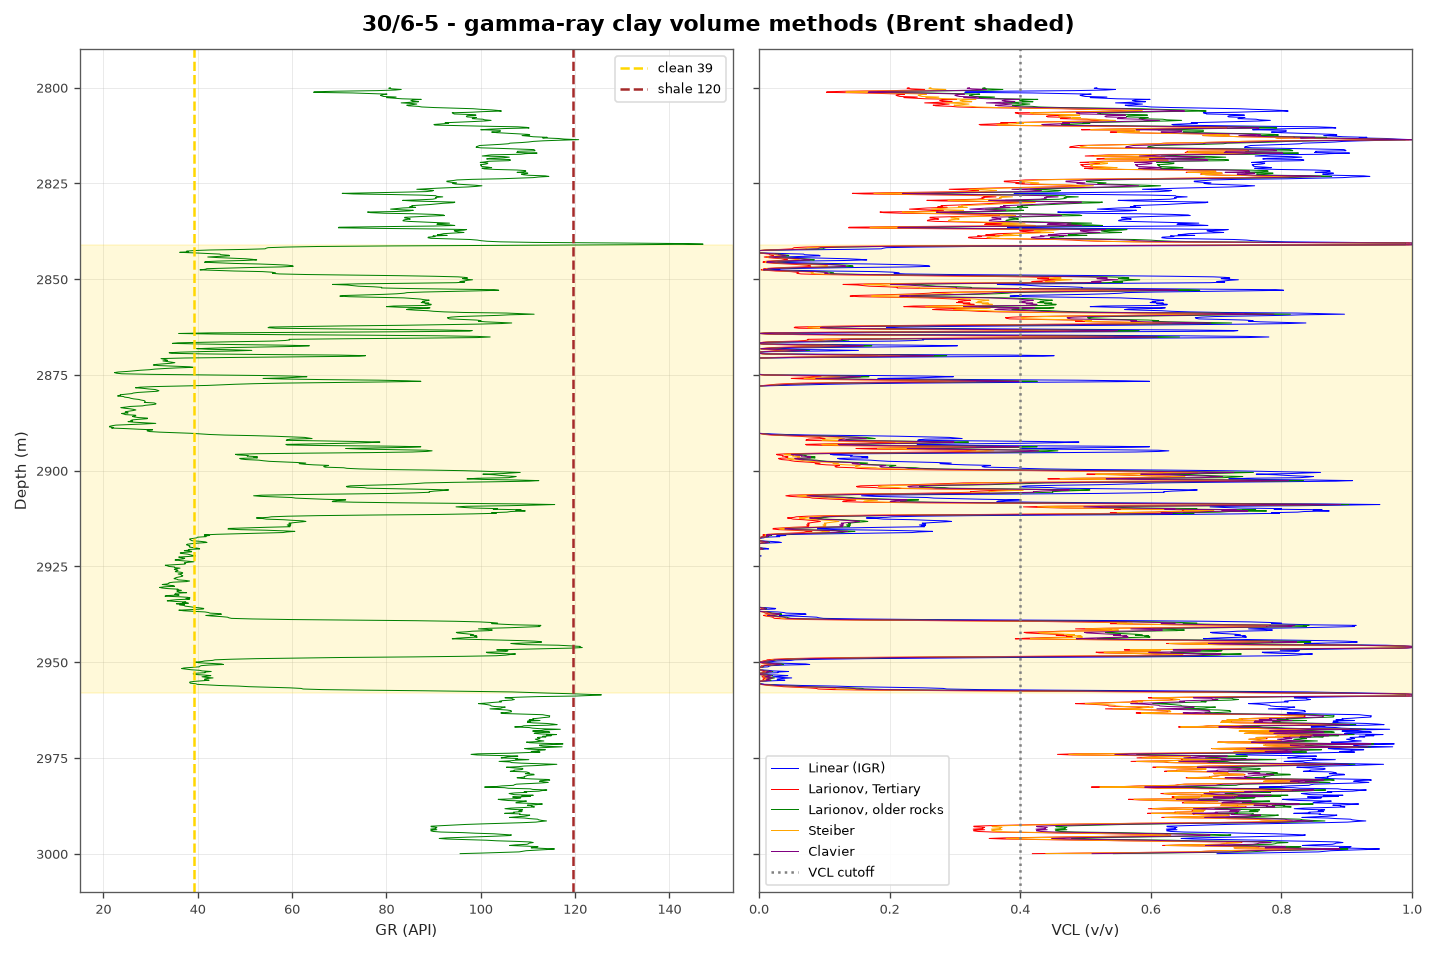

In [18]:
from petrophys.interpretation.clay_volume import (
    vcl_linear, vcl_larionov_tertiary, vcl_larionov_older, vcl_steiber, vcl_clavier,
    vcl_from_gr, VclModule, calculate_vcl,
)

depth = well.depth
gr = well["GR"].data
jurassic = depth >= 2593.0
in_brent = (depth >= BRENT_TOP) & (depth <= BRENT_BASE)
win = (depth >= WINDOW[0]) & (depth <= WINDOW[1])

gr_min = float(np.nanpercentile(gr[jurassic], 5))
gr_max = float(np.nanpercentile(gr[jurassic], 95))
print(f"GR endpoints: clean = {gr_min:.1f} API, shale = {gr_max:.1f} API")

igr = vcl_linear(gr, gr_min, gr_max)
vcl_methods = {
    "Linear (IGR)": igr,
    "Larionov, Tertiary": vcl_larionov_tertiary(igr),
    "Larionov, older rocks": vcl_larionov_older(igr),
    "Steiber": vcl_steiber(igr),
    "Clavier": vcl_clavier(igr),
}
print("\nMean VCL over the Brent window:")
for name, values in vcl_methods.items():
    print(f"   {name:<22s} {np.nanmean(values[in_brent]):.3f}")

fig, axes = plt.subplots(1, 2, figsize=(12, 8), sharey=True)
axes[0].plot(gr[win], depth[win], color="green", lw=0.6)
axes[0].axvline(gr_min, color="gold", ls="--", label=f"clean {gr_min:.0f}")
axes[0].axvline(gr_max, color="brown", ls="--", label=f"shale {gr_max:.0f}")
axes[0].set_xlabel("GR (API)"); axes[0].set_ylabel("Depth (m)"); axes[0].legend(fontsize=8)
for (name, values), color in zip(vcl_methods.items(), ["blue", "red", "green", "orange", "purple"]):
    axes[1].plot(values[win], depth[win], color=color, lw=0.6, label=name)
axes[1].axvline(CUTOFFS["vcl_cutoff"], color="gray", ls=":", label="VCL cutoff")
axes[1].set_xlim(0, 1); axes[1].set_xlabel("VCL (v/v)"); axes[1].legend(fontsize=8)
for ax in axes:
    ax.axhspan(BRENT_TOP, BRENT_BASE, color="gold", alpha=0.15); ax.grid(alpha=0.3)
axes[0].invert_yaxis()
fig.suptitle(f"{well.name} - gamma-ray clay volume methods (Brent shaded)", fontweight="bold")
plt.tight_layout()
plt.show()

`VclModule` combines the gamma-ray, SP and neutron-density estimates and, by
default, keeps the **minimum** at each depth, on the reasoning that each
indicator can only overestimate clay (radioactive feldspar raises GR, for
example). The flip side: one indicator that reads too low anywhere wins
everywhere it does. So look at each estimate in a few known intervals before
trusting the combination. We use the linear gamma-ray index, the method the
workflow also uses by default.

One detail to know: the module's gamma-ray step uses `vcl_from_gr`, which
widens the endpoints to at most 20 API (clean) and at least 100 API (shale).
The check at the end of the cell makes that visible.

In [19]:
vcl_all = VclModule(gr_min=gr_min, gr_max=gr_max, gr_method="linear",
                    use_sp=True, use_nd=True).calculate(well)
sp = well["SP"].data
check = {"Draupne Fm. (organic shale)": (2452.0, 2593.0), "Heather Fm. (mudstone)": (2593.0, 2841.0),
         "Etive Fm. (sandstone)": (2865.0, 2958.0), "Statfjord Fm. (sandstone)": (3223.0, 3556.0)}
rows = []
for label, (top, base) in check.items():
    sel = (depth >= top) & (depth < base)
    rows.append({"interval": label, "GR median": np.nanmedian(gr[sel]), "SP median (mV)": np.nanmedian(sp[sel]),
                 "VCL from GR": np.nanmean(vcl_all.vcl_gr[sel]), "from SP": np.nanmean(vcl_all.vcl_sp[sel]),
                 "from N-D": np.nanmean(vcl_all.vcl_nd[sel]), "min of the three": np.nanmean(vcl_all.vcl[sel])})
print(pd.DataFrame(rows).round(3).to_string(index=False))

clamped = vcl_from_gr(gr, gr_min, gr_max, method="linear")
print("\nvcl_gr equals vcl_from_gr with clamped endpoints:",
      np.allclose(vcl_all.vcl_gr, clamped, equal_nan=True),
      f"(effective endpoints {min(gr_min, 20.0):.0f} / {max(gr_max, 100.0):.1f} API)")

                   interval  GR median  SP median (mV)  VCL from GR  from SP  from N-D  min of the three
Draupne Fm. (organic shale)    134.750          54.207        0.936    0.166     0.615             0.166
     Heather Fm. (mudstone)     76.554          54.449        0.492    0.175     0.709             0.173
      Etive Fm. (sandstone)     43.500          67.667        0.242    0.346     0.178             0.124
  Statfjord Fm. (sandstone)     80.125         111.206        0.522    0.913     0.190             0.188

vcl_gr equals vcl_from_gr with clamped endpoints: True (effective endpoints 20 / 119.6 API)


The table shows both why the minimum rule exists and how it can fail. In the
Statfjord sandstone the gamma ray reads high for a sand while the
neutron-density estimate is much lower, and the minimum rightly ignores the
gamma ray. But the SP estimate calls the Draupne shale nearly clean. Look at
the SP medians:
the SP baseline drifts by tens of millivolts down the well and hardly separates
the Draupne shale from the Etive sand, so endpoints picked over the whole well
mean nothing at any one depth. Taking the minimum would hand that error to the
combined curve, and the shale would pass the clay cutoff. We switch the SP
estimate off and combine gamma ray and neutron-density only - the choice the
workflow also makes unless you give it both SP baselines (section 10).
`add_to_well` writes the combined curve as `VCL`, plus the individual estimates.

In [20]:
vcl_module = VclModule(gr_min=gr_min, gr_max=gr_max, gr_method="linear", use_sp=False, use_nd=True)
vcl_result = vcl_module.calculate(well)
print("Combination rule:", vcl_module.combine)
print("Mean VCL over the Brent window:")
for name in ["vcl_gr", "vcl_nd", "vcl"]:
    print(f"   {name:<7s} {np.nanmean(getattr(vcl_result, name)[in_brent]):.3f}")

vcl_module.add_to_well(well, vcl_result)
print("VCL curves on the well:", [c for c in well.curves if c.startswith("VCL")])

Combination rule: min
Mean VCL over the Brent window:
   vcl_gr  0.284
   vcl_nd  0.195
   vcl     0.175
VCL curves on the well: ['VCL', 'VCLAY', 'VCL_GR', 'VCLGR', 'VCL_ND', 'VCLND']


`calculate_vcl` is the one-line form (module, calculate and result in one call),
handy for a quick look with another gamma-ray transform. The non-linear
transforms give less clay than the linear index, so a cutoff is only meaningful
together with the VCL method it was chosen for.

In [21]:
quick = calculate_vcl(well, gr_min=gr_min, gr_max=gr_max, gr_method="steiber", use_sp=False)
print(f"Steiber-based combined VCL, Brent mean: {np.nanmean(quick.vcl[in_brent]):.3f}")
print(f"Linear-index combined VCL, Brent mean : {np.nanmean(well['VCL'].data[in_brent]):.3f}  <- kept")

Steiber-based combined VCL, Brent mean: 0.143
Linear-index combined VCL, Brent mean : 0.175  <- kept


---
## 5. Porosity

`petrophys.interpretation.porosity` provides:

- **Density porosity** PHID = (rho_ma - RHOB) / (rho_ma - rho_fl);
- **Sonic porosity** PHIS from the Wyllie time average;
- **Total porosity** PHIT, an adaptive combination of neutron and density
  porosity that falls back to density where the neutron is missing;
- **Effective porosity** PHIE = PHIT - VCL x phi_clay, removing clay-bound water.

The matrix density is the key assumption. 30/6-5 has measured core grain
density; the cell prints its median so you can judge the quartz value of
2.65 g/cm3 we use (section 15 uses the measured values directly). The clay
porosity phi_clay = 0.15 is the library default.

In [22]:
from petrophys.interpretation.porosity import (
    density_porosity, sonic_porosity, total_porosity, effective_porosity, PorosityModule,
)

gden = well["GDEN"].data
print(f"Core grain density: median {np.nanmedian(gden):.3f} g/cm3 from {np.isfinite(gden).sum()} plugs")

RHO_MA, RHO_FL, PHI_CLAY = 2.65, 1.0, 0.15
vcl = well["VCL"].data
phid = density_porosity(well["RHOB"].data, rhob_matrix=RHO_MA, rhob_fluid=RHO_FL)
phis = sonic_porosity(well["DTC"].data, matrix="sandstone")
phit = total_porosity(well["NPHI"].data, phid, method="adaptive")
phie = effective_porosity(phit, vcl, phi_clay=PHI_CLAY)

for name, values, description in [("PHID", phid, "Density porosity"), ("PHIS", phis, "Sonic porosity"),
                                  ("PHIT", phit, "Total porosity (N-D)"),
                                  ("PHIE", phie, "Effective porosity")]:
    well.add_curve(name, values, "v/v", description)
    print(f"{name}: Brent mean {np.nanmean(values[in_brent]):.3f}, "
          f"whole-well range {np.nanmin(values):.2f} - {np.nanmax(values):.2f}")

Core grain density: median 2.670 g/cm3 from 200 plugs
PHID: Brent mean 0.159, whole-well range 0.00 - 0.50
PHIS: Brent mean 0.247, whole-well range 0.00 - 0.50
PHIT: Brent mean 0.192, whole-well range 0.00 - 0.50
PHIE: Brent mean 0.166, whole-well range 0.00 - 0.50


`PorosityModule` runs the same chain from the curves on the well. Given the same
VCL it reproduces our effective porosity; use it when you want every porosity
type at once.

In [23]:
porosity_result = PorosityModule(matrix="sandstone", rhob_fluid=RHO_FL, phi_clay=PHI_CLAY).calculate(
    well, vcl=vcl)
print("Result fields:", [f for f in ("phid", "phis", "phit", "phie", "phi_sec") if hasattr(porosity_result, f)])
print("Largest |PHIE difference| vs the step-by-step result:",
      f"{np.nanmax(np.abs(porosity_result.phie - phie)):.2e}")

Result fields: ['phid', 'phis', 'phit', 'phie', 'phi_sec']
Largest |PHIE difference| vs the step-by-step result: 0.00e+00


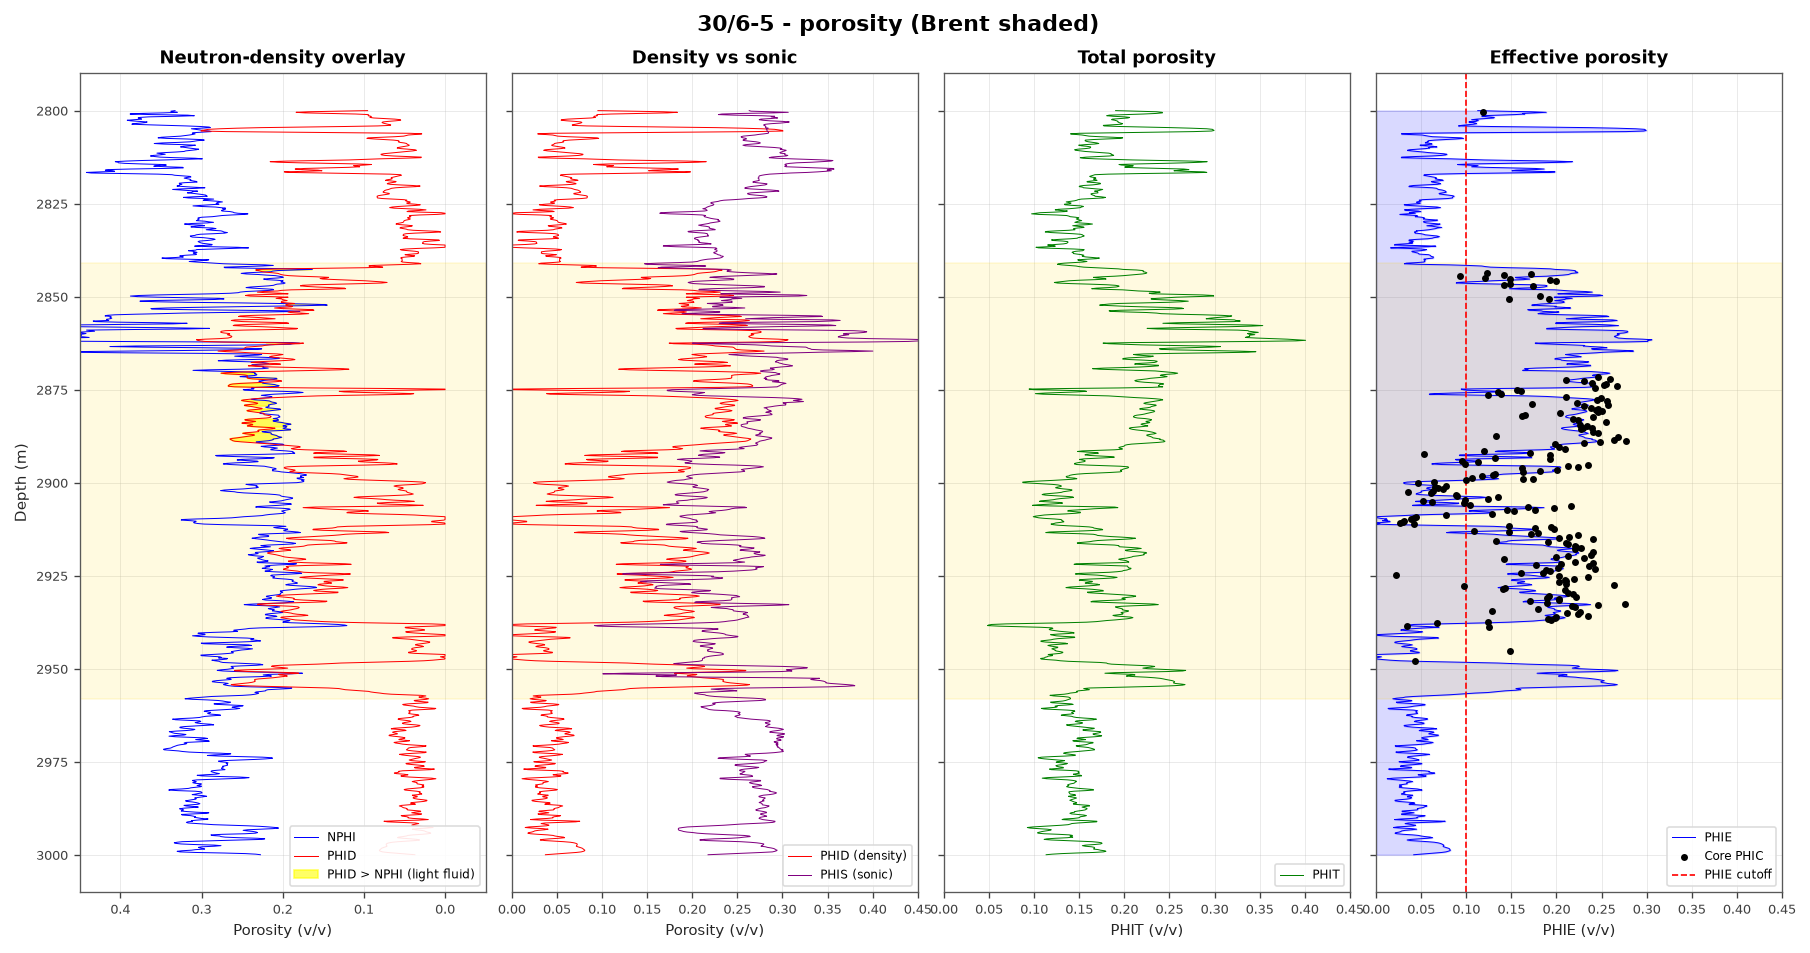

In [24]:
phic = well["PHIC"].data
nphi = well["NPHI"].data
fig, axes = plt.subplots(1, 4, figsize=(15, 8), sharey=True)

ax = axes[0]
ax.plot(nphi[win], depth[win], color="blue", lw=0.6, label="NPHI")
ax.plot(phid[win], depth[win], color="red", lw=0.6, label="PHID")
ax.fill_betweenx(depth[win], nphi[win], phid[win], where=(phid > nphi + 0.02)[win],
                 color="yellow", alpha=0.6, label="PHID > NPHI (light fluid)")
ax.set_xlim(0.45, -0.05); ax.set_xlabel("Porosity (v/v)"); ax.set_ylabel("Depth (m)")
ax.set_title("Neutron-density overlay")

ax = axes[1]
ax.plot(phid[win], depth[win], color="red", lw=0.6, label="PHID (density)")
ax.plot(phis[win], depth[win], color="purple", lw=0.6, label="PHIS (sonic)")
ax.set_xlim(0, 0.45); ax.set_xlabel("Porosity (v/v)"); ax.set_title("Density vs sonic")

ax = axes[2]
ax.plot(phit[win], depth[win], color="green", lw=0.6, label="PHIT")
ax.set_xlim(0, 0.45); ax.set_xlabel("PHIT (v/v)"); ax.set_title("Total porosity")

ax = axes[3]
ax.plot(phie[win], depth[win], color="blue", lw=0.6, label="PHIE")
ax.fill_betweenx(depth[win], 0, phie[win], color="blue", alpha=0.15)
ax.scatter(phic[win], depth[win], s=10, color="black", zorder=3, label="Core PHIC")
ax.axvline(CUTOFFS["phie_cutoff"], color="red", ls="--", lw=1, label="PHIE cutoff")
ax.set_xlim(0, 0.45); ax.set_xlabel("PHIE (v/v)"); ax.set_title("Effective porosity")

for ax in axes:
    ax.axhspan(BRENT_TOP, BRENT_BASE, color="gold", alpha=0.12)
    ax.grid(alpha=0.3); ax.legend(fontsize=7, loc="lower right")
axes[0].invert_yaxis()
fig.suptitle(f"{well.name} - porosity (Brent shaded)", fontweight="bold")
plt.tight_layout()
plt.show()

Read the right-hand track first: the black core points are the ground truth,
and the effective porosity should run through them in the clean sands, where
PHIE and PHIT are nearly equal. Plug helium porosity is a total porosity, so in
shaly beds expect the plugs to sit above PHIE (PHIT is the like-for-like
curve there). The
sonic porosity reads higher than the density porosity through most of the
window; the Wyllie equation used here has no compaction or shale correction
(`compaction_factor=1`), which is why density-based porosity is preferred.
Section 15 quantifies the log-core match.

---
## 6. Water saturation: Archie, North Sea, Nigeria-Schlumberger and Indonesia

Saturation needs the formation-water resistivity **at formation temperature**.
Rw is measured at one temperature (230 degF here); the Arps relation moves it
along a temperature profile. We build the profile from the header BHT, recorded
at the bottom of the logged interval, and a 68 degF surface temperature (the
library default).

The four models differ in how they remove the conductivity of clay:

- **Archie**: clean rock, no clay term;
- **North Sea** shaly sand (`north_sea_shaly_sand`): a shale term Vsh^e / Rtsh
  added on the conductivity side;
- **Nigeria-Schlumberger**: a fixed shale term subtracted in square-root space;
- **Indonesia** (Poupon-Leveaux): clay and sand conductances added as square roots.

The shaly-sand models need the resistivity of the shale itself. We take the
median deep resistivity of the shaliest Jurassic samples (IGR > 0.9) with
`calculate_rcl`, and keep the library's default shale exponent of 1.6.

In [25]:
from petrophys.interpretation.temperature import calculate_temperature_profile
from petrophys.interpretation.electrical.rw import correct_rw_temperature
from petrophys.interpretation.clay_volume import calculate_rcl

bht_c = well.get_parameter("BHT")                 # max recorded BHT, degC (header)
temperature = calculate_temperature_profile(well, bht=bht_c, bht_unit="C",
                                            td=well.bottom, td_unit="m")
temp_f = temperature.temperature                  # degF at every sample
rw = correct_rw_temperature(RW, RW_TEMP_F, temp_f)
print(f"Gradient: {temperature.gradient:.3f} degF/100 ft ({temperature.source})")
print(f"Brent temperature: {np.nanmin(temp_f[in_brent]):.0f} - {np.nanmax(temp_f[in_brent]):.0f} degF")
print(f"Rw at Brent temperature: {np.nanmin(rw[in_brent]):.4f} - {np.nanmax(rw[in_brent]):.4f} ohm.m "
      f"(measured {RW} ohm.m at {RW_TEMP_F:.0f} degF)")

rt = well["RDEP"].data
shale = jurassic & (igr > 0.9)
rtsh = calculate_rcl(rt, shale_mask=shale)
print(f"Shale resistivity: {rtsh:.2f} ohm.m (median RDEP of {shale.sum()} shale samples)")

Gradient: 1.635 degF/100 ft (linear_gradient_from_BHT)
Brent temperature: 220 - 227 degF
Rw at Brent temperature: 0.0710 - 0.0729 ohm.m (measured 0.07 ohm.m at 230 degF)
Shale resistivity: 4.18 ohm.m (median RDEP of 705 shale samples)


In [26]:
from petrophys.interpretation.saturation import (
    archie, north_sea_shaly_sand, nigeria_schlumberger, indonesia,
)

with np.errstate(invalid="ignore", divide="ignore"):
    sw_models = {
        "Archie": archie(rt, rw, phie, a=A, m=M, n=N),
        "North Sea": north_sea_shaly_sand(rt, rw, phie, vcl, rtsh=rtsh, a=A, m=M, n=N, vsh_exp=1.6),
        "Nigeria-Schlumberger": nigeria_schlumberger(rt, rw, phie, vcl, rsh=rtsh, a=A, m=M, n=N,
                                                     shale_exp=1.6),
        "Indonesia": indonesia(rt, rw, phie, vcl, rcl=rtsh, a=A, m=M, n=N),
    }
sw_models = {name: np.clip(values, 0.0, 1.0) for name, values in sw_models.items()}

clean = in_brent & (vcl < 0.15)
shaly = in_brent & (vcl >= 0.30)
table = pd.DataFrame({
    name: {"Brent mean": np.nanmean(v[in_brent]), "clean (VCL<0.15)": np.nanmean(v[clean]),
           "shaly (VCL>=0.30)": np.nanmean(v[shaly])}
    for name, v in sw_models.items()
}).T
print(f"Brent samples: {in_brent.sum()} (clean {clean.sum()}, shaly {shaly.sum()})")
print(table.round(3).to_string())

shale_win = win & (vcl > CUTOFFS["vcl_cutoff"])
print(f"\nSamples with VCL > {CUTOFFS['vcl_cutoff']} in {WINDOW[0]:.0f}-{WINDOW[1]:.0f} m: {shale_win.sum()}; "
      "of those, reading Sw < 0.05:")
for name, values in sw_models.items():
    print(f"   {name:<22s} {np.sum(values[shale_win] < 0.05)}")

sw = sw_models["North Sea"]
well.add_curve("SW", sw, "v/v", "Water saturation (North Sea shaly sand)")
well.add_curve("SO", 1.0 - sw, "v/v", "Hydrocarbon saturation");

Brent samples: 768 (clean 493, shaly 205)
                      Brent mean  clean (VCL<0.15)  shaly (VCL>=0.30)
Archie                     0.709             0.633              0.848
North Sea                  0.690             0.632              0.794
Nigeria-Schlumberger       0.680             0.630              0.762
Indonesia                  0.663             0.623              0.735

Samples with VCL > 0.4 in 2800-3000 m: 696; of those, reading Sw < 0.05:
   Archie                 0
   North Sea              0
   Nigeria-Schlumberger   0
   Indonesia              0


In clean rock the shaly-sand models should collapse towards Archie, because
their clay terms vanish with the clay; in shaly rock they separate, and the
spread is a measure of how much the answer depends on the shale parameters.
Check both columns above against that expectation.

The last lines check a limit of the shaly-sand equations: where the shale
term alone carries more conductivity than the measured 1/Rt, the North Sea and
Nigeria-Schlumberger forms have no solution and return NaN rather than a
saturation. Those samples are shales, not hydrocarbons; they fail the clay
cutoff, so they never count as pay, and because they are NaN they do not
pull a mean Sw taken over shaly rock towards zero. The count above (reading
Sw < 0.05) is zero for every model.

We carry the **North Sea** model forward as the working model of this tour. It
is one reasonable choice among the four, not a calibrated one; lesson 07
compares the models in depth.

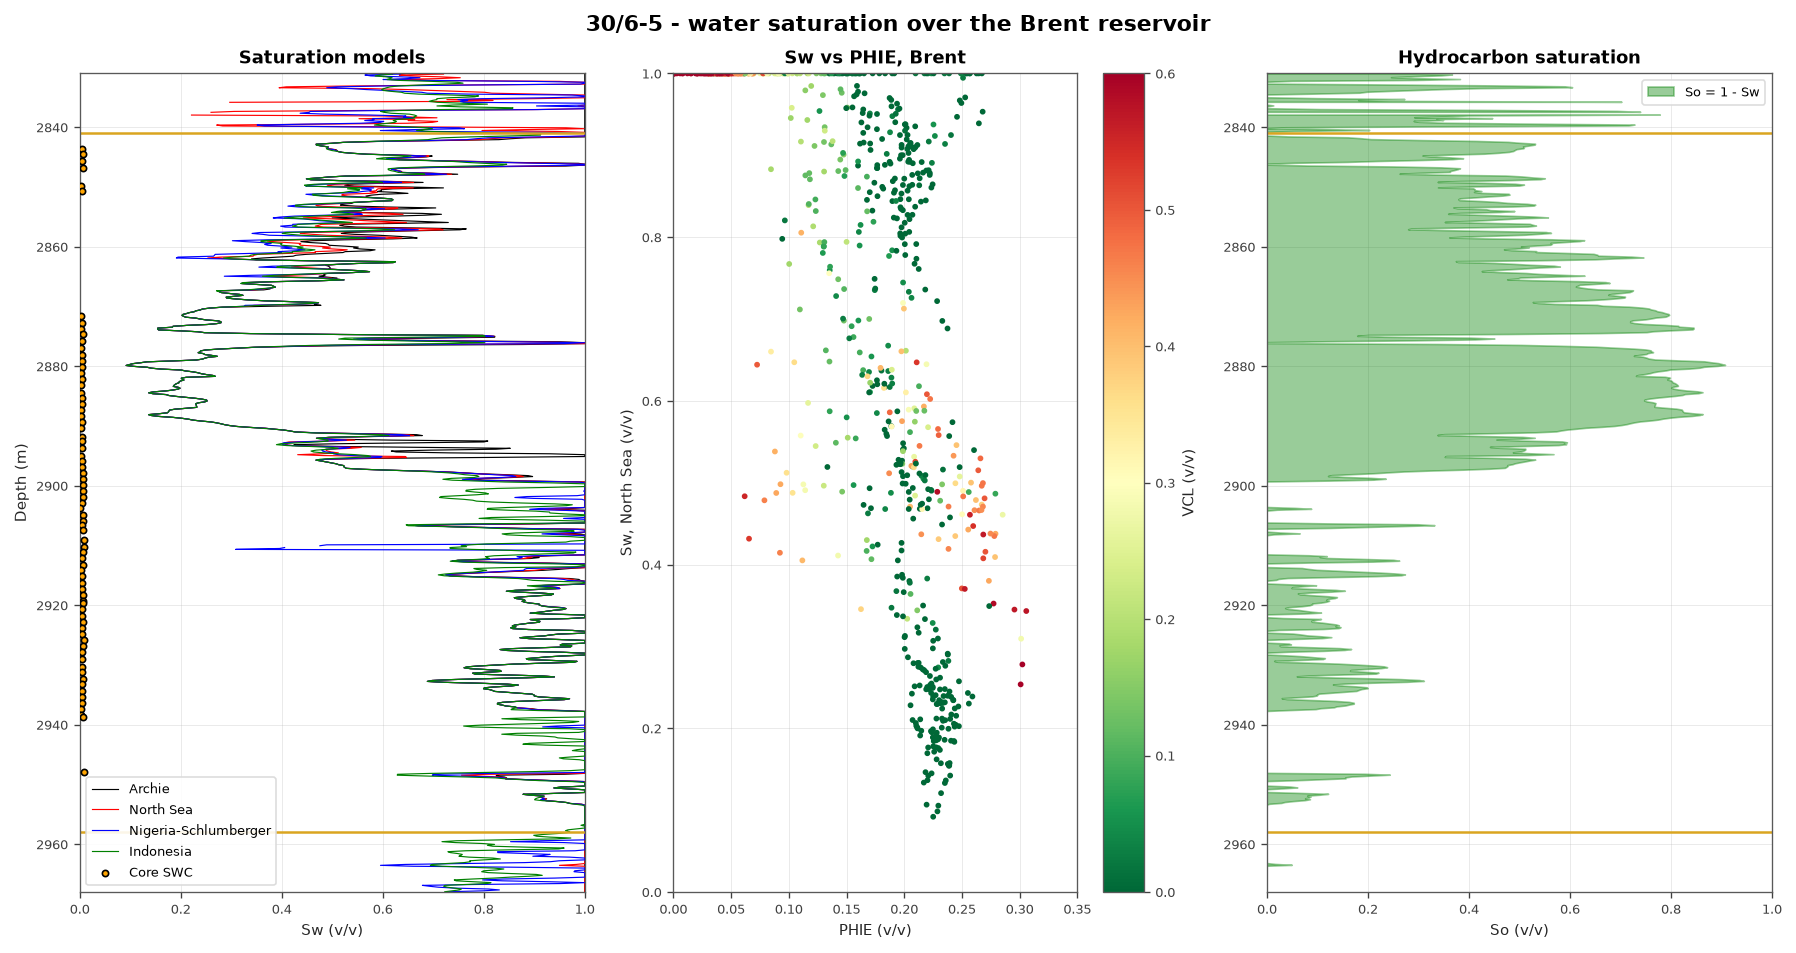

In [27]:
# Core water saturation is stored in percent (section 2); convert it for the 0-1 axis.
swc = standardize_core_saturation(well["SWC"], source_unit="%", warn=False).data
brent_plot = (depth >= BRENT_TOP - 10) & (depth <= BRENT_BASE + 10)
fig, axes = plt.subplots(1, 3, figsize=(15, 8))

ax = axes[0]
for (name, values), color in zip(sw_models.items(), ["black", "red", "blue", "green"]):
    ax.plot(values[brent_plot], depth[brent_plot], color=color, lw=0.7, label=name)
ax.scatter(swc[brent_plot], depth[brent_plot], s=14, color="orange", edgecolor="k", zorder=3,
           label="Core SWC")
ax.set_xlim(0, 1); ax.set_ylim(BRENT_BASE + 10, BRENT_TOP - 10)
ax.set_xlabel("Sw (v/v)"); ax.set_ylabel("Depth (m)"); ax.set_title("Saturation models")
ax.legend(fontsize=8, loc="lower left")

ax = axes[1]
ok = in_brent & np.isfinite(phie) & np.isfinite(sw)
sc = ax.scatter(phie[ok], sw[ok], c=vcl[ok], cmap="RdYlGn_r", s=6, vmin=0, vmax=0.6)
ax.set_xlim(0, 0.35); ax.set_ylim(0, 1)
ax.set_xlabel("PHIE (v/v)"); ax.set_ylabel("Sw, North Sea (v/v)"); ax.set_title("Sw vs PHIE, Brent")
plt.colorbar(sc, ax=ax, label="VCL (v/v)")

ax = axes[2]
ax.fill_betweenx(depth[brent_plot], 0, 1 - sw[brent_plot], color="green", alpha=0.4,
                 label="So = 1 - Sw")
ax.set_xlim(0, 1); ax.set_ylim(BRENT_BASE + 10, BRENT_TOP - 10)
ax.set_xlabel("So (v/v)"); ax.set_title("Hydrocarbon saturation"); ax.legend(fontsize=8)

for ax in (axes[0], axes[2]):
    ax.axhline(BRENT_TOP, color="goldenrod"); ax.axhline(BRENT_BASE, color="goldenrod")
for ax in axes:
    ax.grid(alpha=0.3)
fig.suptitle(f"{well.name} - water saturation over the Brent reservoir", fontweight="bold")
plt.tight_layout()
plt.show()

The hydrocarbon column shows up as the low-Sw interval in the upper Etive, with
wetter rock below it. Gaps in the North Sea curve in shaly beds are the samples where the model
does not apply (NaN, described above), not hydrocarbons. The core saturations (Dean-Stark plugs) scatter widely:
plug saturations are altered by mud-filtrate flushing and by gas expansion as
the core comes to surface, so they are a loose check rather than ground truth.

---
## 7. Permeability

Log permeability is always a correlation. The classic forms use porosity and
irreducible water saturation Swirr:

- **Timur**: k = 0.136 x phi^4.4 / Swirr^2 (phi and Swirr in percent);
- **Coates-Denoo**: k = 10^4 x phi^4 x ((1 - Swirr) / Swirr)^2 (phi and Swirr as fractions).

Swirr comes from lab data when it exists; otherwise `PermeabilityModule`
estimates it from the log and says how (`swi_source`).

In [28]:
from petrophys.interpretation.permeability import timur, coates_denoo, PermeabilityModule

perm_result = PermeabilityModule(method="timur").calculate(well)
swirr = perm_result.swi_used
print("Swirr source:", perm_result.swi_source)
print(f"Swirr used  : {float(np.nanmedian(swirr)):.3f}")

perm_timur = timur(phie, swirr)
perm_coates = coates_denoo(phie, swirr)
well.add_curve("PERM", perm_timur, "mD", "Permeability (Timur)")

kh = well["KH_CORE"].data
plugs = in_brent & np.isfinite(kh)
print(f"\nAt the {plugs.sum()} Brent core-plug depths (median, mD):")
print(f"   core KH_CORE : {np.nanmedian(kh[plugs]):8.1f}")
print(f"   Timur        : {np.nanmedian(perm_timur[plugs]):8.1f}")
print(f"   Coates-Denoo : {np.nanmedian(perm_coates[plugs]):8.1f}")

Swirr source: hc_mask_p5
Swirr used  : 0.147

At the 197 Brent core-plug depths (median, mD):
   core KH_CORE :     45.0
   Timur        :    235.1
   Coates-Denoo :    392.1


`hc_mask_p5` means Swirr was estimated as a low percentile of Sw in the
hydrocarbon-bearing samples. Compare the medians above: an empirical
permeability computed with one Swirr for the whole well can be far from the
plugs. Section 15 replaces it with a transform fitted to the core itself.

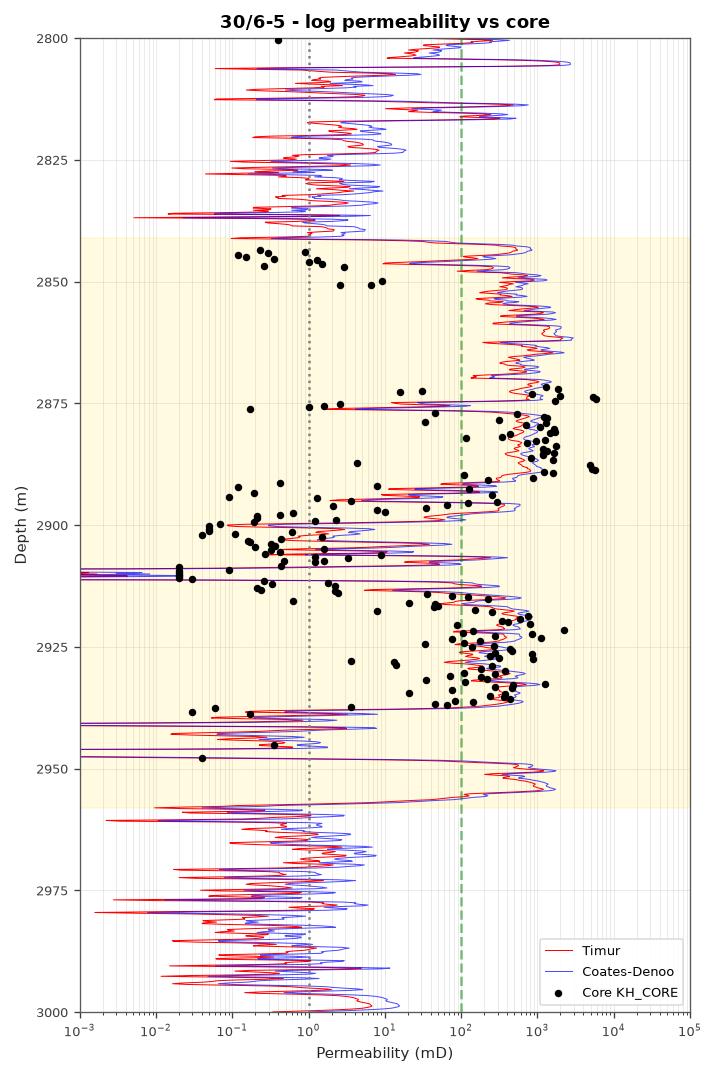

In [29]:
fig, ax = plt.subplots(figsize=(6, 9))
ax.semilogx(perm_timur[win], depth[win], color="red", lw=0.6, label="Timur")
ax.semilogx(perm_coates[win], depth[win], color="blue", lw=0.6, alpha=0.7, label="Coates-Denoo")
ax.scatter(kh[win], depth[win], s=12, color="black", zorder=3, label="Core KH_CORE")
ax.axvline(1, color="gray", ls=":"); ax.axvline(100, color="green", ls="--", alpha=0.5)
ax.axhspan(BRENT_TOP, BRENT_BASE, color="gold", alpha=0.12)
ax.set_xlim(1e-3, 1e5); ax.set_ylim(WINDOW[1], WINDOW[0])
ax.set_xlabel("Permeability (mD)"); ax.set_ylabel("Depth (m)")
ax.set_title(f"{well.name} - log permeability vs core"); ax.legend(fontsize=8)
ax.grid(alpha=0.3, which="both")
plt.tight_layout()
plt.show()

---
## 8. Net pay

Net-pay flags decide which depths count. `NetPayModule` applies three nested
cutoffs and writes three flag curves:

- `NET_ROCK`: VCL below the clay cutoff;
- `NET_RES`: net rock with PHIE above the porosity cutoff;
- `NET_PAY`: net reservoir with Sw below the saturation cutoff.

We use VCL < 0.40, PHIE > 0.10 and Sw < 0.60 (defined in the setup cell as
`CUTOFFS`). The library's clastic defaults are the same except PHIE > 0.08.

In [30]:
from petrophys.evaluation.net_pay import NetPayModule

net_module = NetPayModule(**CUTOFFS)
net_result = net_module.calculate(well)
net_module.add_to_well(well, net_result)

step = well.step
rows = []
for label, mask in [("whole well", np.ones_like(in_brent)), ("Brent window", in_brent)]:
    gross = mask.sum() * step
    row = {"interval": label, "gross (m)": gross}
    for flag in ["NET_ROCK", "NET_RES", "NET_PAY"]:
        row[f"{flag} (m)"] = np.sum(well[flag].data[mask] > 0.5) * step
    row["NTG (pay/gross)"] = row["NET_PAY (m)"] / gross
    rows.append(row)
print(pd.DataFrame(rows).round(3).to_string(index=False))

    interval  gross (m)  NET_ROCK (m)  NET_RES (m)  NET_PAY (m)  NTG (pay/gross)
  whole well   3378.514      2665.363     2469.746      614.428            0.182
Brent window    117.005        91.410       84.097       38.849            0.332


Most of the whole-well net pay is **not** in the reservoir. Shallow, poorly
compacted sediments read very high porosity and little clay, and with that much
porosity even modest resistivity gives a low Sw, so they pass all three
cutoffs. Cutoffs flag log values; they do not know where the reservoir is. That
is why every reservoir number in this tour is taken over the Brent window or per
formation (section 9).

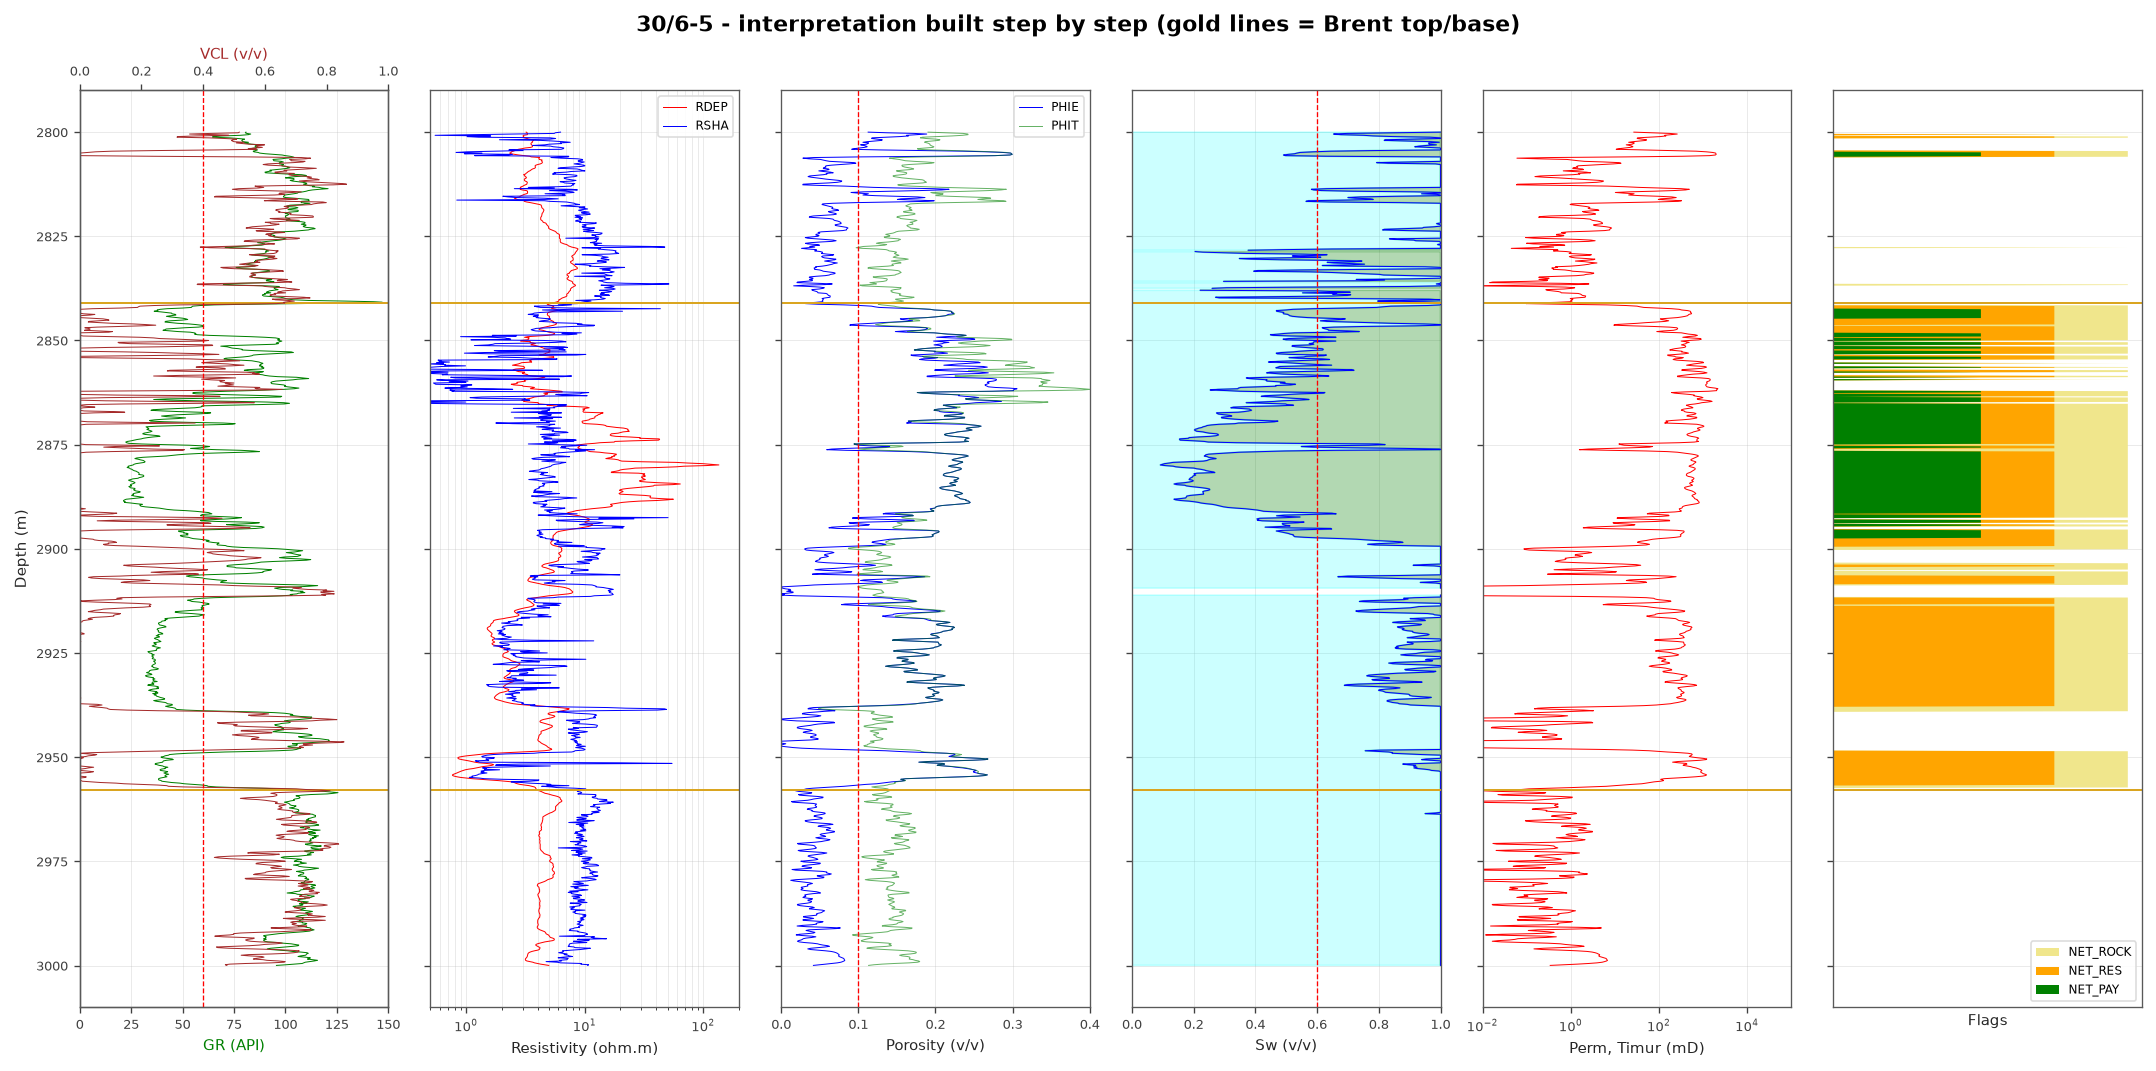

In [31]:
fig, axes = plt.subplots(1, 6, figsize=(18, 9), sharey=True)

ax = axes[0]
ax.plot(gr[win], depth[win], color="green", lw=0.6)
ax.set_xlim(0, 150); ax.set_xlabel("GR (API)", color="green"); ax.set_ylabel("Depth (m)")
ax2 = ax.twiny()
ax2.plot(vcl[win], depth[win], color="brown", lw=0.6)
ax2.axvline(CUTOFFS["vcl_cutoff"], color="red", ls="--", lw=0.8)
ax2.set_xlim(0, 1); ax2.set_xlabel("VCL (v/v)", color="brown")

ax = axes[1]
ax.semilogx(rt[win], depth[win], color="red", lw=0.6, label="RDEP")
ax.semilogx(well["RSHA"].data[win], depth[win], color="blue", lw=0.6, label="RSHA")
ax.set_xlim(0.5, 200); ax.set_xlabel("Resistivity (ohm.m)"); ax.legend(fontsize=7)

ax = axes[2]
ax.plot(phie[win], depth[win], color="blue", lw=0.6, label="PHIE")
ax.plot(phit[win], depth[win], color="green", lw=0.6, alpha=0.6, label="PHIT")
ax.axvline(CUTOFFS["phie_cutoff"], color="red", ls="--", lw=0.8)
ax.set_xlim(0, 0.4); ax.set_xlabel("Porosity (v/v)"); ax.legend(fontsize=7)

ax = axes[3]
ax.plot(sw[win], depth[win], color="blue", lw=0.6)
ax.fill_betweenx(depth[win], sw[win], 1, color="green", alpha=0.3)
ax.fill_betweenx(depth[win], 0, sw[win], color="cyan", alpha=0.2)
ax.axvline(CUTOFFS["sw_cutoff"], color="red", ls="--", lw=0.8)
ax.set_xlim(0, 1); ax.set_xlabel("Sw (v/v)")

ax = axes[4]
ax.semilogx(well["PERM"].data[win], depth[win], color="red", lw=0.6)
ax.set_xlim(1e-2, 1e5); ax.set_xlabel("Perm, Timur (mD)")

ax = axes[5]
for flag, color, level in [("NET_ROCK", "khaki", 1.0), ("NET_RES", "orange", 0.75), ("NET_PAY", "green", 0.5)]:
    ax.fill_betweenx(depth[win], 0, level * well[flag].data[win], color=color, lw=0, label=flag)
ax.set_xlim(0, 1.05); ax.set_xticks([]); ax.set_xlabel("Flags"); ax.legend(fontsize=7, loc="lower right")

for ax in axes:
    ax.axhline(BRENT_TOP, color="goldenrod", lw=1.2); ax.axhline(BRENT_BASE, color="goldenrod", lw=1.2)
    ax.grid(alpha=0.3, which="both")
axes[0].invert_yaxis()
fig.suptitle(f"{well.name} - interpretation built step by step (gold lines = Brent top/base)",
             fontweight="bold")
plt.tight_layout()
plt.show()

---
## 9. Formation-level interval analysis

Now we roll the curves up by geological interval. `petrophys.evaluation.intervals`
holds the geometry (interval types and the `FormationTops` collection) and the
per-interval statistics (`IntervalAnalyzer`).

`FormationTops.from_dataframe` turns the table from section 3 into a queryable
collection.

In [32]:
from petrophys.evaluation.intervals import (
    FormationTops, IntervalAnalyzer, Formation, Zone, SubZone, ManualInterval,
)

tops = FormationTops.from_dataframe(tops_table)
print(f"{len(tops)} intervals; validation issues: {tops.validate() or 'none'}")
print("Overlaps reported:", tops.find_overlaps() or "none (groups contain their formations)")
print("At 2900 m        :", [iv.name for iv in tops.get_at_depth(2900.0)])
print("In 2800-3000 m   :", [iv.name for iv in tops.get_in_range(2800.0, 3000.0)])
etive = tops.get_by_name("Etive Fm.")
print(f"Etive Fm.        : {etive.top_depth:.0f} - {etive.bottom_depth:.0f} m, "
      f"{etive.thickness:.0f} m, lithology {etive.lithology!r}")

20 intervals; validation issues: none
Overlaps reported: none (groups contain their formations)
At 2900 m        : ['BAAT GP.', 'Etive Fm.']
In 2800-3000 m   : ['VIKING GP.', 'Heather Fm.', 'BAAT GP.', 'Ness Fm.', 'Etive Fm.', 'DUNLIN GP.', 'Drake Fm.']
Etive Fm.        : 2865 - 2958 m, 93 m, lithology 'Sandstone'


`IntervalAnalyzer` computes gross, net and pay-averaged properties for each
interval, using the flag and property curves on the well. We analyse the
formation rank only, so no interval is counted twice.

In [33]:
formation_tops = FormationTops.from_dataframe(
    pp.read_formations(FM_CSV, well=well, rank="formation"))
analyzer = IntervalAnalyzer(well)
summaries = analyzer.analyze_all(formation_tops, clip_to_well=True)
IntervalAnalyzer.print_report(summaries)


INTERVAL ANALYSIS REPORT
Name                           Top      Bot   Gross   NtPay    NTG   PHIE     Sw    VCL     Perm
-----------------------------------------------------------------------------------------------
Utsira Fm.                   726.0    879.0   153.0     7.2   4.7%  0.440  0.579  0.024 10749.13
Balder Fm.                  1908.0   2023.0   115.1     4.0   3.4%  0.365  0.573  0.002  4683.81
Sele Fm.                    2023.0   2123.0   100.0     0.3   0.3%  0.426  0.572  0.049  9361.13
Lista Fm.                   2123.0   2203.0    80.0     1.1   1.3%  0.393  0.531  0.081  6545.44
Draupne Fm.                 2452.0   2593.0   141.0     0.3   0.2%  0.283  0.500  0.378  1541.34
Heather Fm.                 2593.0   2841.0   248.0    32.6  13.2%  0.138  0.521  0.283    60.06
Ness Fm.                    2841.0   2865.0    24.1     9.8  40.5%  0.223  0.510  0.120   526.28
Etive Fm.                   2865.0   2958.0    93.0    29.1  31.3%  0.212  0.299  0.027   407.90
Drake

The report lists every formation, including the shallow Utsira and Rogaland
formations and the Heather Fm. mudstones; any flags there come from the
cutoff behaviour described in section 8 (or from silty beds inside a shale) and
need geological review before they count. The `TOTAL` line adds all rows, so
it is not a reservoir number. The reservoir rows are Ness and Etive (the
Brent), with thinner sands in the Cook and Statfjord formations.

The `Perm` column is the Timur permeability of section 7, computed with one
whole-well Swirr. In the shallow formations, at porosities of 0.35-0.45, it
reads thousands to tens of thousands of mD: the correlation is far outside the
range it was built for, so treat those values as an index, not a permeability.

`to_dataframe` gives the same numbers as a table. `Avg PHIE`, `Avg Sw` and
`Avg VCL` are averages over the **net-pay samples** of each formation.

In [34]:
summary_df = IntervalAnalyzer.to_dataframe(summaries)
summary_df[["Name", "Top", "Bottom", "Gross", "Net Rock", "Net Reservoir", "Net Pay", "NTG",
            "Avg PHIE", "Avg Sw", "Avg VCL", "Data Coverage %"]].round(3)

,Name,Top,Bottom,Gross,Net Rock,Net Reservoir,Net Pay,NTG,Avg PHIE,Avg Sw,Avg VCL,Data Coverage %
0,Utsira Fm.,726.0,879.0,153.010,153.010,153.010,7.163,0.047,0.440,0.579,0.024,100.000
1,Balder Fm.,1908.0,2023.0,115.062,113.081,113.081,3.962,0.034,0.365,0.573,0.002,100.000
2,Sele Fm.,2023.0,2123.0,99.974,99.670,99.670,0.305,0.003,0.426,0.572,0.049,100.000
3,Lista Fm.,2123.0,2203.0,80.010,80.010,79.858,1.067,0.013,0.393,0.531,0.081,100.000
4,Draupne Fm.,2452.0,2593.0,140.970,1.981,1.981,0.305,0.002,0.283,0.500,0.378,100.000
5,Heather Fm.,2593.0,2841.0,247.955,95.708,84.430,32.613,0.132,0.138,0.521,0.283,100.000
6,Ness Fm.,2841.0,2865.0,24.079,16.459,16.002,9.754,0.405,0.223,0.510,0.120,100.000
7,Etive Fm.,2865.0,2958.0,92.964,74.981,68.123,29.109,0.313,0.212,0.299,0.027,100.000
8,Drake Fm.,2958.0,3071.0,113.081,3.505,0.000,0.000,0.000,NaN,NaN,NaN,100.000
9,Cook Fm.,3071.0,3123.0,51.968,42.519,24.536,0.152,0.003,0.154,0.600,0.144,100.000


The Ness Fm. shows a high net-to-gross. The vendor lithology log from section 3
lets us check what its flagged samples actually are.

In [35]:
ness_pay = (depth >= 2841.0) & (depth < 2865.0) & (well["NET_PAY"].data > 0.5)
print(f"Ness net-pay samples: {ness_pay.sum()}, by vendor lithology:")
print(pd.Series(vendor_names[ness_pay]).replace("", "(no code)").value_counts().to_string())

Ness net-pay samples: 64, by vendor lithology:
Cross Bedded Sst    18
Silty Sand          15
Shaly Silt          14
Coal                11
Silt                 6


Some of the Ness "pay" is coal and shaly silt. Coal has a low bulk density
(high apparent porosity) and a high resistivity, the classic false-pay
signature, and our clay indicators do not see it as clay. A production
interpretation masks coal with the lithology log before counting pay, and
`pp.interpret` leaves samples its lithology calls coal out of net reservoir and
pay. In section 10 the lithology comes from the coarse interval file, which takes
precedence over the vendor codes and has no coal bed, so compare its Ness row
there.

A single ad-hoc window uses `ManualInterval`. Here it is the Brent reservoir as
a whole.

In [36]:
brent = ManualInterval(name="Brent reservoir window", top_depth=BRENT_TOP, bottom_depth=BRENT_BASE)
single = analyzer.analyze(brent)
zs = single.zone_summary
print(f"Interval       : {single.interval.name} ({BRENT_TOP:.0f}-{BRENT_BASE:.0f} m)")
print(f"Gross          : {zs.gross_thickness:.1f} m")
print(f"Net pay        : {zs.net_pay:.1f} m   (NTG {zs.ntg:.1%})")
print(f"Avg PHIE (pay) : {zs.avg_phie:.3f}")
print(f"Avg Sw   (pay) : {zs.avg_sw:.3f}")
print(f"Avg VCL  (pay) : {zs.avg_vcl:.3f}")
print(f"Avg perm (pay) : {zs.avg_perm:.0f} mD")
print(f"HCPV index     : {zs.hcpv:.3f} m (sum of PHIE x (1 - Sw) x step over pay)")
print(f"Data coverage  : {single.data_coverage_pct:.1f} %")

Interval       : Brent reservoir window (2841-2958 m)
Gross          : 117.0 m
Net pay        : 38.9 m   (NTG 33.2%)
Avg PHIE (pay) : 0.215
Avg Sw   (pay) : 0.352
Avg VCL  (pay) : 0.050
Avg perm (pay) : 435 mD
HCPV index     : 5.488 m (sum of PHIE x (1 - Sw) x step over pay)
Data coverage  : 100.0 %


Intervals can be nested: a `Formation` (here the Brent Group), `Zone`s inside
it (Ness, Etive), and `SubZone`s inside a zone. The parent fields are labels
that travel with the interval; the analyzer treats every interval
independently. The Etive split below is an **illustrative** halving at its
mid-depth, not a geological pick.

In [37]:
etive_mid = 0.5 * (etive.top_depth + etive.bottom_depth)
hierarchy = [
    Formation(name="Brent Group", top_depth=BRENT_TOP, bottom_depth=BRENT_BASE, age="Middle Jurassic"),
    Zone(name="Ness Fm.", top_depth=2841.0, bottom_depth=2865.0, parent_formation="Brent Group"),
    Zone(name="Etive Fm.", top_depth=2865.0, bottom_depth=2958.0, parent_formation="Brent Group"),
    SubZone(name="Etive upper half", top_depth=2865.0, bottom_depth=etive_mid, parent_zone="Etive Fm."),
    SubZone(name="Etive lower half", top_depth=etive_mid, bottom_depth=2958.0, parent_zone="Etive Fm."),
]
print(f"{'Level':<10s} {'Name':<18s} {'Top':>7s} {'Base':>7s} {'Gross':>6s} {'Pay':>6s} {'NTG':>6s} "
      f"{'PHIE':>6s} {'Sw':>6s}")
for interval in hierarchy:
    s = analyzer.analyze(interval).zone_summary
    phie_text = f"{s.avg_phie:.3f}" if np.isfinite(s.avg_phie) else "-"
    sw_text = f"{s.avg_sw:.3f}" if np.isfinite(s.avg_sw) else "-"
    print(f"{type(interval).__name__:<10s} {interval.name:<18s} {interval.top_depth:7.1f} "
          f"{interval.bottom_depth:7.1f} {s.gross_thickness:6.1f} {s.net_pay:6.1f} {s.ntg:6.1%} "
          f"{phie_text:>6s} {sw_text:>6s}")

Level      Name                   Top    Base  Gross    Pay    NTG   PHIE     Sw
Formation  Brent Group         2841.0  2958.0  117.0   38.9  33.2%  0.215  0.352
Zone       Ness Fm.            2841.0  2865.0   24.1    9.8  40.5%  0.223  0.510
Zone       Etive Fm.           2865.0  2958.0   93.0   29.1  31.3%  0.212  0.299
SubZone    Etive upper half    2865.0  2911.5   46.5   29.1  62.6%  0.212  0.299
SubZone    Etive lower half    2911.5  2958.0   46.5    0.0   0.0%      -      -


The upper half of the Etive carries its pay and the lower half is wet,
consistent with the hydrocarbon column over wetter sand seen in section 6.

---
## 10. The full workflow with `pp.interpret`

Sections 2-9 were the long way. `pp.interpret` runs the whole chain in one call:
it checks which curves and parameters are available, runs every step it can
(standardization, temperature, bad hole, clay volume, porosity, lithology, core
correction, Rw, saturation, permeability, rock quality, net pay, ...), and
records why it skipped any step. It works on a **copy** of the well and returns
a `DynamicWorkflowResult`.

Settings are the fields of `pp.DynamicWorkflowConfig`, passed either as a config
object or as keyword arguments. They are validated when created: a misspelt
name or an invalid value raises an error with a suggestion instead of being
silently ignored.

In [38]:
geo_raw = pp.read(pp.sample("30_6-5"), formations=FM_CSV, lithology=LITH_CSV)

config = pp.DynamicWorkflowConfig(
    rw=RW, rw_meas_temp_f=RW_TEMP_F,              # Rw and the temperature it was measured at
    bht_f=geo_raw.get_parameter("BHT") * 9 / 5 + 32,   # header BHT (degC) in degF
    td_ft=geo_raw.bottom * 3.28084,              # depth of that BHT, in feet
    lithology_domain="clastic", matrix_type="sandstone",
    a=A, m=M, n=N,
    sw_model="auto",                             # choose the model depth by depth
    **CUTOFFS,
)
print(f"bht_f = {config.bht_f:.1f} degF at td_ft = {config.td_ft:.0f} ft")

try:
    pp.DynamicWorkflowConfig(sw_model="simandoox")
except ValueError as exc:
    print("\nValueError:", exc)
try:
    pp.interpret(geo_raw, sw_modle="archie")
except TypeError as exc:
    print("\nTypeError:", exc)

bht_f = 258.8 degF at td_ft = 11667 ft

ValueError: Invalid DynamicWorkflowConfig:
  - sw_model='simandoox' is not valid; use one of: auto, archie, north_sea, nigeria_schlumberger, simandoux, modified_simandoux, indonesia, dual_water, waxman_smits (did you mean 'simandoux'?)

TypeError: Unknown interpretation setting(s): 'sw_modle' (did you mean 'sw_model'?). See petrophys.DynamicWorkflowConfig for the available settings.


In [39]:
curves_before = tuple(geo_raw.curves)
result = pp.interpret(geo_raw, config=config)
result.raise_for_errors()                        # stop here if any step failed
assert tuple(geo_raw.curves) == curves_before     # the input well is unchanged

print("Status  :", result.status)
print("Executed:", len(result.steps_executed), "steps")
print("Skipped :")
for step, reason in result.specific_steps_skipped.items():
    print(f"   {step:<22s} {reason}")
print("Warnings:")
for text in result.warnings:
    print("   -", text)

Status  : interpreted
Executed: 18 steps
Skipped :
   spectral_gamma         Not run by the interpretation workflow; use petrophys.interpretation.geochemistry.interpret_spectral_gamma directly
   elemental_spectroscopy Not run by the interpretation workflow; use petrophys.interpretation.geochemistry.interpret_elemental_spectroscopy directly
   hc_correction          apply_hc_correction=False (hydrocarbon correction is opt-in)
   porosity_refinement    Not run by the interpretation workflow; porosity is computed once in the porosity step
Warnings:
   - Marl uses the limestone matrix and carbonate cutoff family. This is a routing convention, not a calibrated marl model; check clay correction and supply project-specific cutoffs.
   - External lithology: unmapped labels [], 30 uncovered samples. Labels/gaps are preserved; unclassified samples use configured calculation fallbacks, not inferred rock labels.
   - lithology: PEF set aside: in 96% of 245 clean porous samples the apparent matrix

The warnings are worth reading: a few samples fall outside the lithology
file, and the `marl` interval is routed to the carbonate cutoff family by
convention rather than by a calibrated marl model.

`result.print_trace()` prints every step with its method, inputs, outputs,
parameters and decisions. It is long (hundreds of lines for this well), so we
show its opening and then use the tabular form, `result.to_dataframe()`, whose
`Decisions` column holds the reasoning.

In [40]:
buffer = io.StringIO()
with contextlib.redirect_stdout(buffer):
    result.print_trace()
trace_lines = buffer.getvalue().splitlines()
print(f"(print_trace wrote {len(trace_lines)} lines; the first 12:)")
print("\n".join(trace_lines[:12]))

(print_trace wrote 446 lines; the first 12:)

WORKFLOW TRACE: 30/6-5
Overall: SUCCESS | Executed: 18 | Skipped: 4
Lithology domain: clastic
Rw = 0.0624-0.1967 ohm.m | Rmf = 0.0246-0.0776 | Rcl = 1.3691

[OK  ] normalization
       Method: curve_alias_and_unit_standardization
       Inputs: BS, CALI, DRHO, DTC, DTE, GDEN, GR, KH_CORE, KV_CORE, LITHOLOGY_GEOLINK, NPHI, PEF, PHIC, RDEP, RHOB, RMED, RSHA, SOC, SP, SWC
       Outputs: DRHO, PEF, GR, DTC, SWC, SOC


In [41]:
steps = result.to_dataframe()
view = steps[["Step", "Status", "Method", "Decisions"]].copy()
view["Decisions"] = view["Decisions"].astype(str).str.slice(0, 90)
print(view.to_string(index=False, max_colwidth=90))

           Step Status                                      Method                                                                                  Decisions
  normalization     OK        curve_alias_and_unit_standardization Standardized curve units, nulls, and plausible ranges before routing | No canonical workin
  input_context     OK                 validated_geology_selection Selected external lithology; alternate sources were retained | Using 20 attached formation
    temperature     OK                    linear_gradient_from_BHT Temperature profile anchored to BHT metadata/input | Gradient = 1.6354 F/100ft (29.81 C/km
       bad_hole     OK                          caliper_drho_flags                                                12631 bad-hole samples flagged out of 22176
          vclay     OK                                      linear GR_min = 21.6 (auto, P5 of GR) | GR_max = 115.3 (auto, P95 of GR) | Gamma-ray clay input: 
            rcl     OK                   lithology_s

Each executed step is also available as an object. The saturation step shows
which models the router chose, how many samples each got, and where the Archie
constants came from.

In [42]:
sat = next(s for s in result.steps_executed if s.step == "saturation")
print("Method  :", sat.method)
print("Inputs  :", ", ".join(sat.input_curves))
print("Outputs :", ", ".join(sat.output_curves))
for key in ["sw_model_requested", "sw_model_sample_counts", "a", "m", "n",
            "archie_a_source", "rw_min", "rw_max", "rtsh"]:
    value = sat.parameters.get(key)
    print(f"   {key:<24s} {value:.4g}" if isinstance(value, float) else f"   {key:<24s} {value}")
print("Decisions:")
for decision in sat.decisions[:6]:
    print("   ->", decision[:110])

Method  : archie+indonesia
Inputs  : RDEP, PHIE_CC, VCL
Outputs : SW, SXO
   sw_model_requested       auto
   sw_model_sample_counts   {'archie': 12942, 'indonesia': 9234}
   a                        0.8
   m                        2
   n                        2
   archie_a_source          config_or_las
   rw_min                   0.06241
   rw_max                   0.1967
   rtsh                     1.369
Decisions:
   -> Model selected: archie+indonesia
   -> Indonesia equation of Poupon and Leveaux (1971): 1/sqrt(Rt) = [VCL^(1-VCL/2)/sqrt(Rcl) + PHIE^(m/2)/sqrt(a*Rw)
   -> Auto-routing: depth-by-depth model selection based on VCLAY and lithology
   -> Depth routing counts: archie=12942, indonesia=9234
   -> Dual Water needs a supplied Rwb, which is not estimated: 695 shaly carbonate samples used the Indonesia equati
   -> Archie coefficients from lithology (external_lithology)


`archie_a_source = config_or_las` confirms that our a, m and n were applied.
(The decision line about lithology coefficients is printed in any case; rely on
the parameter sources.) `rw_min` and `rw_max` are Rw after temperature
correction along the well.

For numbers, use `result.summary()` (a compact dictionary; pass `top` and
`bottom` for a window) and `result.formation_summary()` (one row per formation;
`rank="formation"` picks one non-overlapping level of the attached tops).

In [43]:
whole = result.summary()["net_thickness"]
window = result.summary(top=BRENT_TOP, bottom=BRENT_BASE)["net_thickness"]
print(f"Net pay, whole well (every flagged sample): {whole['net_pay']:.2f} m")
print(f"Net pay, Brent window {BRENT_TOP:.0f}-{BRENT_BASE:.0f} m    : {window['net_pay']:.2f} m")

by_formation = result.formation_summary(rank="formation")
columns = ["Formation", "Top", "Bottom", "Gross (m)", "Net Pay (m)", "NTG",
           "Avg PHIE", "Avg Sw", "Avg VCL", "Avg Perm (mD)"]
by_formation[columns].round(3)

Net pay, whole well (every flagged sample): 28.80 m
Net pay, Brent window 2841-2958 m    : 22.25 m


,Formation,Top,Bottom,Gross (m),Net Pay (m),NTG,Avg PHIE,Avg Sw,Avg VCL,Avg Perm (mD)
0,Utsira Fm.,726.0,879.0,153.010,0.000,0.000,NaN,NaN,NaN,NaN
1,Balder Fm.,1908.0,2023.0,115.062,1.829,0.016,0.355,0.570,0.071,10000.000
2,Sele Fm.,2023.0,2123.0,99.974,0.000,0.000,NaN,NaN,NaN,NaN
3,Lista Fm.,2123.0,2203.0,80.010,0.000,0.000,NaN,NaN,NaN,NaN
4,Draupne Fm.,2452.0,2593.0,140.970,0.000,0.000,NaN,NaN,NaN,NaN
5,Heather Fm.,2593.0,2841.0,247.955,0.152,0.001,0.247,0.589,0.063,4257.671
6,Ness Fm.,2841.0,2865.0,24.079,1.524,0.063,0.211,0.518,0.016,207.898
7,Etive Fm.,2865.0,2958.0,92.964,20.726,0.223,0.218,0.252,0.055,827.579
8,Drake Fm.,2958.0,3071.0,113.081,0.000,0.000,NaN,NaN,NaN,NaN
9,Cook Fm.,3071.0,3123.0,51.968,0.000,0.000,NaN,NaN,NaN,NaN


Compare the rows with section 8. Flags in shallow formations (the Utsira sand in section 8's step-by-step
result, the Balder Fm. in both) are a question for geological review, not pay: one Rw,
corrected for temperature at constant salinity, serves the whole well although
shallow formation water is usually fresher, and the clay indicators disagree in
poorly compacted mudstone. Report the reservoir rows (Ness, Etive, Cook,
Statfjord).

The figure compares the workflow's curves with the step-by-step ones from
sections 4-7, with core plugs for reference. The workflow differs in several
choices. It picks its GR endpoints as the 5th and 95th percentiles of the whole
log (which `vcl_from_gr` widens to at most 20 and at least 100 API), not of the
Jurassic section. Its VCL is the minimum of the gamma-ray and neutron-density
estimates, with the neutron-density clean line of the run's matrix (sandstone
here) and a clay point picked in the well's own shales; it reports the SP
estimate but leaves it out of the minimum, as section 4 did. It calibrates
porosity and permeability to the core (`PHIE_CC`, `PERM_CC`) where a core fit
passes its quality gate, and it routes the saturation model by depth. Inside the
Brent sands the curves agree broadly. Where the effective porosity is zero (tight
shale), Sw has no meaning and the workflow's SW can jump between 0 and 1; those
samples fail the porosity cutoff, so they never count as pay.

Read `PERM_CC` with care outside the cored Brent. The workflow fits its
porosity-permeability transform on the plugs (2800-2948 m) but applies it at
every depth, so it extrapolates: the cell prints how many samples sit at the
workflow's 10,000 mD clip (`perm_max_clip_md`, mostly in the soft shallow
section) and how many shale samples (VCL > 0.7) get 1,000 mD or more. Those
values are not permeabilities; use `PERM_CC` only inside the cored interval and
porosity range (section 15).

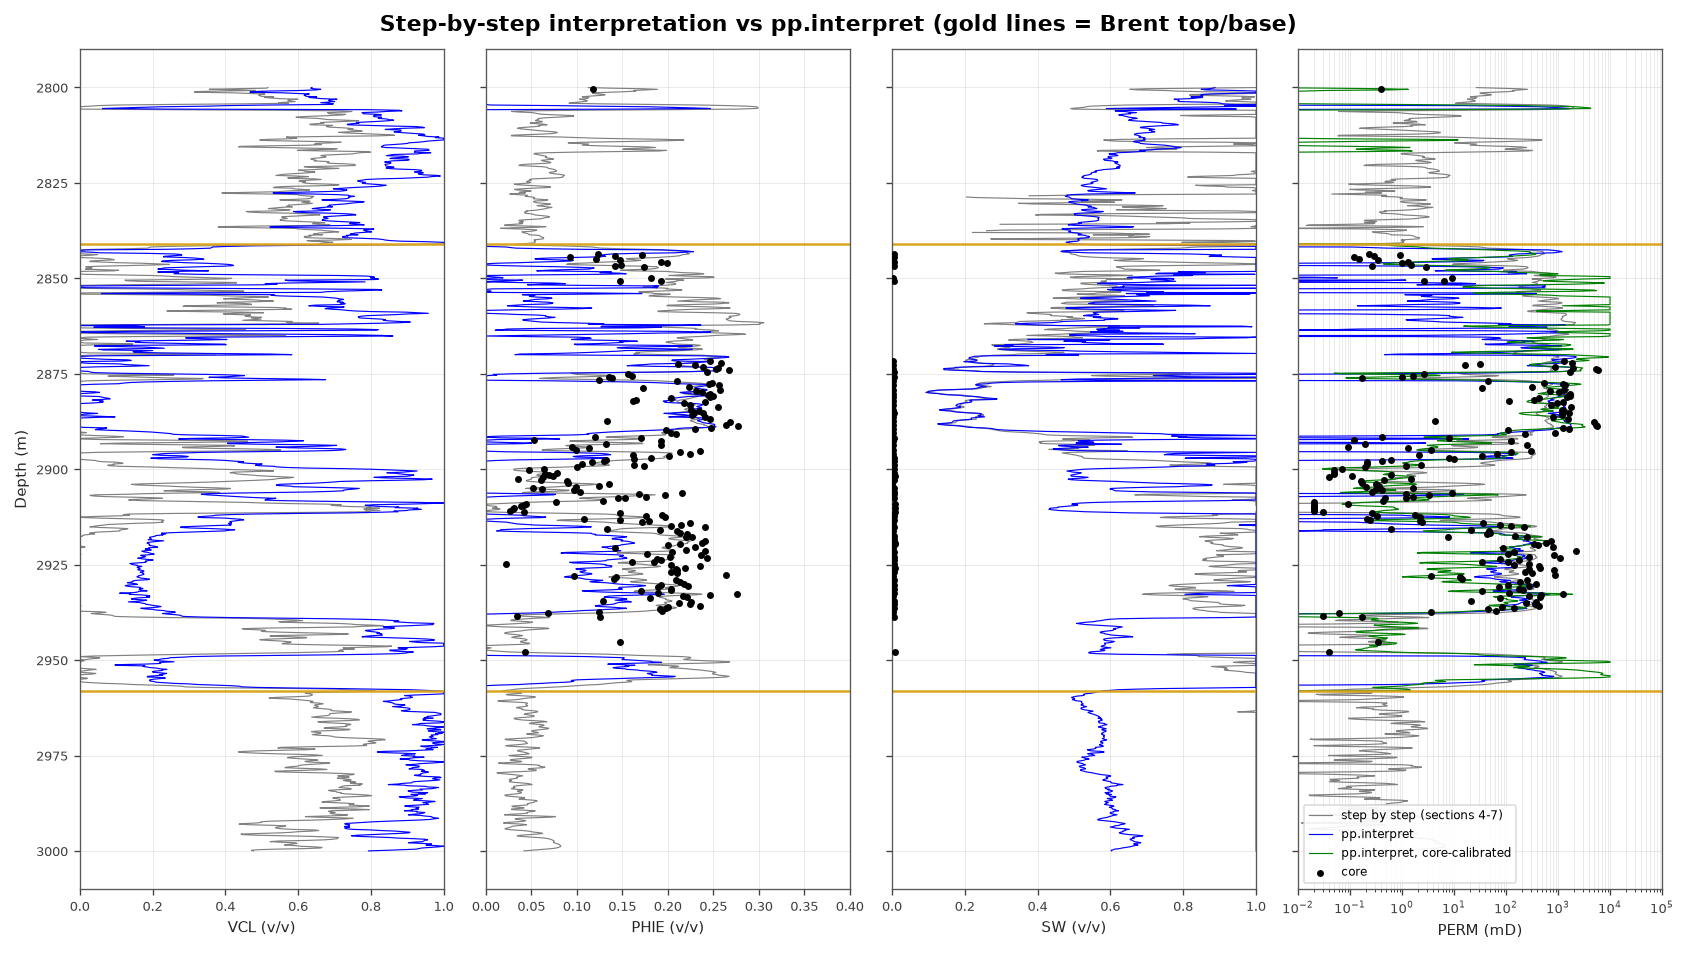

PERM_CC at the 10,000 mD clip: 12278 of 22176 samples (11653 of them above 2000 m)
Shale samples (VCL > 0.7) with PERM_CC >= 1000 mD: 123


In [44]:
from petrophys.preprocessing import standardize_core_saturation

interp = result.well
wd = interp.depth
wwin = (wd >= WINDOW[0]) & (wd <= WINDOW[1])
pairs = [("VCL", "v/v", (0, 1), False, None), ("PHIE", "v/v", (0, 0.4), False, "PHIC"),
         ("SW", "v/v", (0, 1), False, "SWC"), ("PERM", "mD", (1e-2, 1e5), True, "KH_CORE")]
fig, axes = plt.subplots(1, 4, figsize=(14, 8), sharey=True)
for ax, (curve, unit, xlim, log, core_curve) in zip(axes, pairs):
    plot = ax.semilogx if log else ax.plot
    plot(well[curve].data[win], depth[win], color="gray", lw=0.7, label="step by step (sections 4-7)")
    plot(interp[curve].data[wwin], wd[wwin], color="blue", lw=0.7, label="pp.interpret")
    if curve == "PERM":
        ax.semilogx(interp["PERM_CC"].data[wwin], wd[wwin], color="green", lw=0.7,
                    label="pp.interpret, core-calibrated")
    if core_curve:
        core_values = interp[core_curve].data
        if core_curve == "SWC":                       # stored in percent (section 2)
            core_values = standardize_core_saturation(interp["SWC"], source_unit="%", warn=False).data
        ax.scatter(core_values[wwin], wd[wwin], s=10, color="black", zorder=3, label="core")
    ax.set_xlim(*xlim); ax.set_xlabel(f"{curve} ({unit})"); ax.grid(alpha=0.3, which="both")
    ax.axhline(BRENT_TOP, color="goldenrod"); ax.axhline(BRENT_BASE, color="goldenrod")
axes[0].set_ylabel("Depth (m)"); axes[0].invert_yaxis()
axes[3].legend(fontsize=7, loc="lower left")
fig.suptitle("Step-by-step interpretation vs pp.interpret (gold lines = Brent top/base)", fontweight="bold")
plt.tight_layout()
plt.show()

perm_cc = interp["PERM_CC"].data
print(f"PERM_CC at the 10,000 mD clip: {np.sum(perm_cc >= 9999.0)} of {np.isfinite(perm_cc).sum()} samples "
      f"({np.sum((perm_cc >= 9999.0) & (wd < 2000.0))} of them above 2000 m)")
print(f"Shale samples (VCL > 0.7) with PERM_CC >= 1000 mD: "
      f"{np.sum((interp['VCL'].data > 0.7) & (perm_cc >= 1000.0))}")

**The lower-level form.** `run_dynamic_workflow(well, config)` from `petrophys.workflow` is what
`pp.interpret` calls. It **adds the curves to the well you pass in** instead of
working on a copy. Use it when you deliberately want to fill an existing `Well`
(for example one you built from a DataFrame); otherwise prefer `pp.interpret`.
The older `StandardWorkflow` is kept only for existing code and is scheduled
for removal, so it is not shown here.

In [45]:
from petrophys.workflow import run_dynamic_workflow

in_place = pp.read(pp.sample("30_6-5"), formations=FM_CSV, lithology=LITH_CSV)
n_before = in_place.n_curves
low_level = run_dynamic_workflow(in_place, config=config)
print("Curves before:", n_before, "| after:", in_place.n_curves)
print("result.well is the well we passed in:", low_level.well is in_place)

Curves before: 20 | after: 62
result.well is the well we passed in: True


---
## 11. Multi-well comparison

We run the same interpretation, with the same cutoffs, on four bundled GeoLink
wells. The Rw and its temperature must be chosen per well; this is what we use
and why:

| Well | Rw (ohm.m) | at (degF) | Source |
|---|---|---|---|
| 30/6-5 | 0.070 | 230 | Operator value used in lessons 07-11 and 17 |
| 25/5-1 | 0.047 | 200 | The well's own LAS header (`RW`, `RWT`); no lesson sets an Rw for this well |
| 16/7-1 | 0.050 | 200 | CS4 assumes 0.05 ohm.m "at formation temperature" (no water sample) without stating the temperature, and the LAS has no BHT. **Assumption:** 200 degF, about what the library's fallback 30 degC/km gradient gives near the base of this well |
| 15/9-14 | 0.070 | 230 | **Assumption:** no lesson and no header gives an Rw for this well, so we borrow the 30/6-5 value as a North Sea analogue |

The two assumed values make the 16/7-1 and 15/9-14 saturations screening
numbers only. Of the four wells, only 30/6-5 records a BHT; for the others the
workflow falls back to a 30 degC/km gradient and says so in its trace.

In [46]:
WELL_SETTINGS = {
    "30_6-5":  dict(rw=0.070, rw_meas_temp_f=230.0),
    "25_5-1":  dict(rw=0.047, rw_meas_temp_f=200.0),
    "16_7-1":  dict(rw=0.050, rw_meas_temp_f=200.0),
    "15_9-14": dict(rw=0.070, rw_meas_temp_f=230.0),
}
field = {}
for name, settings in WELL_SETTINGS.items():
    field[name] = pp.interpret(pp.read(pp.sample(name)), lithology="clastic",
                               **settings, **CUTOFFS)
    field[name].raise_for_errors()

[repository]\src\petrophys\preprocessing\standardization\curve_standardizer.py:1055: DataQualityWarning: RMED: 58 of 18648 samples sit at the curve's maximum 2000 ohm.m, a tool or computation ceiling rather than a reading, and were removed.
  return standardizer.standardize(well)


[repository]\src\petrophys\workflow\dynamic_workflow.py:4590: DataQualityWarning: DTC: 4914 of 9427 samples are outside the plausible DTC range 38.5 to 300 us/ft and were removed.
  standardize_curves(


[repository]\src\petrophys\workflow\dynamic_workflow.py:4590: DataQualityWarning: DTE: 20181 of 20181 samples are outside the plausible DTE range 20 to 600 us/ft and were removed.
  standardize_curves(
[repository]\src\petrophys\preprocessing\standardization\curve_standardizer.py:1055: DataQualityWarning: RSHA: 13 of 20295 samples sit at the curve's maximum 2000 ohm.m, a tool or computation ceiling rather than a reading, and were removed.
  return standardizer.standardize(well)
[repository]\src\petrophys\preprocessing\standardization\curve_standardizer.py:1055: DataQualityWarning: RXO: 6 of 4059 samples sit at the curve's maximum 2000 ohm.m, a tool or computation ceiling rather than a reading, and were removed.
  return standardizer.standardize(well)
[repository]\src\petrophys\preprocessing\standardization\curve_standardizer.py:1055: DataQualityWarning: RMED: 13 of 20295 samples sit at the curve's maximum 2000 ohm.m, a tool or computation ceiling rather than a reading, and were removed

The cell prints the `DataQualityWarning`s of the input screening that
`pp.interpret` runs by default (section 2); each names its curve and how many
samples it removed, and the same note goes to `result.warnings`. One is
**15/9-14's `DTE` curve** (a second compressional sonic): it holds values in the
tens of millions although it is labelled us/ft (the next cell prints them), so
every sample falls outside the plausible range and is removed. Nothing else in
that well depends on `DTE`; read any other warning the same way, against the
curve it names.

The overview below collects, per well, what the workflow found and skipped.

In [47]:
overview = []
for name, res in field.items():
    w = res.well
    steps = res.to_dataframe().set_index("Step")
    overview.append({
        "well": w.name,
        "depth (m)": f"{w.top:.0f}-{w.bottom:.0f}",
        "NPHI?": w.has_curve("NPHI"),
        "core?": w.has_curve("PHIC"),
        "Rw used": f"{res.config.rw:.3f} @ {res.config.rw_meas_temp_f:.0f} degF",
        "temperature profile": steps.loc["temperature", "Method"],
        "T at TD (degF)": round(float(np.nanmax(w["TEMP"].data))),
        "status": res.status,
    })
print(pd.DataFrame(overview).to_string(index=False))
dte = pp.read(pp.sample("15_9-14"))["DTE"]
print(f"\n15/9-14 DTE as stored: {np.nanmin(dte.data):.3g} - {np.nanmax(dte.data):.3g} {dte.unit} "
      f"(plausible sonic: roughly 40-200 us/ft)")
print()
for name, res in field.items():
    for step in ("lithology", "core_correction", "rmf"):
        if step in res.specific_steps_skipped:
            print(f"{res.well.name:<8s} skipped {step}: {res.specific_steps_skipped[step][:80]}")
    for text in res.warnings:
        if "DTE" in text:
            print(f"{res.well.name:<8s} warning: {text}")

        well depth (m)  NPHI?  core?          Rw used          temperature profile  T at TD (degF)      status
      30/6-5  177-3556   True   True 0.070 @ 230 degF     linear_gradient_from_BHT             259 interpreted
25/5-1 Froey  590-3432   True   True 0.047 @ 200 degF fallback_geothermal_gradient             253 interpreted
      16/7-1  368-2652  False  False 0.050 @ 200 degF fallback_geothermal_gradient             211 interpreted
     15/9-14  480-3576   True  False 0.070 @ 230 degF fallback_geothermal_gradient             261 interpreted



15/9-14 DTE as stored: 1.6e+07 - 5.5e+07 us/ft (plausible sonic: roughly 40-200 us/ft)

16/7-1   skipped lithology: Missing neutron porosity or photoelectric factor (NPHI/PEF)
16/7-1   skipped core_correction: Missing core porosity (PHIC/CPOR/CPOR-AMB) or peer-well core (use_peer_core with
15/9-14  skipped core_correction: Missing core porosity (PHIC/CPOR/CPOR-AMB) or peer-well core (use_peer_core with
15/9-14  warning: DTE: 20181 of 20181 samples are outside the plausible DTE range 20 to 600 us/ft and were removed.


16/7-1 has no neutron log, so its porosity is density-only and the mineral
solver is skipped; 15/9-14 and 16/7-1 have no core, so no core correction. A
cross-well GR overlay shows why fixed GR endpoints do not transfer between
wells: each well has its own baseline, and normalizing (right) is what makes
their shapes comparable. The scaling maps each well's 5th GR percentile to 0
and its 95th to 1.

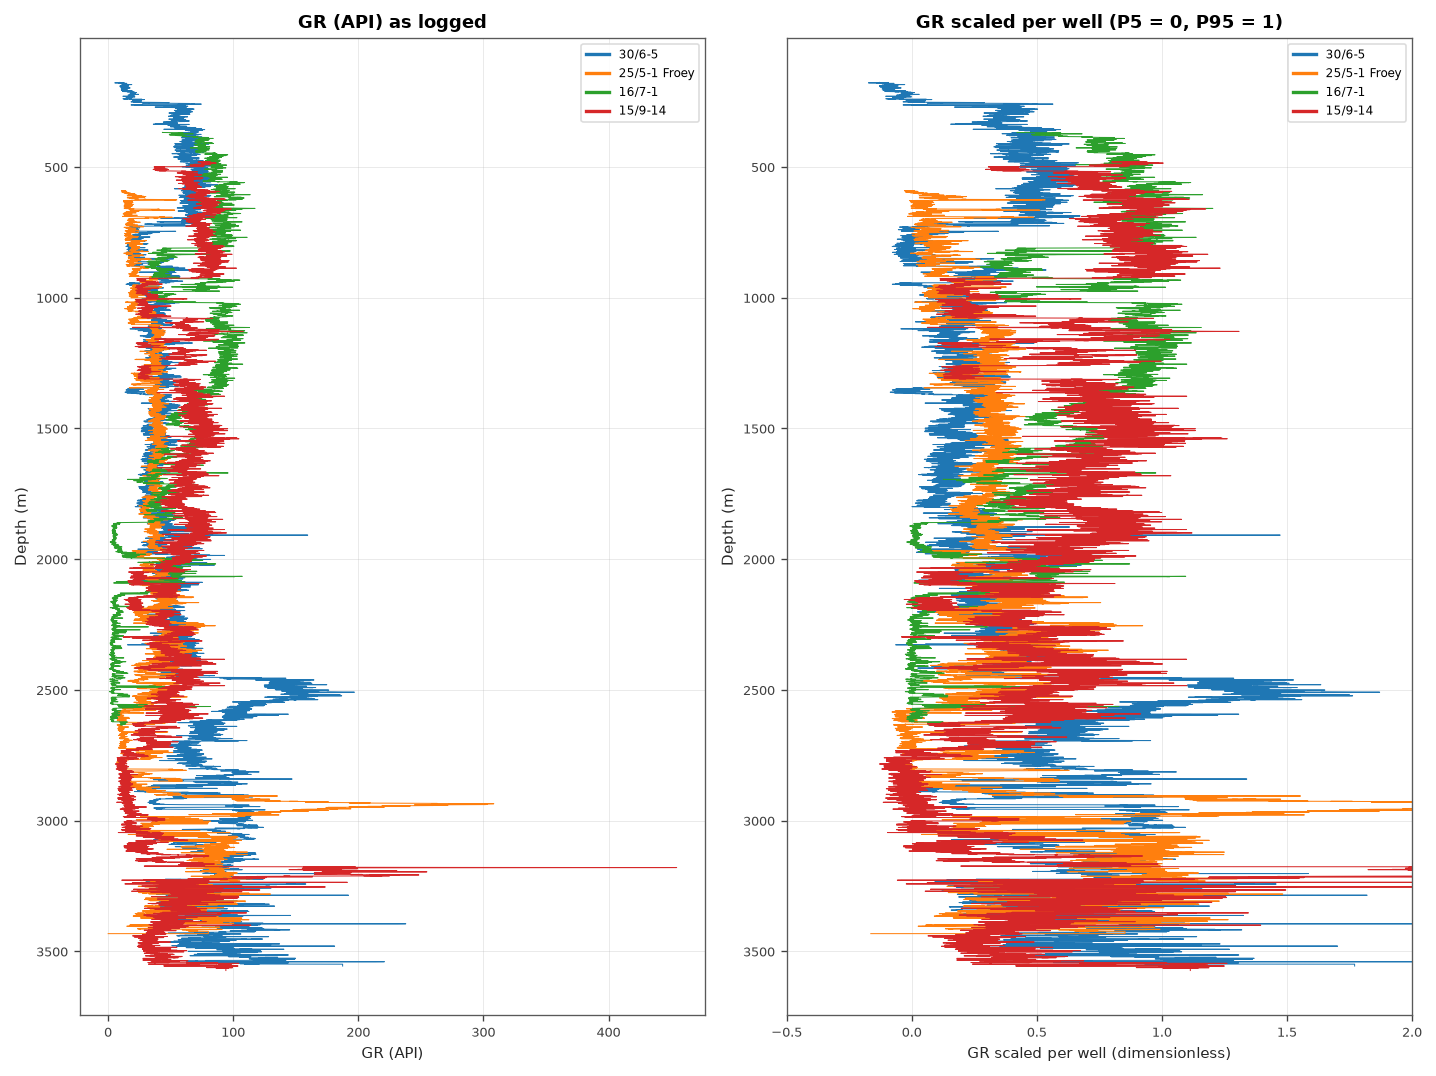

In [48]:
from petrophys.visualization import (
    create_multiwell_overlay, create_bar_comparison, create_histogram_comparison,
)

field_wells = [res.well for res in field.values()]
fig, axes = plt.subplots(1, 2, figsize=(12, 9))       # each call inverts its own depth axis
create_multiwell_overlay(field_wells, "GR", title="GR (API) as logged", ax=axes[0])
create_multiwell_overlay(field_wells, "GR", normalize=True, title="GR scaled per well (P5 = 0, P95 = 1)",
                         ax=axes[1])
axes[1].set_xlim(-0.5, 2.0)
axes[0].set_xlabel("GR (API)"); axes[1].set_xlabel("GR scaled per well (dimensionless)")
for ax in axes:
    ax.set_ylabel("Depth (m)")
plt.tight_layout()
plt.show()

Of these four wells only 30/6-5 ships formation tops, so a
formation-by-formation comparison is not possible for the other three. What we can compare honestly is **where**
each well's net-pay flags sit. The grouped bars count flagged net pay in 500 m
depth slices.

Flagged net pay (m) by depth slice (m):
            30/6-5  25/5-1 Froey  16/7-1  15/9-14
0-500          0.0           0.0     0.0      0.0
500-1000       0.8           0.6     0.0      0.0
1000-1500     17.2         197.8     0.0      0.2
1500-2000      0.0           1.7     0.0      0.0
2000-2500      0.0           2.0     0.0      0.0
2500-3000     24.5          12.6     2.1      5.6
3000-3500      0.8          41.1     0.0      4.9
3500-4000      0.0           0.0     0.0      0.6
whole well    43.3         255.9     2.1     11.3

Share of each well's flagged net pay above 1500 m: 30/6-5 42%, 25/5-1 Froey 78%, 16/7-1 0%, 15/9-14 1%


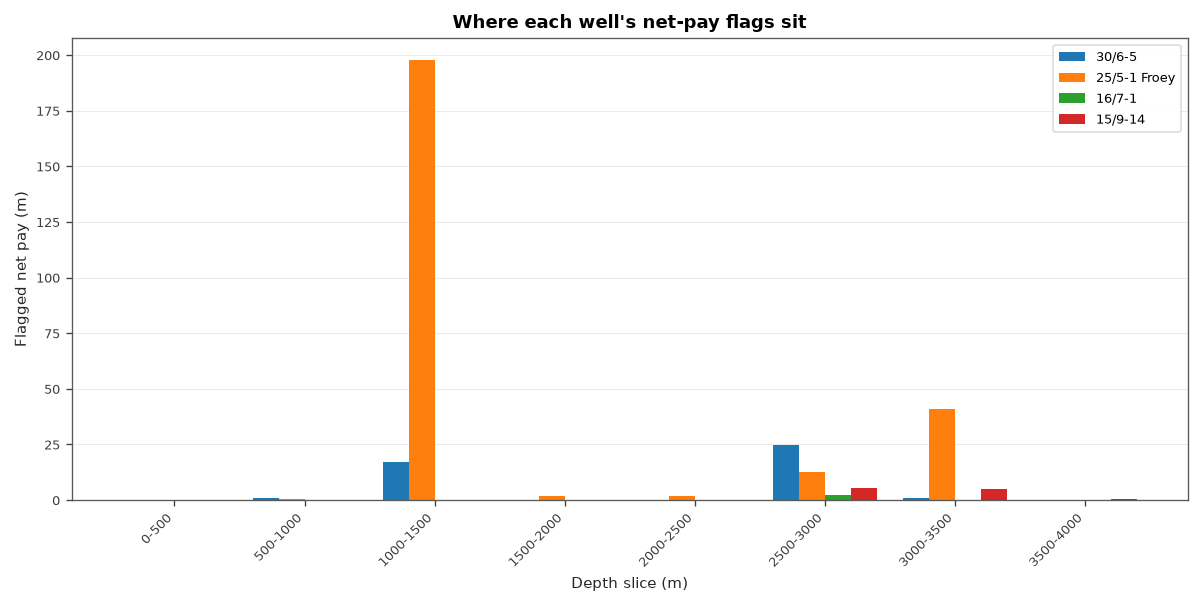

In [49]:
slices = list(range(0, 4000, 500))
labels = [f"{top}-{top + 500}" for top in slices]
pay_by_slice = {}
for res in field.values():
    w = res.well
    flag = w["NET_PAY"].data > 0.5
    pay_by_slice[w.name] = [flag[(w.depth >= top) & (w.depth < top + 500)].sum() * w.step for top in slices]
slice_table = pd.DataFrame(pay_by_slice, index=labels)
slice_table.loc["whole well"] = [res.summary()["net_thickness"]["net_pay"] for res in field.values()]
print("Flagged net pay (m) by depth slice (m):")
print(slice_table.round(1).to_string())
shallow = slice_table.iloc[:3].sum() / slice_table.loc["whole well"]
print("\nShare of each well's flagged net pay above 1500 m:",
      ", ".join(f"{name} {share:.0%}" for name, share in shallow.items()))

well_colors = [plt.cm.tab10(i) for i in range(len(pay_by_slice))]   # same colours as the overlay above
fig, ax = create_bar_comparison(labels, pay_by_slice, colors=well_colors, xlabel="Depth slice (m)",
                                ylabel="Flagged net pay (m)",
                                title="Where each well's net-pay flags sit", figsize=(12, 5))
plt.show()

Read the table well by well. Flags above about 1500 m sit in young, poorly
compacted sediment: the whole-well-total trap from section 8, repeated across
the field. One Rw, corrected for temperature at constant salinity, serves each
whole well although shallow formation water is usually fresher, and the clay
indicators disagree in soft mudstone, so shallow flags stay suspect wherever
they appear. Deeper flags near each well's known reservoir are the candidates,
but every well still needs its own reservoir window from tops or a geological
correlation before wells are compared on pay.

A property comparison that does not depend on tops: the porosity distribution
of each well's **net-reservoir** samples below 2000 m.

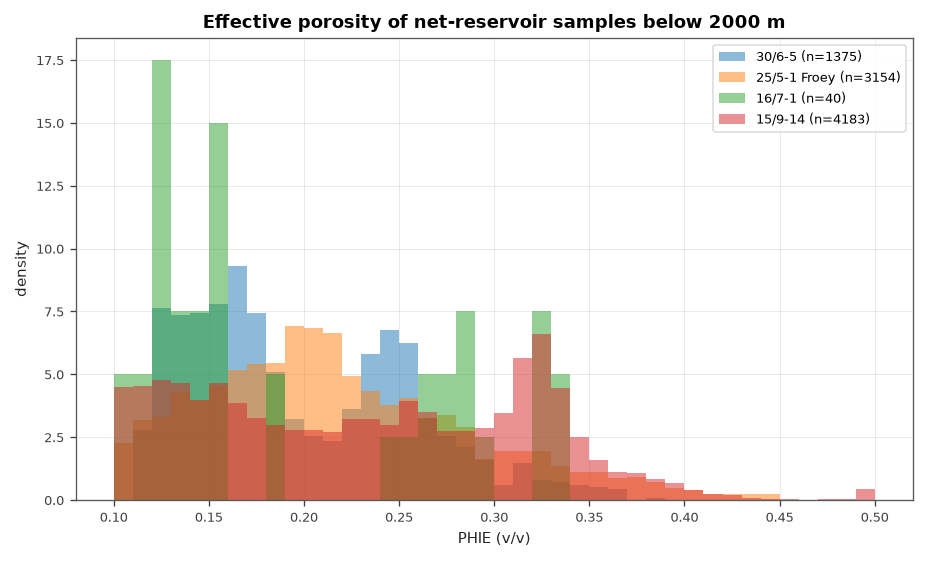

In [50]:
porosity_sets = {}
for res in field.values():
    w = res.well
    keep = (w["NET_RES"].data > 0.5) & (w.depth >= 2000.0)
    porosity_sets[f"{w.name} (n={keep.sum()})"] = w["PHIE"].data[keep]
fig, ax = create_histogram_comparison(porosity_sets, bins=40, density=True, xlabel="PHIE (v/v)",
                                      title="Effective porosity of net-reservoir samples below 2000 m")
plt.show()

The distributions differ in shape as well as position. Before comparing
numbers across wells, check that their porosity rests on the same inputs:
16/7-1's porosity is density-only, so its distribution is not directly
comparable with the neutron-density porosity of the other three.

---
## 12. Additional reservoir calculations

`petrophys.evaluation` adds the standard reservoir-quality measures:

- **Bulk volume water** BVW = PHIE x Sw. At irreducible saturation BVW is
  roughly constant, so points on a hyperbola in a PHIE-Sw crossplot (a Buckles
  plot) suggest rock that will produce water-free.
- **Rock quality index** RQI = 0.0314 sqrt(k / PHIE) (micrometres), the
  **normalized porosity** phi_z = PHIE / (1 - PHIE), and the **flow zone
  indicator** FZI = RQI / phi_z. Rock with similar FZI flows alike (a hydraulic
  flow unit).

We compute them on the step-by-step well.

Brent net-pay samples: 255
   median BVW 0.067, RQI 1.51 um, FZI 5.36 um


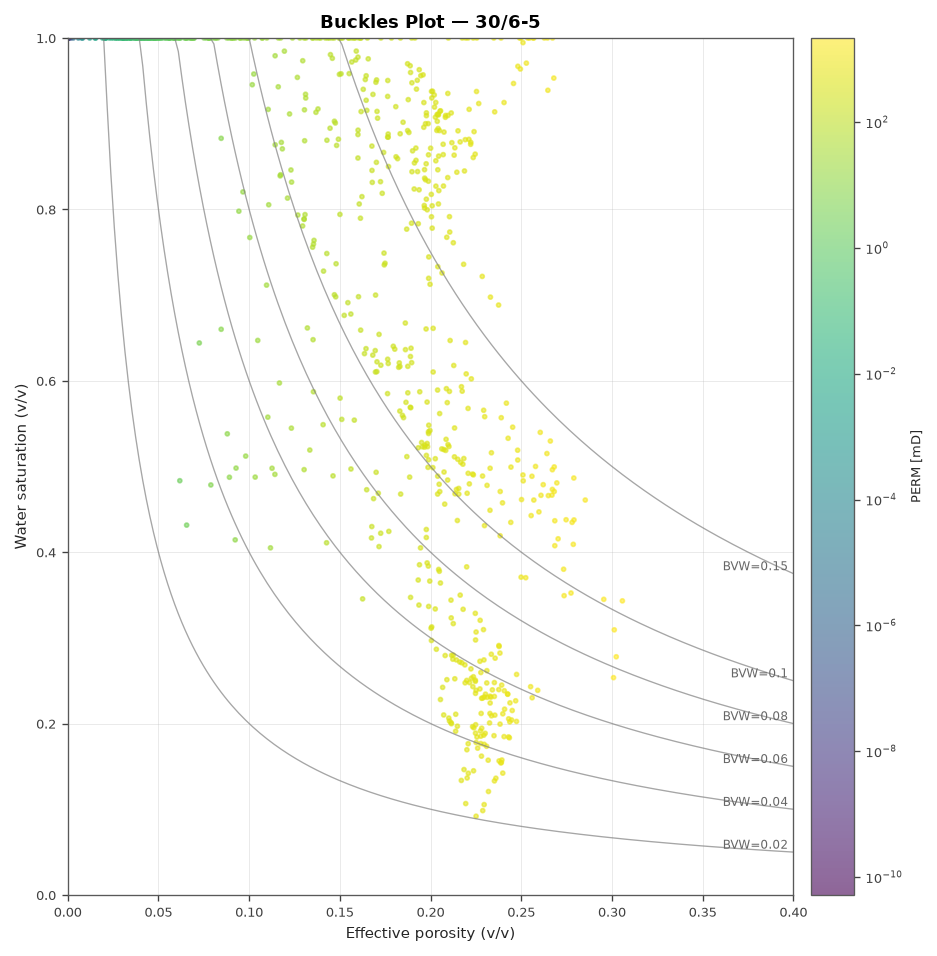

In [51]:
from petrophys.evaluation import calculate_bvw, calculate_rqi, calculate_phi_z, calculate_fzi
from petrophys.visualization import create_buckles_plot

perm = well["PERM"].data
bvw = calculate_bvw(phie, sw)
rqi = calculate_rqi(perm, phie)
phi_z = calculate_phi_z(phie)
fzi = calculate_fzi(rqi, phi_z)
for name, values, unit in [("BVW", bvw, "v/v"), ("RQI", rqi, "um"), ("PHI_Z", phi_z, "v/v"), ("FZI", fzi, "um")]:
    well.add_curve(name, values, unit, name)
pay = in_brent & (well["NET_PAY"].data > 0.5)
print(f"Brent net-pay samples: {pay.sum()}")
print(f"   median BVW {np.nanmedian(bvw[pay]):.3f}, RQI {np.nanmedian(rqi[pay]):.2f} um, "
      f"FZI {np.nanmedian(fzi[pay]):.2f} um")

fig = create_buckles_plot(well, phie_curve="PHIE", sw_curve="SW", color_curve="PERM",
                          depth_range=(BRENT_TOP, BRENT_BASE))
plt.show()

Flow units are best defined on core, where porosity and permeability are both
measured. `calculate_flow_units` groups the plugs by FZI and
`create_flow_unit_plot` draws each unit as a line of constant FZI in RQI-phi_z
space.

198 plugs -> 6 flow units
Plugs per unit: [44 30 23 28 40 33]
Mean FZI per unit (um): [0.33 0.64 1.4  2.89 4.78 8.95]


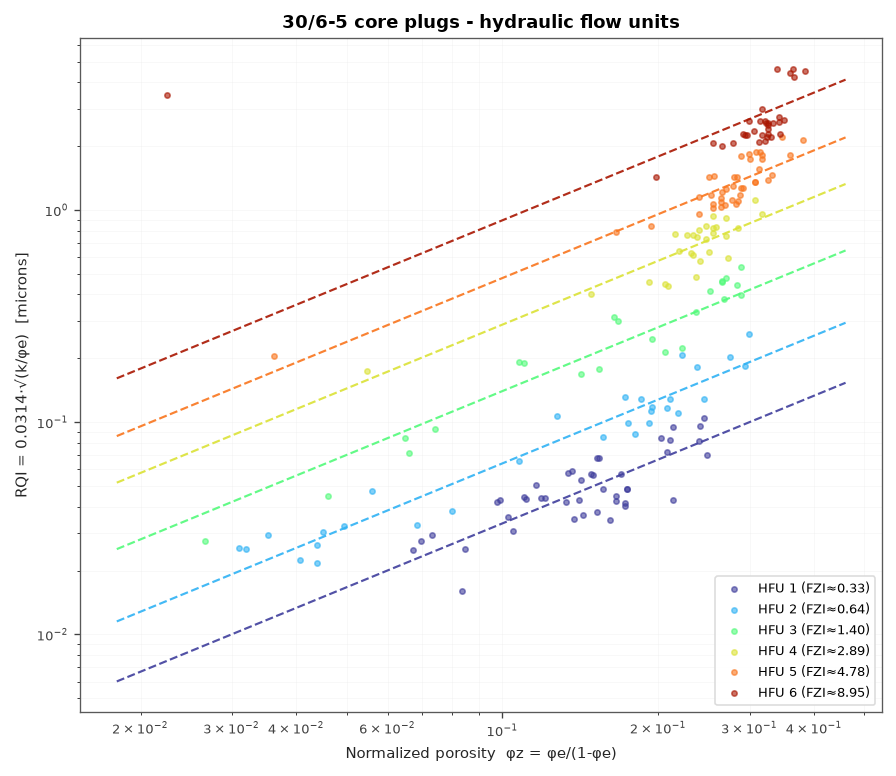

In [52]:
from petrophys.evaluation import calculate_flow_units
from petrophys.visualization import create_flow_unit_plot

core_pairs = np.isfinite(well["PHIC"].data) & np.isfinite(kh) & (kh > 0)
units = calculate_flow_units(kh[core_pairs], well["PHIC"].data[core_pairs])
print(f"{core_pairs.sum()} plugs -> {units.n_units} flow units")
print("Plugs per unit:", units.counts)
print("Mean FZI per unit (um):", np.round(units.fzi_unit_mean, 2))
create_flow_unit_plot(result=units, title=f"{well.name} core plugs - hydraulic flow units")
plt.show()

---
## 13. Zone summaries and hydrocarbon pore volume

`petrophys.evaluation.summaries` is the arithmetic under the interval analysis:
thicknesses, net-to-gross and pay averages for any depth window, without
building interval objects.

In [53]:
from petrophys.evaluation.summaries import (
    calculate_zone_summary, summarize_zones, calculate_net_gross,
    calculate_hcpv, calculate_ooip, calculate_ogip,
)

zone = calculate_zone_summary(well, top_depth=BRENT_TOP, bottom_depth=BRENT_BASE, zone_name="Brent Group")
ng = calculate_net_gross(well, top_depth=BRENT_TOP, bottom_depth=BRENT_BASE)
print(f"{zone.zone_name}: gross {zone.gross_thickness:.1f} m, net pay {zone.net_pay:.1f} m, "
      f"NTG {zone.ntg:.1%}")
print(f"   net rock/gross {ng.ntg_rock:.1%}, net reservoir/gross {ng.ntg_reservoir:.1%}, "
      f"net pay/net reservoir {ng.ntg_pay_res:.1%}")
print(f"   pay averages: PHIE {zone.avg_phie:.3f}, Sw {zone.avg_sw:.3f}, VCL {zone.avg_vcl:.3f}")

zones = [
    {"name": "Heather Fm.", "top": 2593.0, "bottom": 2841.0},
    {"name": "Ness Fm.", "top": 2841.0, "bottom": 2865.0},
    {"name": "Etive Fm.", "top": 2865.0, "bottom": 2958.0},
    {"name": "Cook Fm.", "top": 3071.0, "bottom": 3123.0},
    {"name": "Statfjord Fm.", "top": 3223.0, "bottom": 3556.0},
]
rows = [{"Zone": z.zone_name, "Gross (m)": z.gross_thickness, "Net pay (m)": z.net_pay, "NTG": z.ntg,
         "PHIE": z.avg_phie, "Sw": z.avg_sw, "HCPV index (m)": z.hcpv}
        for z in summarize_zones(well, zones)]
print()
print(pd.DataFrame(rows).round(3).to_string(index=False))

Brent Group: gross 117.0 m, net pay 38.9 m, NTG 33.2%
   net rock/gross 78.1%, net reservoir/gross 71.9%, net pay/net reservoir 46.2%
   pay averages: PHIE 0.215, Sw 0.352, VCL 0.050

         Zone  Gross (m)  Net pay (m)   NTG  PHIE    Sw  HCPV index (m)
  Heather Fm.    247.955       32.613 0.132 0.138 0.521           2.156
     Ness Fm.     24.079        9.754 0.405 0.223 0.510           1.076
    Etive Fm.     92.964       29.109 0.313 0.212 0.299           4.413
     Cook Fm.     51.968        0.152 0.003 0.154 0.600           0.009
Statfjord Fm.    332.994        2.286 0.007 0.237 0.427           0.329


The HCPV index is a thickness: the sum of PHIE x (1 - Sw) x step over the pay
samples. Turning it into a volume needs an area and fluid properties, which no
log provides. The cell below uses **illustrative assumptions** (a 640-acre
drainage area, Bo = 1.2 rb/stb, Bg = 0.005 rcf/scf (reservoir cubic feet per standard cubic foot, the unit
`calculate_ogip` expects) and the library's default
recovery factors) with the log-derived Brent pay, porosity and saturation. The
result shows the arithmetic; it is not a resource estimate.

In [54]:
AREA_ACRES, BO, BG = 640.0, 1.2, 0.005           # illustrative assumptions, not measurements
net_pay_ft = zone.net_pay * 3.28084

hcpv = calculate_hcpv(area_acres=AREA_ACRES, net_pay_ft=net_pay_ft, porosity=zone.avg_phie,
                      sw=zone.avg_sw, bo=BO, bg=BG)
ooip = calculate_ooip(area_acres=AREA_ACRES, net_pay_ft=net_pay_ft, porosity=zone.avg_phie,
                      sw=zone.avg_sw, bo=BO)
ogip = calculate_ogip(area_acres=AREA_ACRES, net_pay_ft=net_pay_ft, porosity=zone.avg_phie,
                      sw=zone.avg_sw, bg=BG)
print(f"Inputs: {net_pay_ft:.1f} ft net pay, PHIE {zone.avg_phie:.3f}, Sw {zone.avg_sw:.3f}, "
      f"{AREA_ACRES:.0f} acres")
print(f"HCPV            : {hcpv.hcpv_acft:,.0f} acre-ft = {hcpv.hcpv_m3 / 1e6:.2f} million m3")
print(f"If oil (Bo {BO} rb/stb) : OOIP {ooip['ooip_mmbbl']:.1f} MMstb, "
      f"recoverable {ooip['recoverable_stb'] / 1e6:.1f} MMstb at RF {ooip['recovery_factor']:.0%}")
print(f"If gas (Bg {BG} rcf/scf): OGIP {ogip['ogip_bcf']:.1f} Bcf, "
      f"recoverable {ogip['recoverable_bcf']:.1f} Bcf at RF {ogip['recovery_factor']:.0%}")

Inputs: 127.5 ft net pay, PHIE 0.215, Sw 0.352, 640 acres
HCPV            : 11,359 acre-ft = 14.01 million m3
If oil (Bo 1.2 rb/stb) : OOIP 73.4 MMstb, recoverable 22.0 MMstb at RF 30%
If gas (Bg 0.005 rcf/scf): OGIP 99.0 Bcf, recoverable 69.3 Bcf at RF 70%


---
## 14. Exporting results

A workflow result writes itself to LAS (all curves, with the settings in the
header) and to JSON (the trace and summary, optionally with curves). For the
step-by-step well, `petrophys.io` has LAS, CSV and Excel writers, and the
interval tools write their own tables. We write into a temporary folder and
list what was created.

In [55]:
from petrophys.io import export_las, export_csv, export_excel

with tempfile.TemporaryDirectory() as folder:
    out = Path(folder)
    result.to_las(out / "30_6-5_interpreted.las")
    result.to_json(out / "30_6-5_trace.json")
    key_curves = ["GR", "VCL", "PHIE", "SW", "PERM", "NET_PAY"]
    export_las(well, out / "30_6-5_step_by_step.las", curves=key_curves)
    export_csv(well, out / "30_6-5_step_by_step.csv", curves=key_curves)
    export_excel(well.depth_slice(BRENT_TOP, BRENT_BASE), out / "30_6-5_brent.xlsx", curves=key_curves)
    IntervalAnalyzer.to_csv(summaries, out / "30_6-5_formation_summary.csv")
    by_formation.to_csv(out / "30_6-5_workflow_formations.csv", index=False)
    for path in sorted(out.iterdir()):
        print(f"{path.name:<36s} {path.stat().st_size / 1024:10.1f} kB")

print()
print(well.depth_slice(BRENT_TOP, BRENT_BASE).to_dataframe()[key_curves].describe().round(3).to_string())

30_6-5_brent.xlsx                          55.7 kB
30_6-5_formation_summary.csv                2.3 kB
30_6-5_interpreted.las                  15065.2 kB
30_6-5_step_by_step.csv                  1974.9 kB
30_6-5_step_by_step.las                  1713.2 kB
30_6-5_trace.json                          52.9 kB
30_6-5_workflow_formations.csv              3.1 kB

            GR      VCL     PHIE       SW      PERM  NET_PAY
count  768.000  768.000  768.000  758.000   768.000  768.000
mean    60.025    0.175    0.166    0.690   338.027    0.332
std     27.216    0.235    0.074    0.292   348.467    0.471
min     21.281    0.000    0.000    0.092     0.000    0.000
25%     37.281    0.000    0.118    0.467    33.088    0.000
50%     52.470    0.029    0.192    0.789   280.801    0.000
75%     85.478    0.339    0.221    1.000   516.875    1.000
max    130.875    0.857    0.306    1.000  2169.423    1.000


---
## 15. Core data and log-core calibration

30/6-5 stores its laboratory measurements as LAS curves: `PHIC` (helium
porosity), `KH_CORE` and `KV_CORE` (Klinkenberg permeability), `GDEN` (grain
density), and `SWC`/`SOC` (Dean-Stark saturations). Only the plug depths hold
values. `core_data_from_well` collects them into a `CoreData` object, and
`petrophys.interpretation.core_analysis` then lets us:

- compare core and log porosity and permeability (R², bias, RMSE);
- fit a porosity correction and a log poro-perm transform, and apply them;
- recompute density porosity with the measured grain density;
- back-calculate Archie's m from core saturation.

We calibrate the curves from `pp.interpret` (section 10). The plotting helpers
live in `petrophys.visualization.core`.

In [56]:
from petrophys.interpretation.core_analysis import (
    core_data_from_well, calibrate_porosity, calibrate_permeability, calibrate_saturation,
    fit_porosity_correction, apply_porosity_correction, fit_log_poro_perm_transform,
    apply_poro_perm_transform, correct_porosity_with_grain_density, estimate_archie_m,
    interpolate_log_at_core, CoreData,
)
from petrophys.visualization.core import plot_calibration, plot_poro_perm, plot_core_on_logs

core = core_data_from_well(interp)
print(core)
print(f"Cored interval: {core.top:.1f} - {core.bottom:.1f} m")
print("Valid values:", {name: int(np.isfinite(getattr(core, name)).sum())
                        for name in ["porosity", "permeability", "grain_density", "sw", "so"]})
core.to_dataframe()[["DEPTH", "CPOR", "CPERM", "CGD", "CSW", "CSO"]].describe().round(3)

CoreData(plugs=201, depth=2800.5-2947.9, props=[porosity, perm, GD, Sw])
Cored interval: 2800.5 - 2947.9 m
Valid values: {'porosity': 200, 'permeability': 198, 'grain_density': 200, 'sw': 74, 'so': 44}


,DEPTH,CPOR,CPERM,CGD,CSW,CSO
count,201.000,200.000,198.000,200.000,74.000,44.000
mean,2901.603,0.174,436.942,2.678,0.482,0.060
std,25.442,0.064,948.796,0.053,0.159,0.041
min,2800.481,0.022,0.020,2.470,0.137,0.006
25%,2884.758,0.132,0.512,2.650,0.366,0.034
50%,2904.266,0.192,44.500,2.670,0.474,0.054
75%,2921.792,0.224,404.500,2.690,0.601,0.079
max,2947.852,0.277,5826.000,3.060,0.846,0.169


PHIE vs core porosity              n=200  R2=0.546  bias=-0.0742  RMSE=0.0936
log10 PERM vs log10 core KH        n=198  R2=0.621  bias=-1.6947  RMSE=3.2867
log10 PERM_CC vs log10 core KH     n=198  R2=0.615  bias=+0.1290  RMSE=0.9874
PHIT vs core porosity              n=200  R2=0.572  bias=+0.0125  RMSE=0.0440

Plugs where PHIE = 0: 57 (their mean core porosity 0.106)
Plugs where PERM <= 0.001 mD: 58; log10 PERM bias without them: -0.013


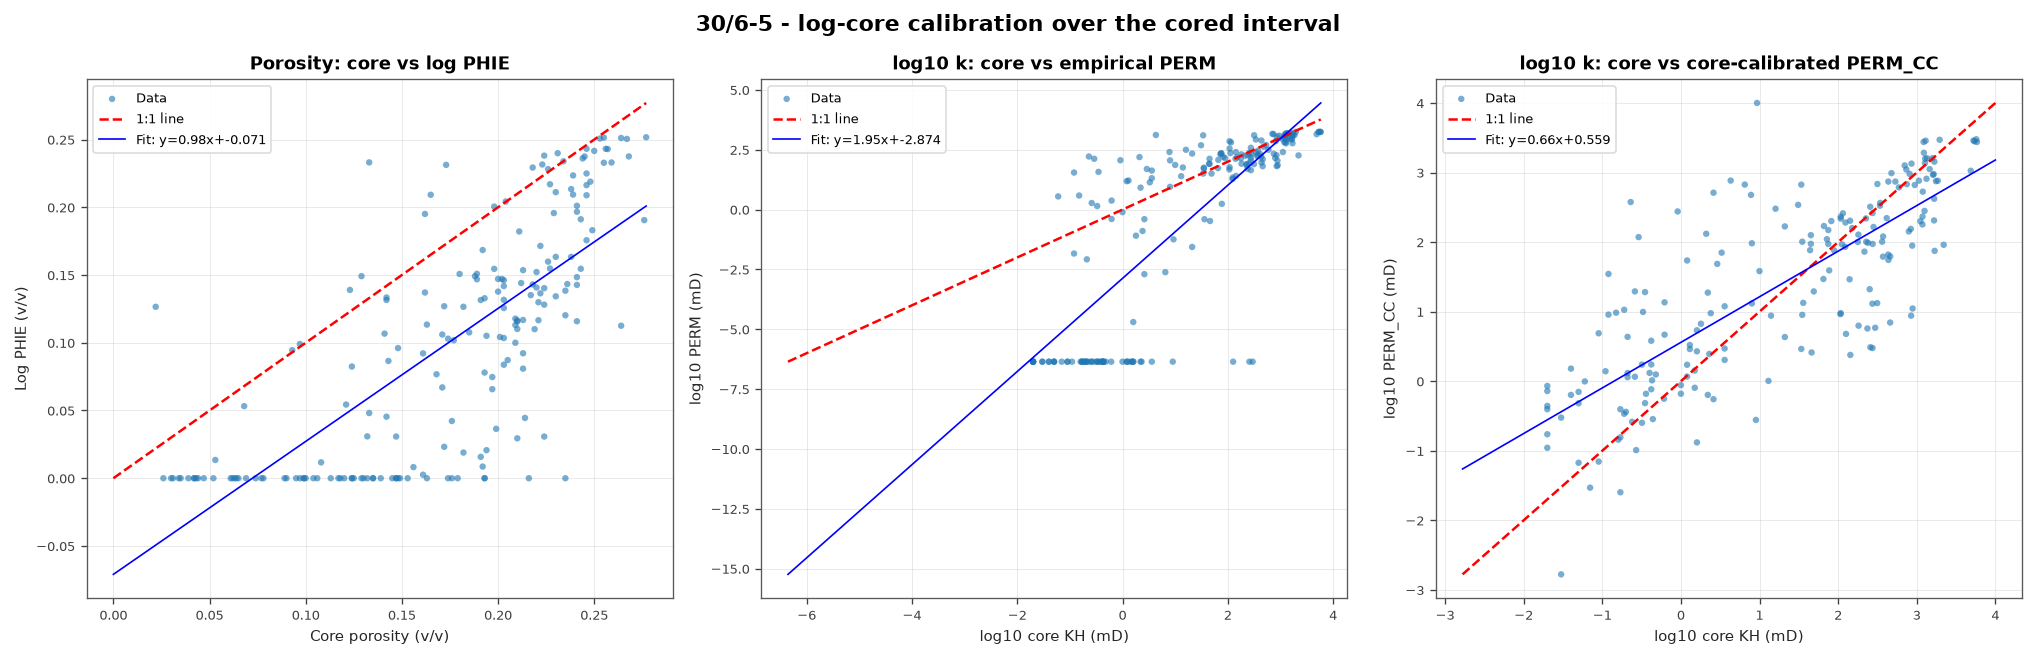

In [57]:
def show_calibration(label, cal):
    print(f"{label:<34s} n={cal.n_points:3d}  R2={cal.r_squared:.3f}  "
          f"bias={cal.bias:+.4f}  RMSE={cal.rmse:.4f}")


phi_cal = calibrate_porosity(interp, core, log_curve="PHIE")
perm_cal = calibrate_permeability(interp, core, log_curve="PERM", log_scale=True)
perm_cc_cal = calibrate_permeability(interp, core, log_curve="PERM_CC", log_scale=True)
show_calibration("PHIE vs core porosity", phi_cal)
show_calibration("log10 PERM vs log10 core KH", perm_cal)
show_calibration("log10 PERM_CC vs log10 core KH", perm_cc_cal)
show_calibration("PHIT vs core porosity", calibrate_porosity(interp, core, log_curve="PHIT"))

phie_at_plugs = interpolate_log_at_core(interp, core, "PHIE")
perm_at_plugs = interpolate_log_at_core(interp, core, "PERM")
zero_phie = phie_at_plugs <= 0.0
print(f"\nPlugs where PHIE = 0: {zero_phie.sum()} (their mean core porosity "
      f"{np.nanmean(core.porosity[zero_phie]):.3f})")
floored = perm_at_plugs <= 1e-3
usable = ~floored & np.isfinite(perm_at_plugs) & (core.permeability > 0)
print(f"Plugs where PERM <= 0.001 mD: {floored.sum()}; log10 PERM bias without them: "
      f"{np.nanmean(np.log10(perm_at_plugs[usable]) - np.log10(core.permeability[usable])):+.3f}")

fig, axes = plt.subplots(1, 3, figsize=(17, 5.5))
plot_calibration(phi_cal, ax=axes[0], title="Porosity: core vs log PHIE")
plot_calibration(perm_cal, ax=axes[1], title="log10 k: core vs empirical PERM")
plot_calibration(perm_cc_cal, ax=axes[2], title="log10 k: core vs core-calibrated PERM_CC")
axes[0].set_xlabel("Core porosity (v/v)"); axes[0].set_ylabel("Log PHIE (v/v)")
for ax, name in zip(axes[1:], ["PERM", "PERM_CC"]):
    ax.set_xlabel("log10 core KH (mD)"); ax.set_ylabel(f"log10 {name} (mD)")
fig.suptitle(f"{interp.name} - log-core calibration over the cored interval", fontweight="bold")
plt.tight_layout()
plt.show()

Read the signs: bias is the mean of log minus core. **PHIE reads low**, by about
0.07 v/v on average, which is large next to a mean plug porosity of 0.17. Most
of that is the comparison itself: plug helium porosity is total porosity, while
PHIE has the clay-bound part removed. PHIT, the like-for-like curve, is biased
by only about +0.01. The gap is concentrated in the plugs where PHIE is zero
although the plugs measure about 0.1 porosity: the workflow's clay volume calls
those depths shale and removes all of their porosity as clay-bound.

**The empirical `PERM` also reads low** on average (a bias of about -1.7 in
log10 space), but the printed breakdown shows that this comes almost entirely
from the plugs where `PERM` has collapsed to practically zero with PHIE; without
them the bias is close to zero. The workflow's core-calibrated `PERM_CC` has a
small bias and a much smaller RMSE, which is the reason to calibrate
permeability whenever core exists.

The next cell does the calibration by hand: fit a linear porosity correction
to the core, then fit log10(k) against the corrected log porosity at the plug
depths, and apply both to the whole well.

PorosityCorrection(PHIcore = 0.406*PHIE + 0.144, R^2=0.338, RMSE=0.0366, n=140)
PHIE_CORECAL vs core porosity      n=200  R2=0.546  bias=+0.0107  RMSE=0.0460
PoroPermTransform(log10(K) = 38.11*PHI + (-5.80), R²=0.697, n=198)

Median permeability at the plug depths: core 44.5 mD, PERM_CORECAL 23.0 mD, PERM 59.4 mD


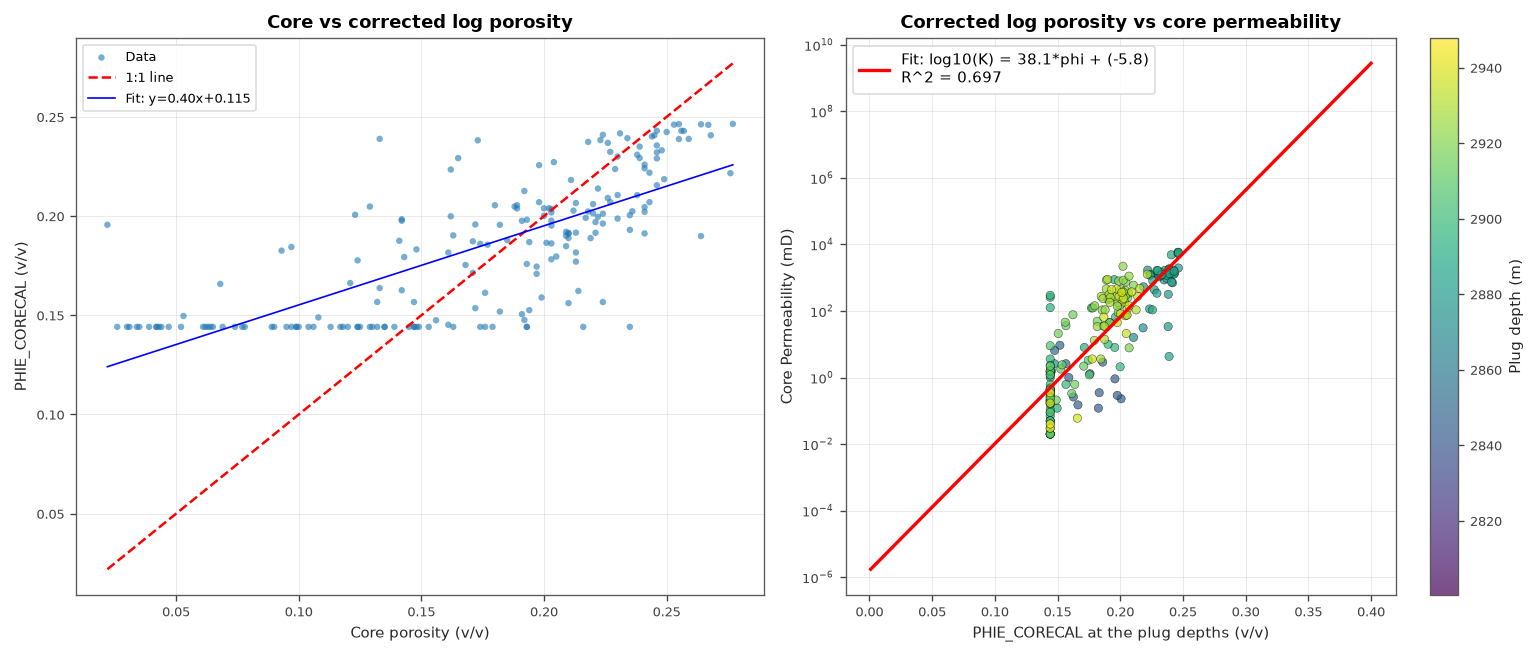

In [58]:
correction = fit_porosity_correction(interp, core, log_curve="PHIE")
print(correction)
phie_corecal = apply_porosity_correction(interp, correction, output_curve="PHIE_CORECAL")
corrected_cal = calibrate_porosity(interp, core, log_curve="PHIE_CORECAL")
show_calibration("PHIE_CORECAL vs core porosity", corrected_cal)

transform = fit_log_poro_perm_transform(interp, core, porosity_curve="PHIE_CORECAL")
print(transform)
perm_corecal = apply_poro_perm_transform(interp, transform, porosity_curve="PHIE_CORECAL",
                                         output_curve="PERM_CORECAL")

at_plugs = interpolate_log_at_core(interp, core, "PERM_CORECAL")
print(f"\nMedian permeability at the plug depths: core {np.nanmedian(core.permeability):.1f} mD, "
      f"PERM_CORECAL {np.nanmedian(at_plugs):.1f} mD, "
      f"PERM {np.nanmedian(interpolate_log_at_core(interp, core, 'PERM')):.1f} mD")

log_phi_at_core = CoreData(depth=core.depth,
                           porosity=interpolate_log_at_core(interp, core, "PHIE_CORECAL"),
                           permeability=core.permeability)
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
plot_calibration(corrected_cal, ax=axes[0], title="Core vs corrected log porosity")
axes[0].set_xlabel("Core porosity (v/v)"); axes[0].set_ylabel("PHIE_CORECAL (v/v)")
plot_poro_perm(log_phi_at_core, transform=transform, ax=axes[1],
               title="Corrected log porosity vs core permeability")
axes[1].set_xlabel("PHIE_CORECAL at the plug depths (v/v)")
fig.axes[-1].set_ylabel("Plug depth (m)")                # colour bar of the poro-perm panel
plt.tight_layout()
plt.show()

Two warnings about this hand calibration. First, the porosity correction is
weak: its R² of about 0.34 is below the 0.5 that the workflow's own
`core_correction` step requires before it uses a porosity fit. The fit leaves
out plugs where PHIE is (near) zero, but applying it maps every PHIE = 0 sample
to the intercept, about 0.14. That is the vertical stack of points in both
panels, and it gives every shale in the well a `PHIE_CORECAL` of about 0.14.
The poro-perm transform is then fitted through that stack. Second, a transform
is only supported inside the porosity range and the interval the plugs cover;
the fitted line drawn out to a porosity of 0.4 predicts absurd permeabilities.
Outside the cored Brent (for example in the soft shallow section) it
extrapolates, which is why we compared medians at the plug depths only. Use
these curves as a demonstration of the functions, not as a deliverable.

**Grain density.** Density porosity with a fixed 2.65 g/cm3 matrix is biased
where the real grain density differs. `correct_porosity_with_grain_density`
uses the measured grain density at the plug depths, interpolated between them.

In [59]:
phid_core = correct_porosity_with_grain_density(interp, core, rhob_curve="RHOB", rho_fluid=1.0,
                                                default_rho_ma=2.65, output_curve="PHID_CORE")
interp.add_curve("PHID_265", density_porosity(interp["RHOB"].data, 2.65, 1.0), "v/v",
                 "Density porosity, fixed 2.65 matrix")
show_calibration("PHID (fixed 2.65) vs core", calibrate_porosity(interp, core, log_curve="PHID_265"))
show_calibration("PHID_CORE (core grain density)", calibrate_porosity(interp, core, log_curve="PHID_CORE"))

PHID (fixed 2.65) vs core          n=200  R2=0.645  bias=-0.0198  RMSE=0.0461
PHID_CORE (core grain density)     n=200  R2=0.537  bias=-0.0063  RMSE=0.0472


The measured grain density moves the bias towards zero, but the scatter does
not improve: grain density is only known at the plugs and is interpolated in
between, so it adds noise of its own. A bias fix is still worth having, because
a bias shifts every volume computed from the porosity.

**Archie's m from core.** Where a plug has both porosity and a Dean-Stark water
saturation, Archie's equation can be solved for m, given Rw, a, n and the deep
resistivity at that depth. We use Rw corrected to the temperature of the cored
interval.

Rw at cored-interval temperature: 0.0724 ohm.m (a = 0.8, n = 2.0)
m from 66 plugs: median 1.66, mean 1.79, std 0.66
log SW vs core SWC                 n= 74  R2=0.109  bias=+0.2317  RMSE=0.3831


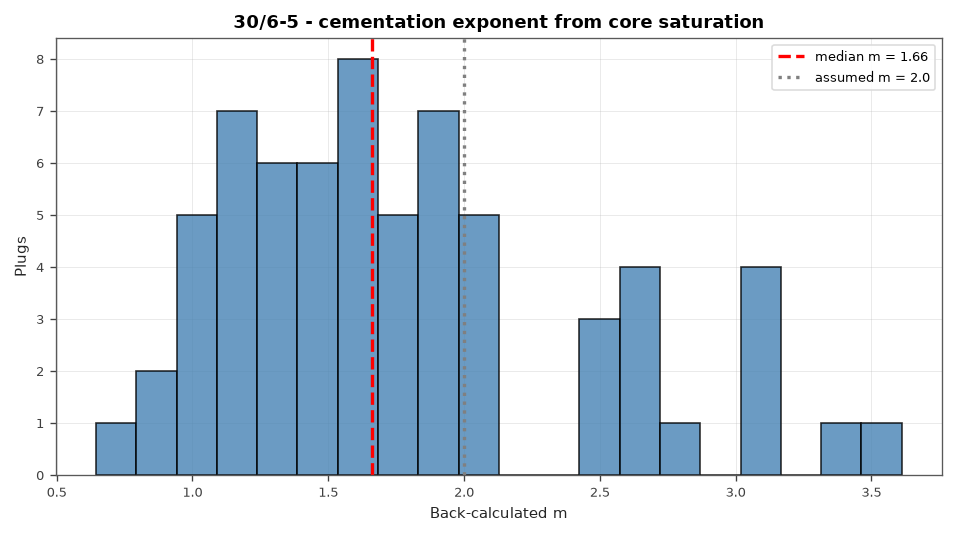

In [60]:
cored = (interp.depth >= core.top) & (interp.depth <= core.bottom)
rw_cored = float(np.nanmedian(interp["RW"].data[cored]))
m_estimate = estimate_archie_m(interp, core, rw=rw_cored, rt_curve="RDEP", a=A, n=N)
print(f"Rw at cored-interval temperature: {rw_cored:.4f} ohm.m (a = {A}, n = {N})")
print(f"m from {m_estimate['n_points']} plugs: median {m_estimate['m_median']:.2f}, "
      f"mean {m_estimate['m_mean']:.2f}, std {m_estimate['m_std']:.2f}")
sw_cal = calibrate_saturation(interp, core, log_curve="SW")
show_calibration("log SW vs core SWC", sw_cal)

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.hist(m_estimate["m_values"], bins=20, color="steelblue", edgecolor="black", alpha=0.8)
ax.axvline(m_estimate["m_median"], color="red", ls="--", lw=2,
           label=f"median m = {m_estimate['m_median']:.2f}")
ax.axvline(M, color="gray", ls=":", lw=2, label=f"assumed m = {M}")
ax.set_xlabel("Back-calculated m"); ax.set_ylabel("Plugs"); ax.legend()
ax.set_title(f"{interp.name} - cementation exponent from core saturation")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

The spread is wide and the log-core saturation match is weak. Dean-Stark
saturations on conventional core are altered by filtrate invasion and by gas
expansion as the core is brought up, so an m derived from them is a check
on the assumed value, not a replacement for special core analysis
(resistivity-index and formation-factor measurements).

Core points plotted on the log tracks show the match depth by depth.

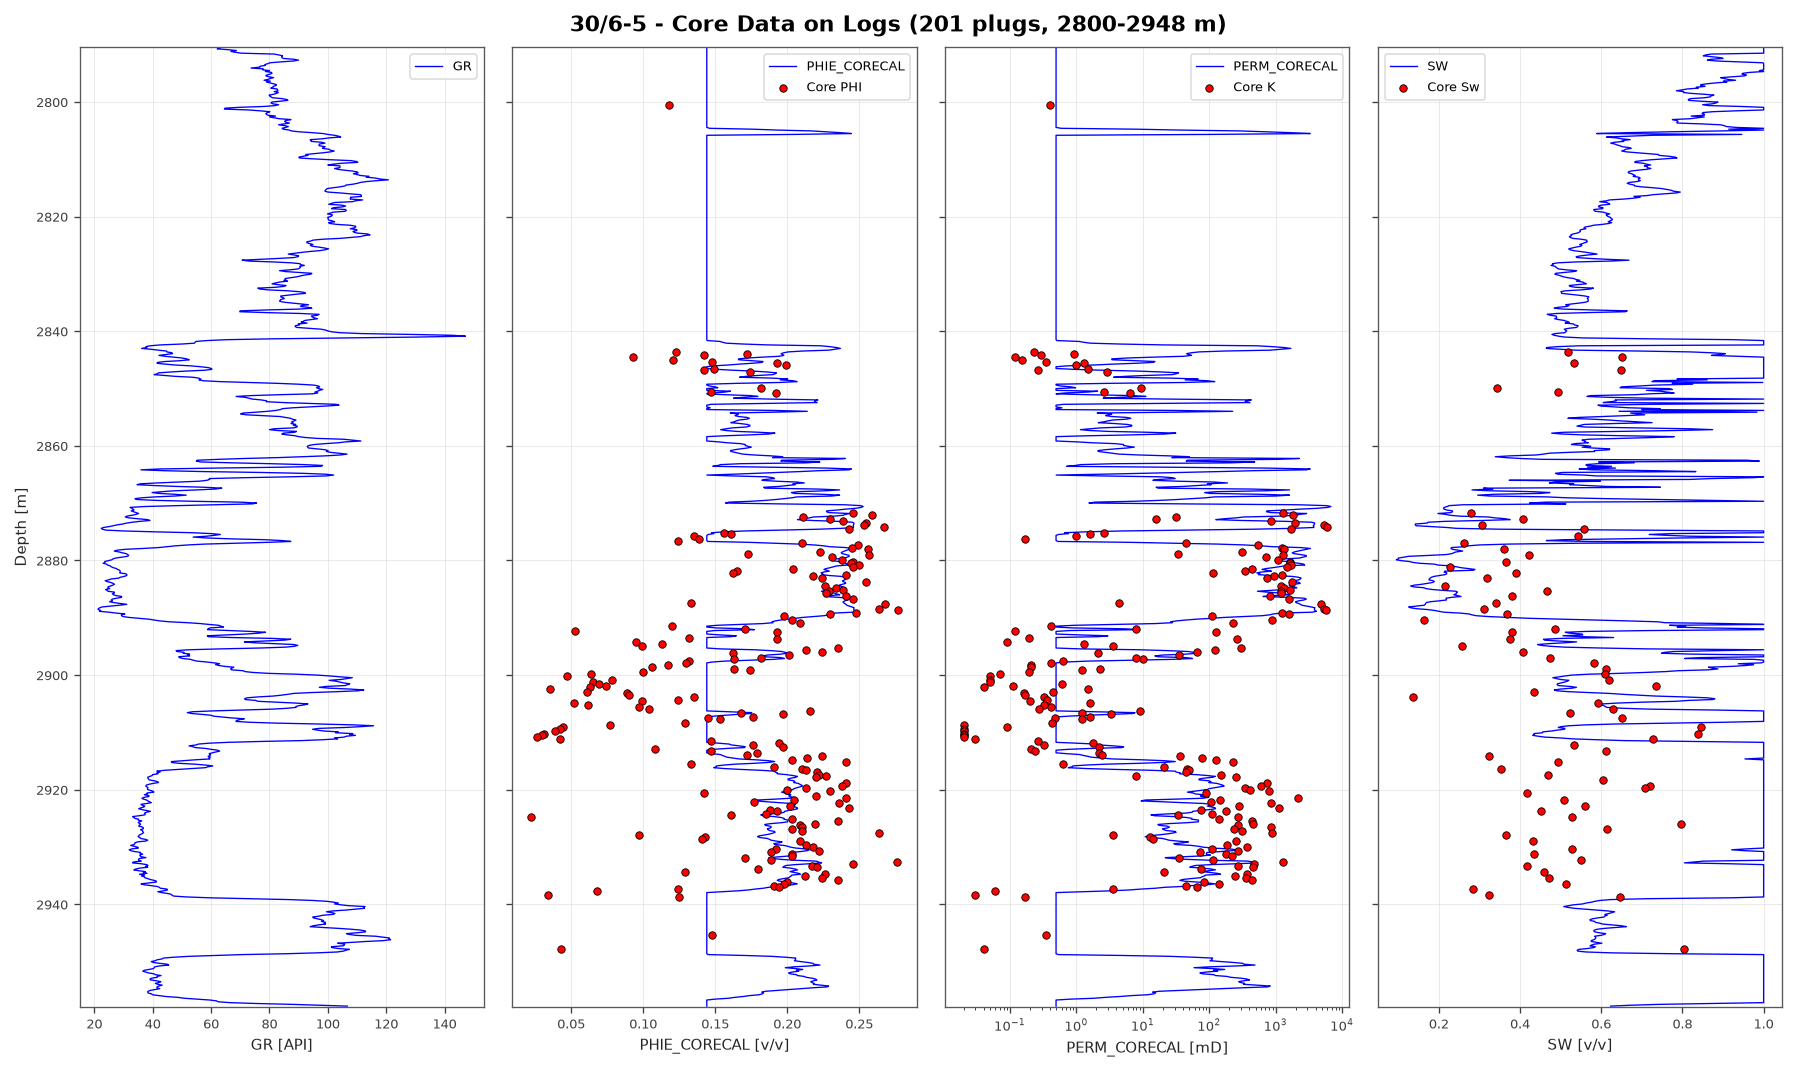

In [61]:
fig, axes = plot_core_on_logs(interp, core, curves=["GR", "PHIE_CORECAL", "PERM_CORECAL", "SW"],
                              depth_range=(core.top - 10, core.bottom + 10), figsize=(15, 9))
plt.show()

**A second cored well: 25/5-1.** Its core calibrates much worse at face value.
A common cause is a depth mismatch: plug depths are driller's depths, logs are
logger's depths, and the two can differ by metres. Shifting the plug depths and
recomputing the fit is a quick test: `find_core_depth_shift` scores the
core-log correlation at each candidate shift (its square is the R² that
`calibrate_porosity` reports), and `shift_core_depths` applies the best one. (In practice each core run is shifted on its
own; a single bulk shift is a first look.)

CoreData(plugs=333, depth=2990.3-3286.3, props=[porosity, perm, GD, Sw]) | cored 2990.3 - 3286.3 m
25/5-1 PHIE vs core, as recorded   n=331  R2=0.185  bias=-0.0381  RMSE=0.0940
25/5-1 PHIE vs core, shifted +3.0 m n=331  R2=0.396  bias=-0.0353  RMSE=0.0808
30/6-5 best shift: +0.0 m


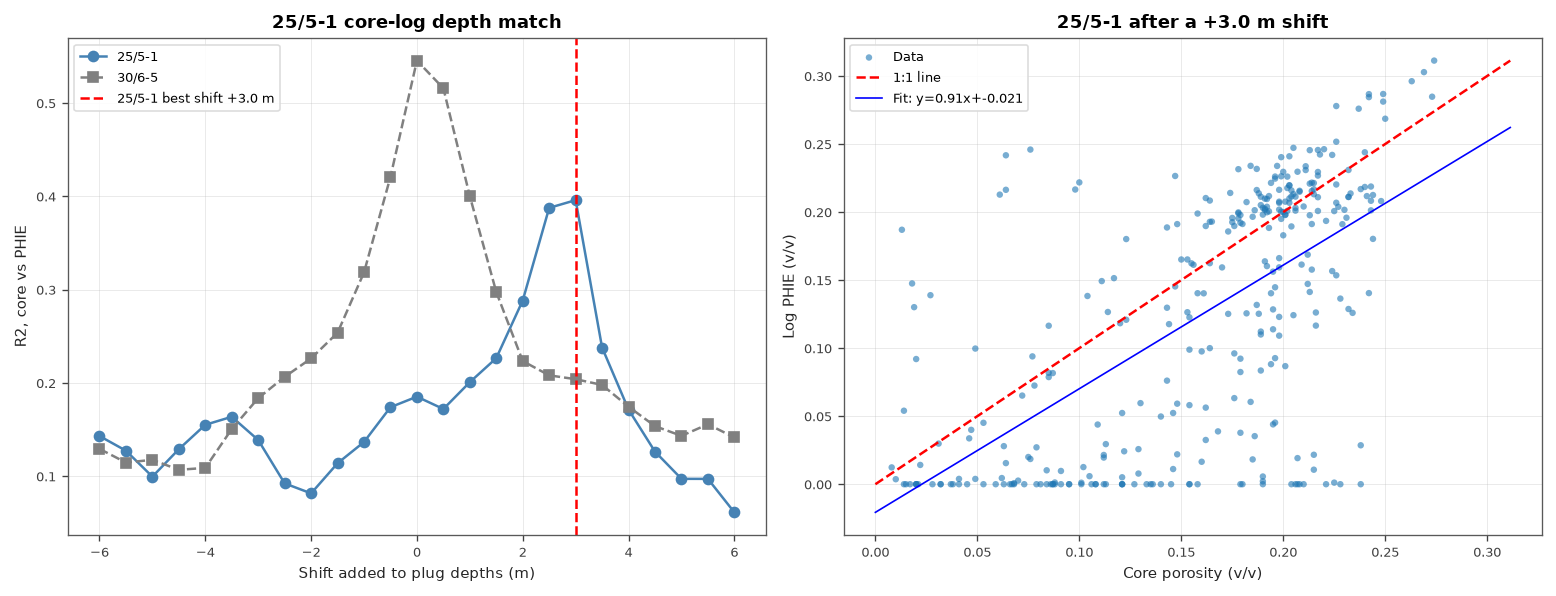

In [62]:
from petrophys.interpretation.core_analysis import find_core_depth_shift, shift_core_depths

second = field["25_5-1"].well                     # interpreted in section 11
core_b = core_data_from_well(second)
print(core_b, f"| cored {core_b.top:.1f} - {core_b.bottom:.1f} m")
show_calibration("25/5-1 PHIE vs core, as recorded", calibrate_porosity(second, core_b, "PHIE"))

shifts = np.arange(-6.0, 6.01, 0.5)               # added to the plug depths (m)
scan_b = find_core_depth_shift(second, core_b, log_curve="PHIE", shifts=shifts)
best = scan_b.shift
best_cal = calibrate_porosity(second, shift_core_depths(core_b, scan_b), log_curve="PHIE")
show_calibration(f"25/5-1 PHIE vs core, shifted {best:+.1f} m", best_cal)

# For comparison: 30/6-5 should need no shift.
scan_a = find_core_depth_shift(interp, core, log_curve="PHIE", shifts=shifts)
print(f"30/6-5 best shift: {scan_a.shift:+.1f} m")

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].plot(scan_b.shifts, scan_b.correlations ** 2, "o-", color="steelblue", label="25/5-1")
axes[0].plot(scan_a.shifts, scan_a.correlations ** 2, "s--", color="gray", label="30/6-5")
axes[0].axvline(best, color="red", ls="--", label=f"25/5-1 best shift {best:+.1f} m")
axes[0].set_xlabel("Shift added to plug depths (m)"); axes[0].set_ylabel("R2, core vs PHIE")
axes[0].set_title("25/5-1 core-log depth match"); axes[0].legend(); axes[0].grid(alpha=0.3)
plot_calibration(best_cal, ax=axes[1], title=f"25/5-1 after a {best:+.1f} m shift")
axes[1].set_xlabel("Core porosity (v/v)"); axes[1].set_ylabel("Log PHIE (v/v)")
plt.tight_layout()
plt.show()

The R² curve peaks well away from zero for 25/5-1 and at zero for 30/6-5. A
clear peak like that is good evidence of a depth offset; apply the shift to the
core (and document it) before any calibration. Even after the shift the match
is weaker than in 30/6-5, so the remaining scatter needs a closer look per core
run.

---
## 15b. Sensitivity analysis: cutoffs and parameters

How much does the answer depend on our choices? Two views:

1. **Cutoffs.** Recompute the net-pay flags on the interpreted curves for a
   grid of VCL and Sw cutoffs, and map Brent net pay as a fraction of the gross
   thickness (net pay / gross). The curves do not change, only the flags, so
   this is fast. `cutoff_sensitivity` (in `petrophys.evaluation`) returns one
   row per cutoff combination.
2. **Parameters.** Re-run `pp.interpret` with Rw, m, n and the cutoffs moved
   to a low and a high value one at a time, and show the swing in Brent net pay
   as a tornado chart. `parameter_sensitivity` (in `petrophys.evaluation`)
   runs any evaluation this way and returns the tornado data.

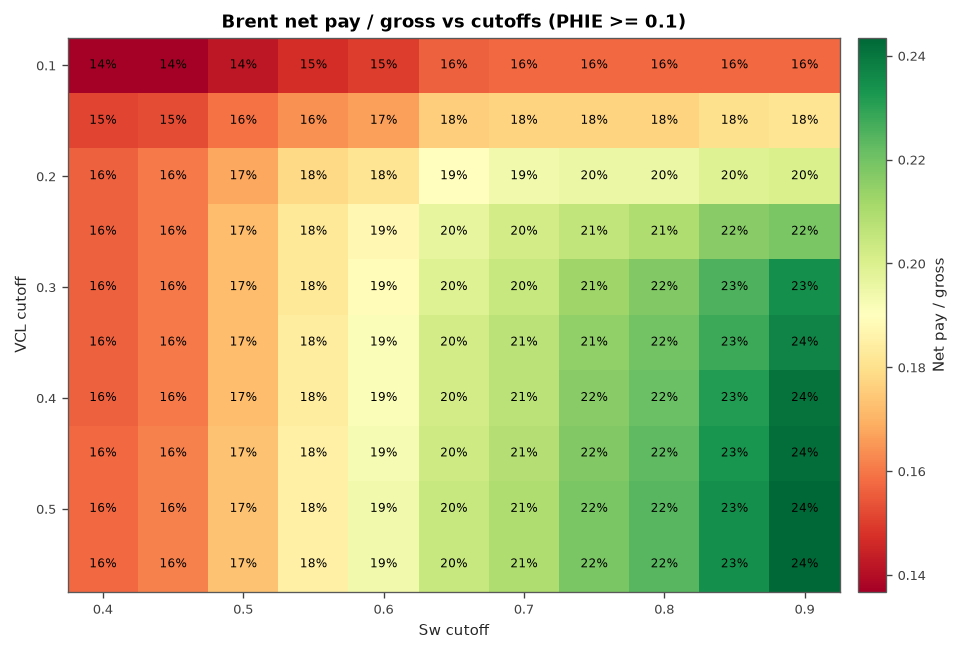

VCL cutoff fixed at 0.4: net pay / gross from 16% to 24% across the Sw cutoffs
Sw cutoff fixed at 0.6: net pay / gross from 15% to 19% across the VCL cutoffs
Sw cutoff fixed at 0.6, VCL cutoff 0.25 and above: net pay / gross from 19% to 19%


In [63]:
from petrophys.evaluation import cutoff_sensitivity
from petrophys.visualization import create_heatmap, create_tornado_plot

vcl_cutoffs = np.round(np.arange(0.10, 0.551, 0.05), 2)
sw_cutoffs = np.round(np.arange(0.40, 0.901, 0.05), 2)
grid = cutoff_sensitivity(interp, vcl_cutoffs=vcl_cutoffs, phie_cutoffs=CUTOFFS["phie_cutoff"],
                          sw_cutoffs=sw_cutoffs, top=BRENT_TOP, bottom=BRENT_BASE)
# One row per cutoff pair; pivot to a VCL x Sw table of net pay / gross.
ntg = grid.pivot(index="vcl_cutoff", columns="sw_cutoff", values="ntg_pay").to_numpy()

# x and y are the cutoff values; each cell is drawn centred on its cutoff.
fig, ax = create_heatmap(ntg, x=sw_cutoffs, y=vcl_cutoffs, cmap="RdYlGn", figsize=(10, 6),
                         xlabel="Sw cutoff", ylabel="VCL cutoff", colorbar_label="Net pay / gross",
                         title=f"Brent net pay / gross vs cutoffs (PHIE >= {CUTOFFS['phie_cutoff']})")
for i, vc in enumerate(vcl_cutoffs):
    for j, sc in enumerate(sw_cutoffs):
        ax.text(sc, vc, f"{ntg[i, j]:.0%}", ha="center", va="center", fontsize=7)
plt.show()
i0 = int(np.argmin(np.abs(vcl_cutoffs - CUTOFFS["vcl_cutoff"])))
j0 = int(np.argmin(np.abs(sw_cutoffs - CUTOFFS["sw_cutoff"])))
print(f"VCL cutoff fixed at {vcl_cutoffs[i0]}: net pay / gross from {ntg[i0].min():.0%} to "
      f"{ntg[i0].max():.0%} across the Sw cutoffs")
print(f"Sw cutoff fixed at {sw_cutoffs[j0]}: net pay / gross from {ntg[:, j0].min():.0%} to "
      f"{ntg[:, j0].max():.0%} across the VCL cutoffs")
print(f"Sw cutoff fixed at {sw_cutoffs[j0]}, VCL cutoff 0.25 and above: net pay / gross from "
      f"{ntg[vcl_cutoffs >= 0.25, j0].min():.0%} to {ntg[vcl_cutoffs >= 0.25, j0].max():.0%}")

Read the heatmap along its axes, with the printed ranges: the Sw cutoff moves
net pay / gross more than the VCL cutoff, and from a VCL cutoff of 0.25 upwards
the clay cutoff makes no difference at all, because most of the Brent pay is
clean sand that passes any reasonable clay cutoff.

Now the parameters. `brent_pay` below re-interprets the well with some
settings changed and returns the Brent net pay; `parameter_sensitivity` calls
it once for the base case and twice per case. Each bar is two extra
interpretations of the whole well.

                              case  low  high  swing
                       m 1.8 / 2.2 24.1  20.1    4.0
             Sw cutoff 0.50 / 0.70 20.0  23.6    3.7
Rw 0.05 / 0.09 ohm.m (at 230 degF) 23.6  20.7    2.9
                       n 1.8 / 2.2 22.7  21.6    1.1
           PHIE cutoff 0.12 / 0.08 22.1  22.2    0.1

Base case: 22.2 m of Brent net pay


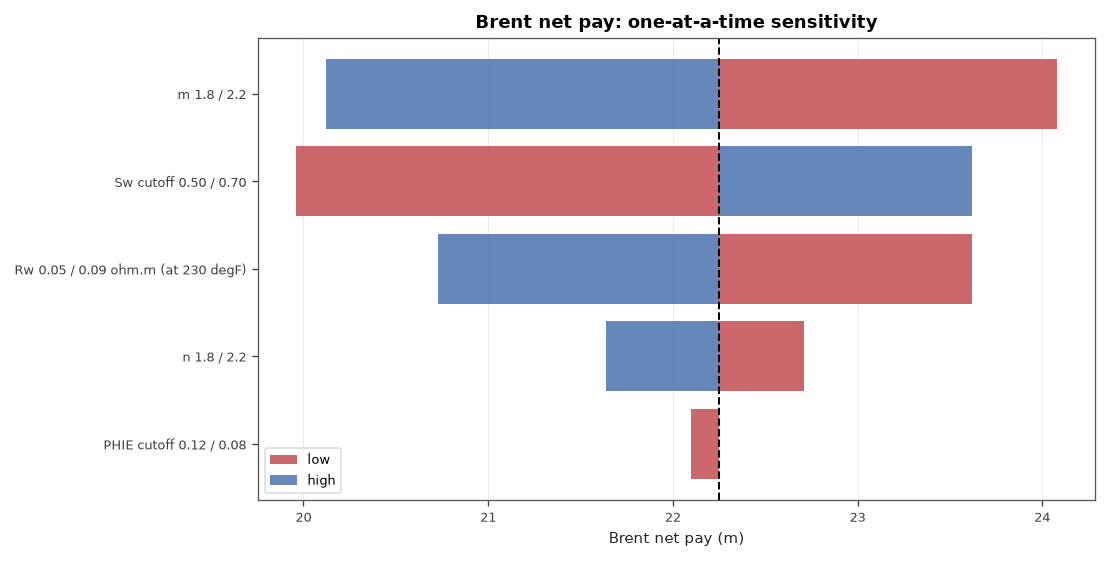

In [64]:
from petrophys.evaluation import parameter_sensitivity


def brent_pay(**changes):
    """Brent net pay (m) from a full re-interpretation with some settings changed."""
    settings = dict(rw=RW, rw_meas_temp_f=RW_TEMP_F, lithology_domain="clastic",
                    matrix_type="sandstone", a=A, m=M, n=N, **CUTOFFS)
    settings.update(changes)
    run = pp.interpret(geo_raw, **settings)
    return run.summary(top=BRENT_TOP, bottom=BRENT_BASE)["net_thickness"]["net_pay"]


cases = {
    "Rw 0.05 / 0.09 ohm.m (at 230 degF)": ({"rw": 0.05}, {"rw": 0.09}),
    "m 1.8 / 2.2": ({"m": 1.8}, {"m": 2.2}),
    "n 1.8 / 2.2": ({"n": 1.8}, {"n": 2.2}),
    "Sw cutoff 0.50 / 0.70": ({"sw_cutoff": 0.50}, {"sw_cutoff": 0.70}),
    "PHIE cutoff 0.12 / 0.08": ({"phie_cutoff": 0.12}, {"phie_cutoff": 0.08}),
}
tornado = parameter_sensitivity(brent_pay, cases)    # sorted by swing, widest first
base_pay = tornado.attrs["base"]["value"]
print(tornado[["case", "low", "high", "swing"]].round(1).to_string(index=False))
print(f"\nBase case: {base_pay:.1f} m of Brent net pay")

fig, ax = create_tornado_plot(tornado["case"].tolist(), tornado["low"], tornado["high"],
                              base=base_pay, xlabel="Brent net pay (m)",
                              title="Brent net pay: one-at-a-time sensitivity")
plt.show()

`low` is the net pay at the first setting in the label and `high` at the
second; `swing` is the gap between them, and the rows are ranked by it. The
ranking is the useful output, more than the absolute numbers: here the saturation inputs (m and Rw) and the Sw cutoff
dominate, while n and the porosity cutoff barely matter. It tells you where to
spend effort (a water sample, special core analysis) before quoting net pay.

---
## 16. Visualization gallery

`petrophys.visualization` provides the plots used above and several more:

- `LogPlot` / `create_log_plot`: a custom multi-track plot, built track by track;
- `create_triple_combo`: the standard GR / resistivity / density-neutron display;
- `pp.plot(..., template=...)`: the template-driven log viewer, including the
  full interpretation display;
- `create_crossplot` / `CrossPlot`: general crossplots with overlays;
- `create_pickett_plot` / `PickettPlot`: log Rt vs log PHIE with Sw lines;
- `plot_zone_flags` and `add_zone_shading`: flag columns and formation shading.

All of them take a `Well`; for a workflow result pass `result.well`.

### 16a. `LogPlot`: a custom multi-track plot

Create the figure, add curves and fills track by track, then set the depth
window and title.

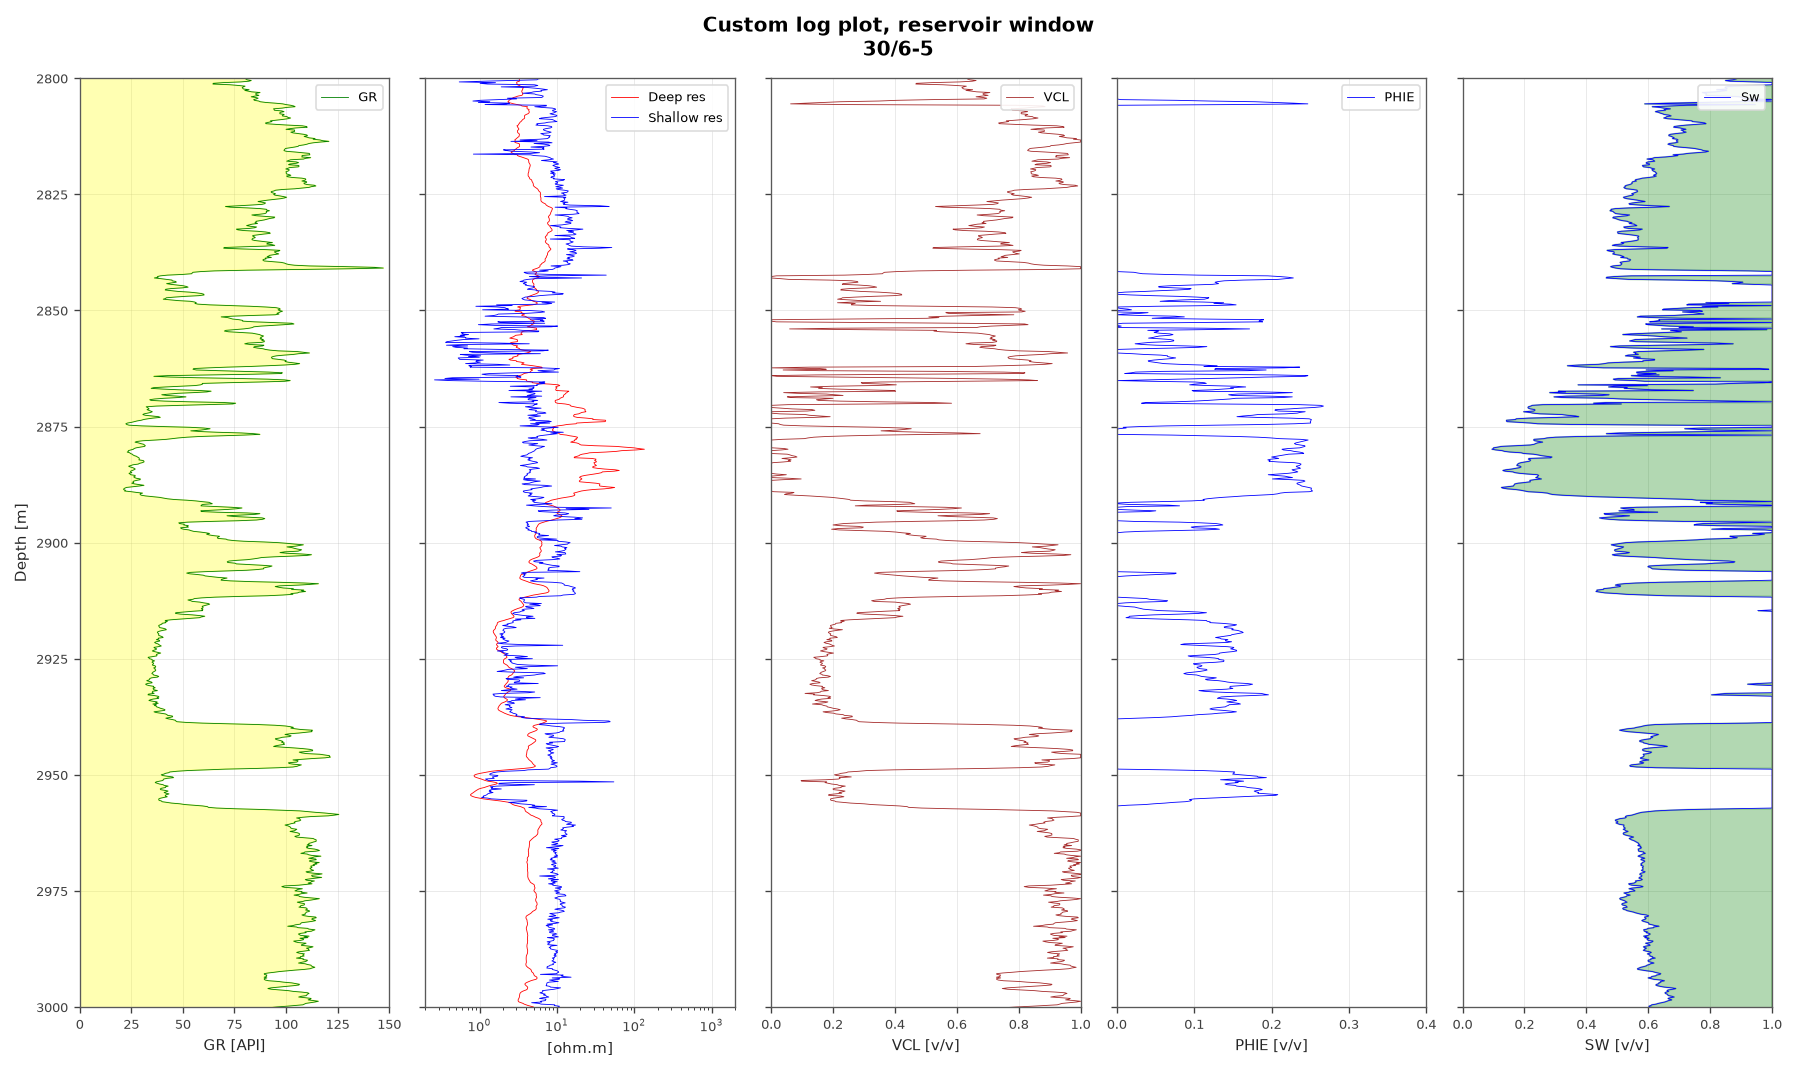

In [65]:
from petrophys.visualization import LogPlot, create_log_plot

log_plot = LogPlot(interp, figsize=(15, 9))
log_plot.create_figure(n_tracks=5)
log_plot.add_curve(0, "GR", color="green", xlim=(0, 150))
log_plot.add_fill(0, "GR", fill_value=0, color="yellow", alpha=0.3, where="right")
log_plot.add_curve(1, "RDEP", color="red", log_scale=True, xlim=(0.2, 2000), label="Deep res")
log_plot.add_curve(1, "RSHA", color="blue", log_scale=True, label="Shallow res")
log_plot.add_curve(2, "VCL", color="brown", xlim=(0, 1), label="VCL")       # own track, 0-1 scale
log_plot.add_curve(3, "PHIE", color="blue", xlim=(0, 0.4), label="PHIE")
log_plot.add_curve(4, "SW", color="blue", xlim=(0, 1), label="Sw")
log_plot.add_fill(4, "SW", fill_value=1, color="green", alpha=0.3, where="left")
log_plot.set_depth_range(top=WINDOW[0], bottom=WINDOW[1])
log_plot.add_title("Custom log plot, reservoir window")   # add_title appends the well name
log_plot.show()

`create_log_plot` does the same from a list of curve specifications. The
`PERM_CC` track shows the workflow's core-calibrated permeability; remember
from section 10 that it is extrapolated outside the cored Brent (2800-2948 m),
so read it only there.

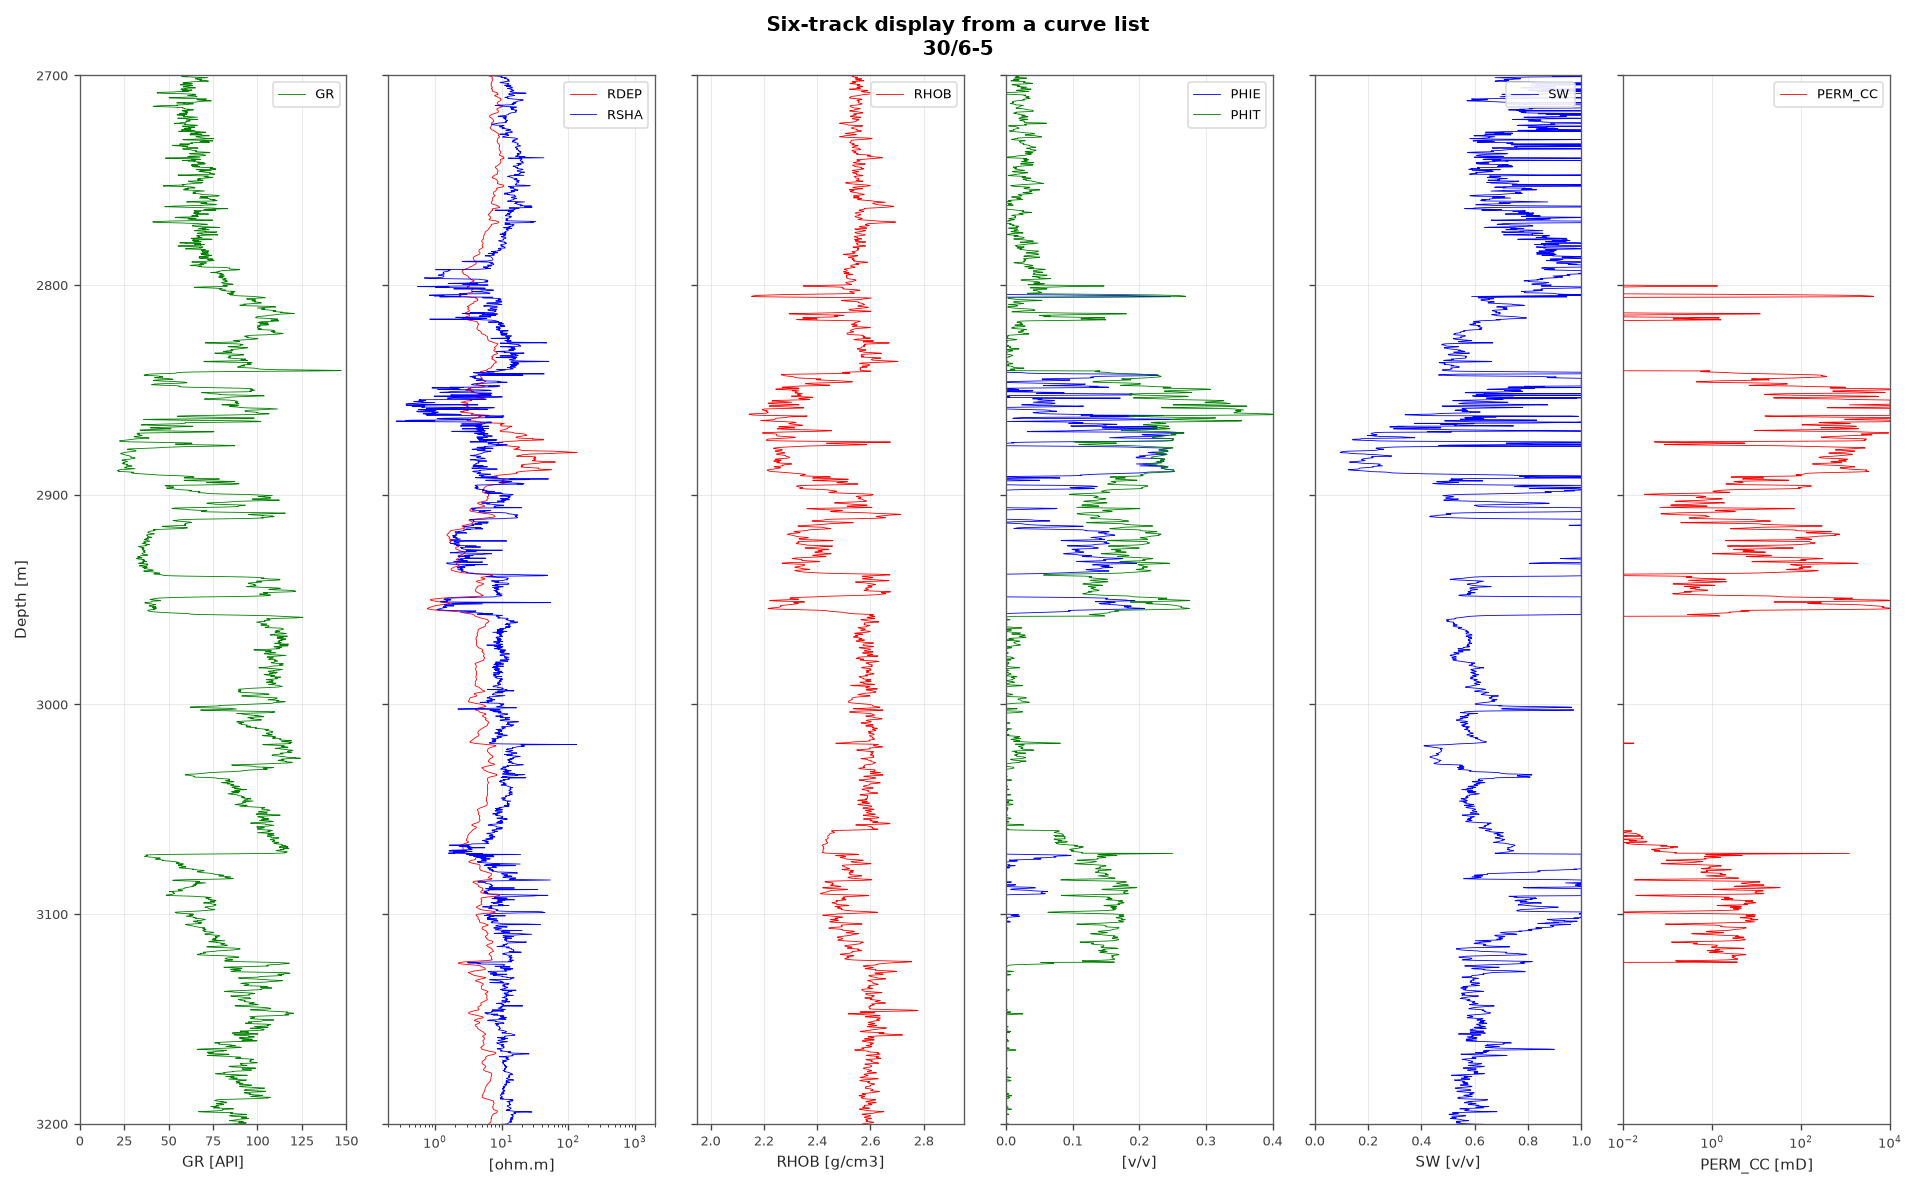

In [66]:
plot = create_log_plot(
    interp,
    curves=[
        {"track": 0, "name": "GR", "color": "green", "xlim": (0, 150)},
        {"track": 1, "name": "RDEP", "color": "red", "log_scale": True, "xlim": (0.2, 2000)},
        {"track": 1, "name": "RSHA", "color": "blue", "log_scale": True},
        {"track": 2, "name": "RHOB", "color": "red", "xlim": (1.95, 2.95)},
        {"track": 3, "name": "PHIE", "color": "blue", "xlim": (0, 0.4)},
        {"track": 3, "name": "PHIT", "color": "green"},
        {"track": 4, "name": "SW", "color": "blue", "xlim": (0, 1)},
        {"track": 5, "name": "PERM_CC", "color": "red", "log_scale": True, "xlim": (0.01, 10000)},
    ],
    depth_range=(2700.0, 3200.0),
    title="Six-track display from a curve list",
    figsize=(16, 10),
)
plot.show()

### 16b. Triple combo

The first plot most petrophysicists look at. `create_triple_combo` returns a
log viewer (show it, then close it); give it a `depth_range` to zoom.

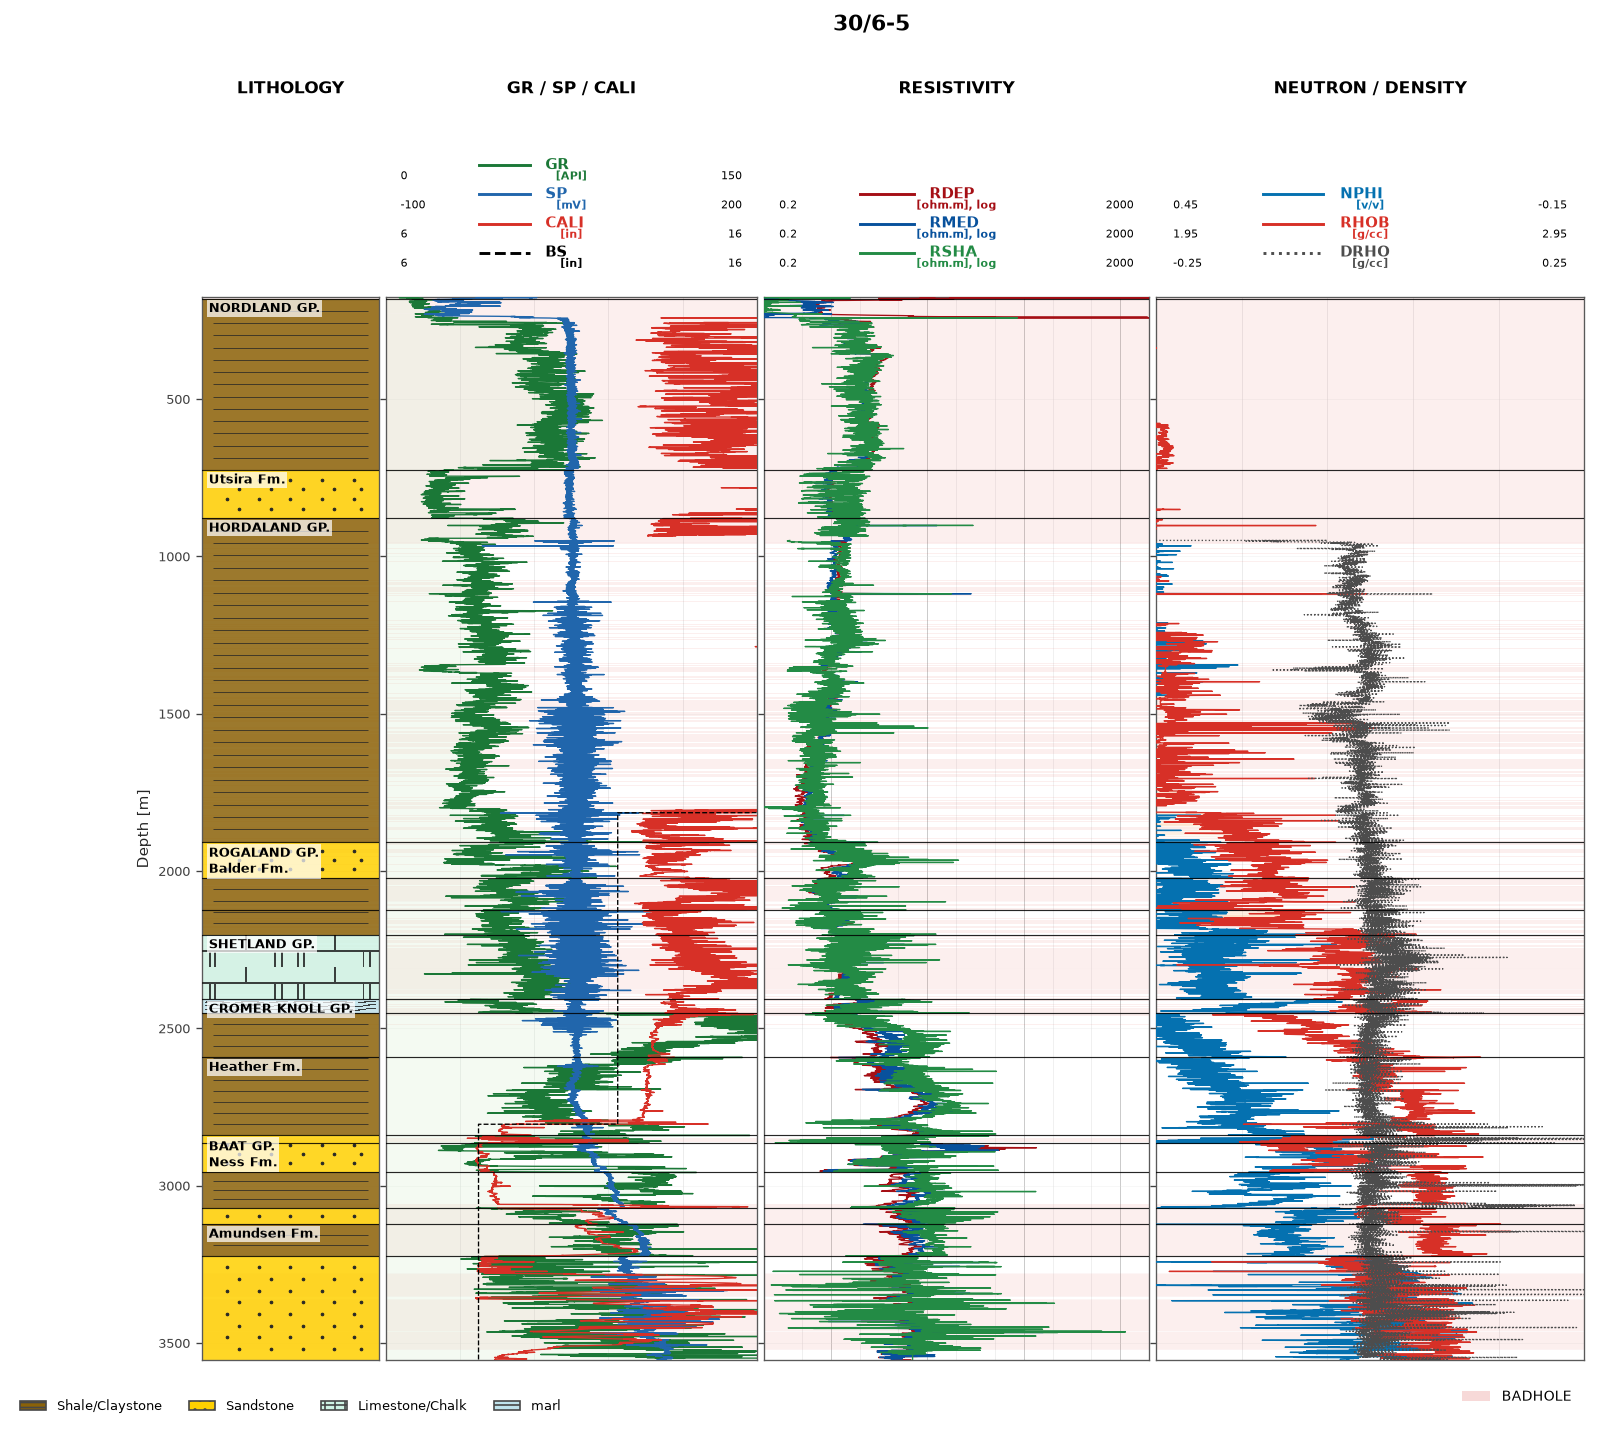

In [67]:
from petrophys.visualization import create_triple_combo

triple = create_triple_combo(interp, figsize=(12, 12))
triple.show()
triple.close()

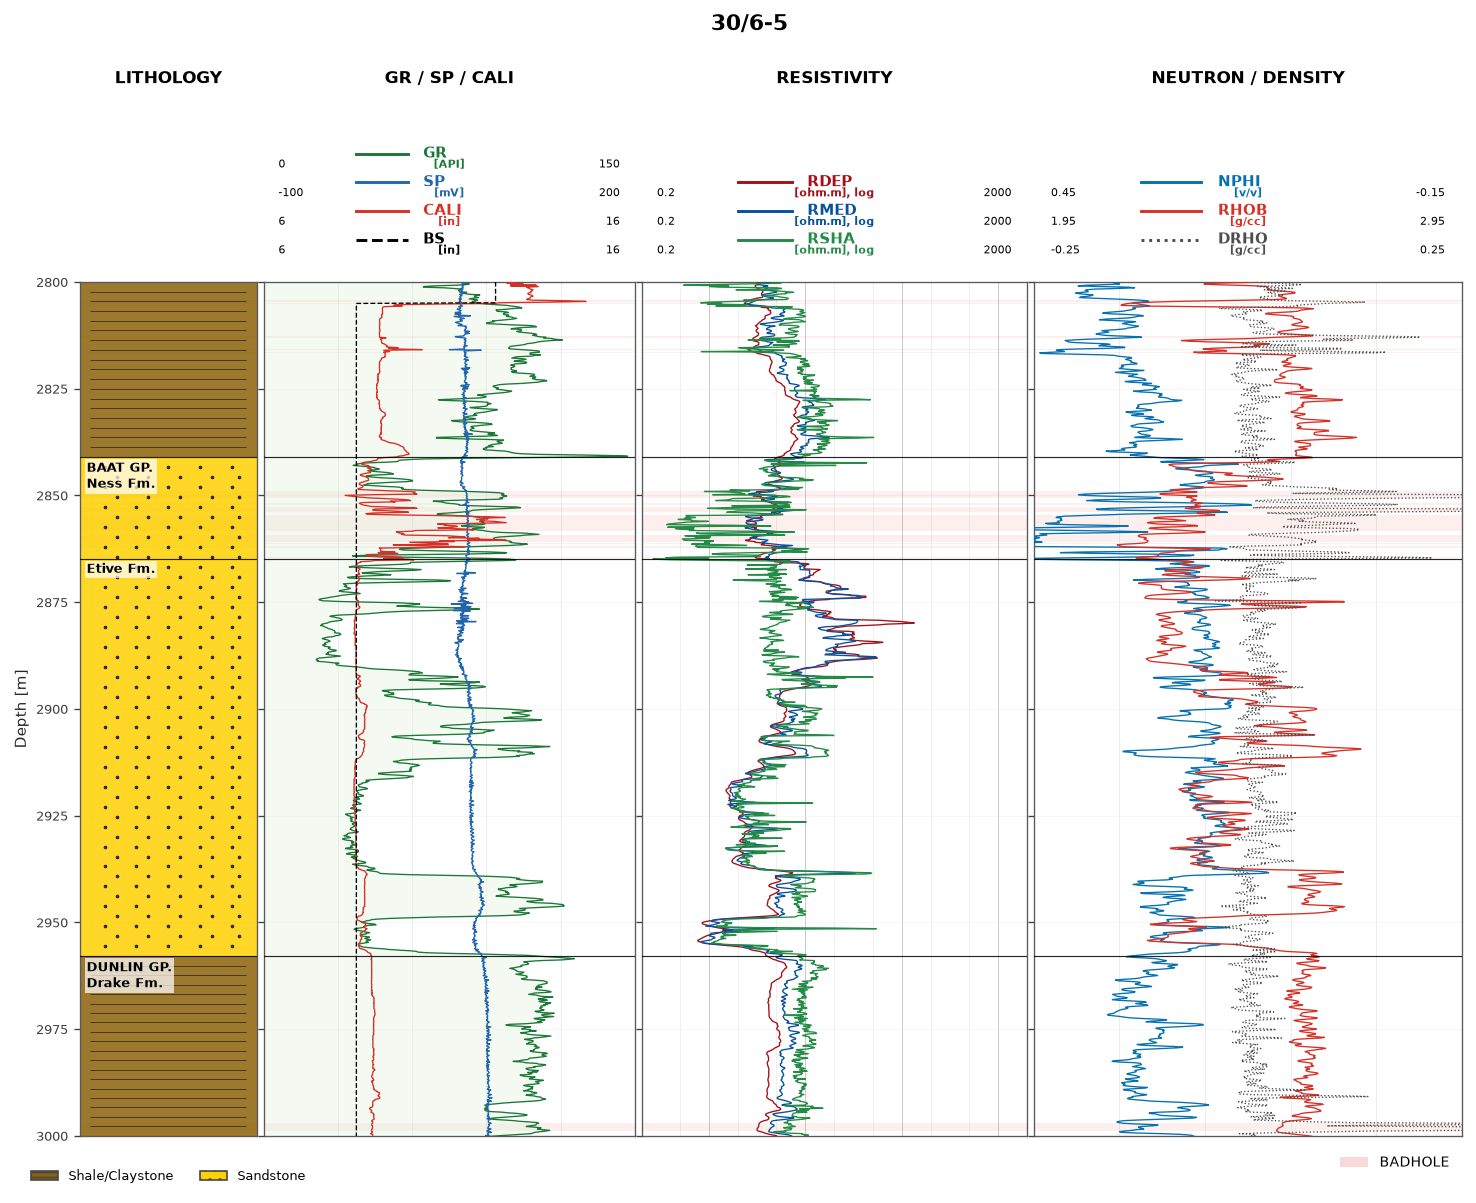

In [68]:
triple_zoom = create_triple_combo(interp, depth_range=WINDOW, figsize=(12, 10))
triple_zoom.show()
triple_zoom.close()

### 16c. The full interpretation plot

`pp.plot(result, template="petrophysics")` is the deliverable display: lithology,
GR/VCL, resistivity, density-neutron-sonic, porosity, saturation, permeability
and flag tracks, with the attached formation tops marked. Its permeability
track includes `PERM_CC`, which is only meaningful inside the cored Brent
(section 10).

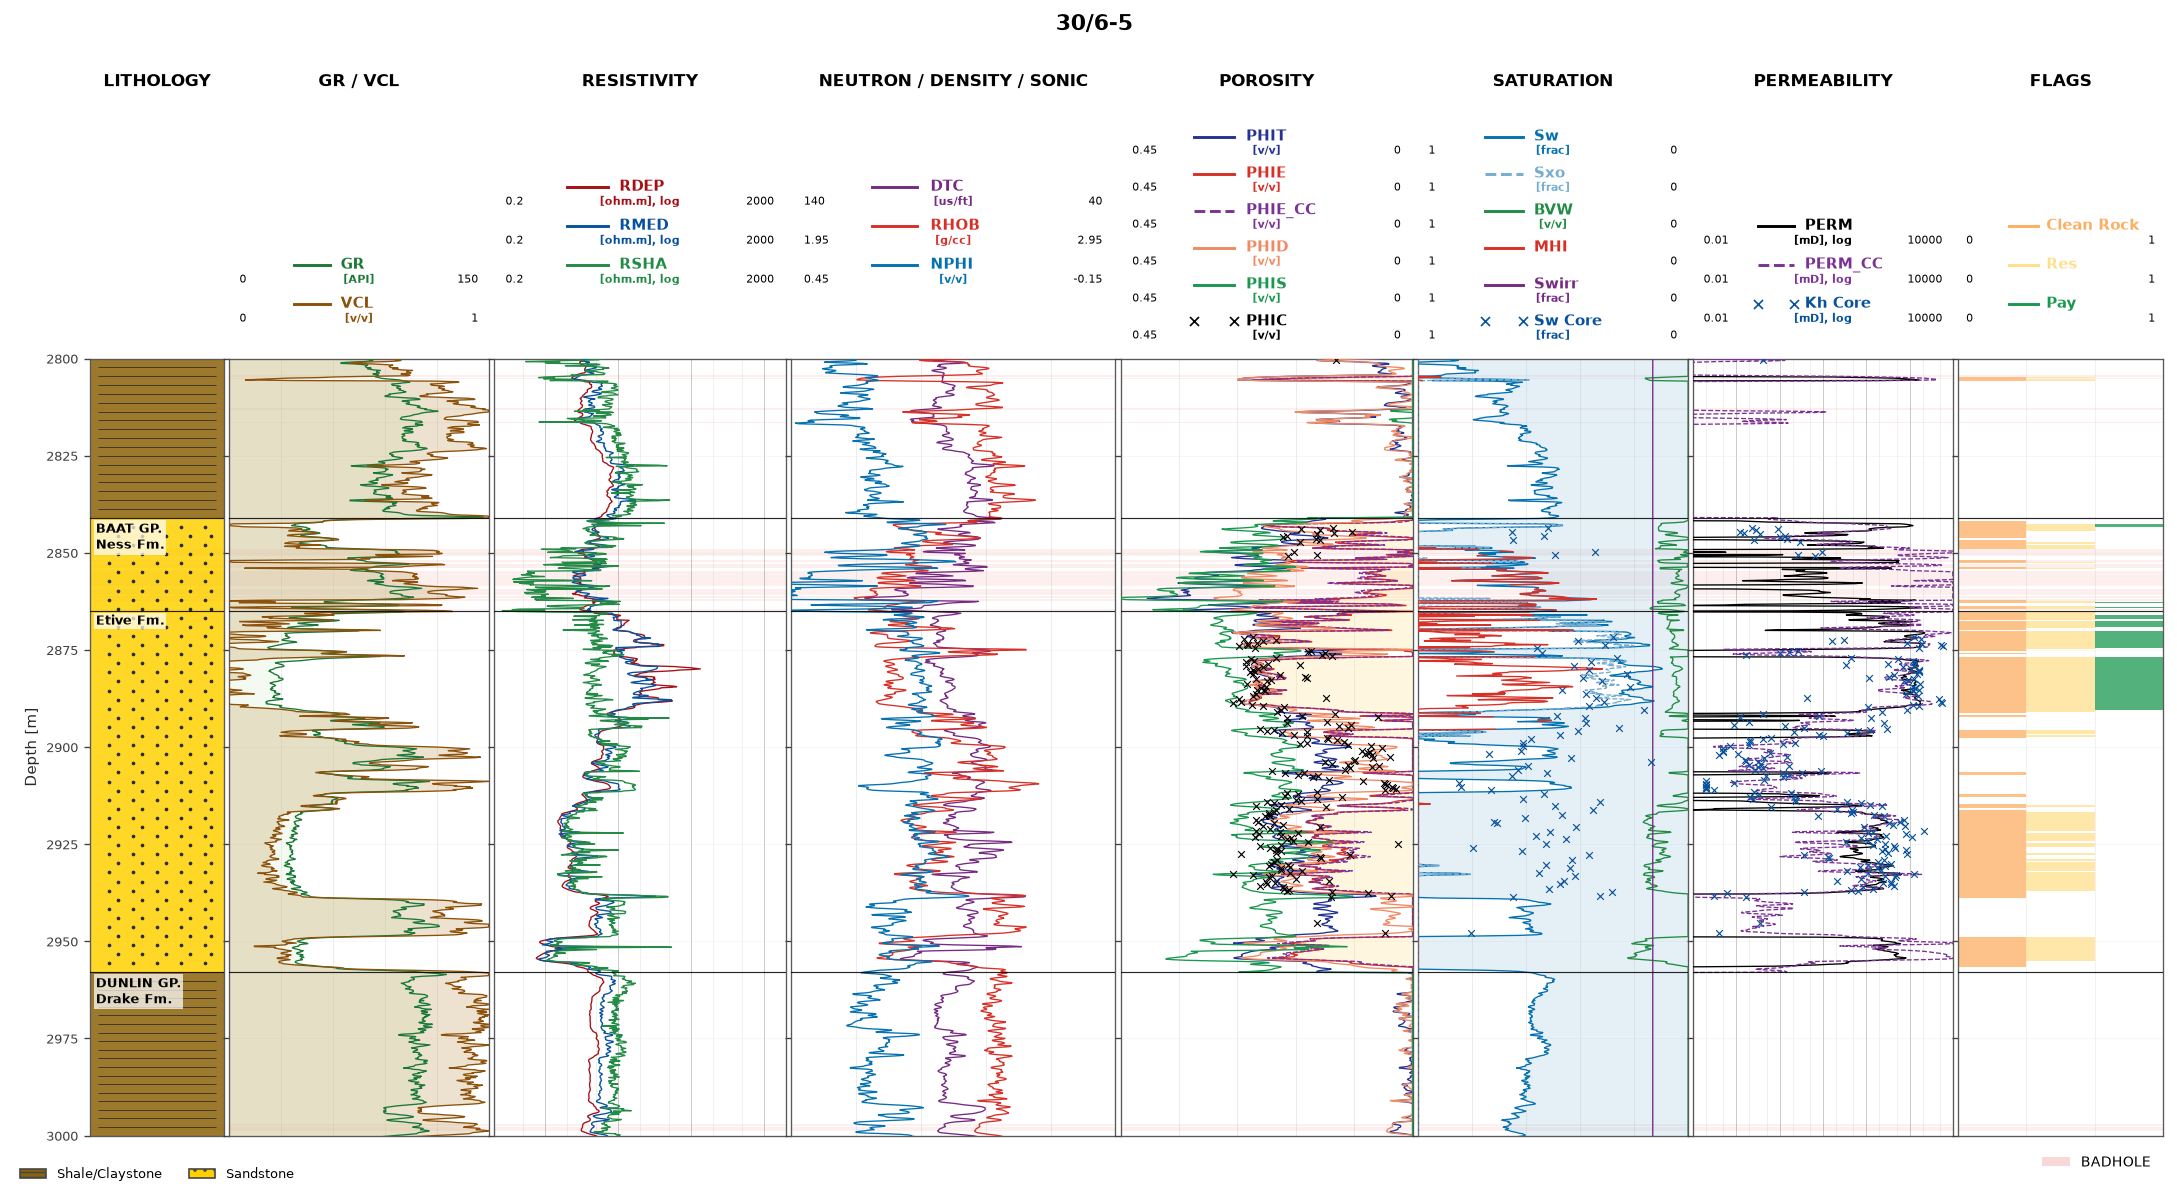

Tracks: ['DEPTH', 'LITHOLOGY', 'GR / VCL', 'RESISTIVITY', 'NEUTRON / DENSITY / SONIC', 'POROSITY', 'SATURATION', 'PERMEABILITY', 'FLAGS']


In [69]:
full = pp.plot(result, template="petrophysics", top=WINDOW[0], bottom=WINDOW[1], figsize=(18, 10))
full.show()
full.close()
print("Tracks:", [track.display_name for track in full.template.tracks])

### 16d. Crossplots

A density-neutron crossplot separates lithologies: points fall along lines
from the matrix points (sandstone, limestone, dolomite) towards the fluid
point. `create_crossplot` takes any x, y and colour curves; `add_matrix_points`
and `add_line` overlay reference points and lines.

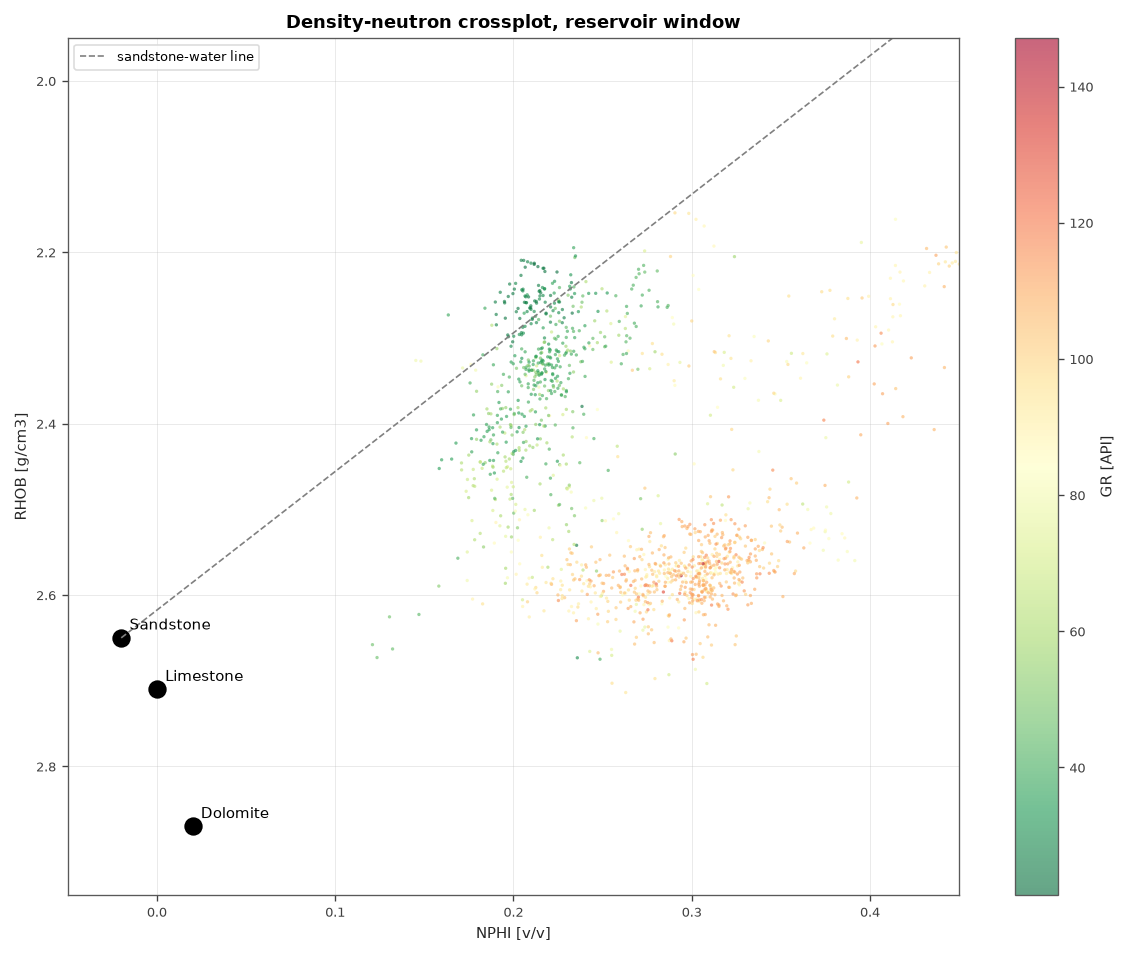

In [70]:
from petrophys.visualization import create_crossplot

dn = create_crossplot(
    interp, x_curve="NPHI", y_curve="RHOB", color_curve="GR", depth_range=WINDOW,
    title="Density-neutron crossplot, reservoir window",
    xlim=(-0.05, 0.45), ylim=(2.95, 1.95), cmap="RdYlGn_r", marker_size=4, alpha=0.6,
)
dn.add_matrix_points({"Sandstone": (-0.02, 2.65), "Limestone": (0.00, 2.71), "Dolomite": (0.02, 2.87)})
dn.add_line(x=[-0.02, 1.0], y=[2.65, 1.0], color="gray", linestyle="--", linewidth=1,
            label="sandstone-water line")
dn.show()

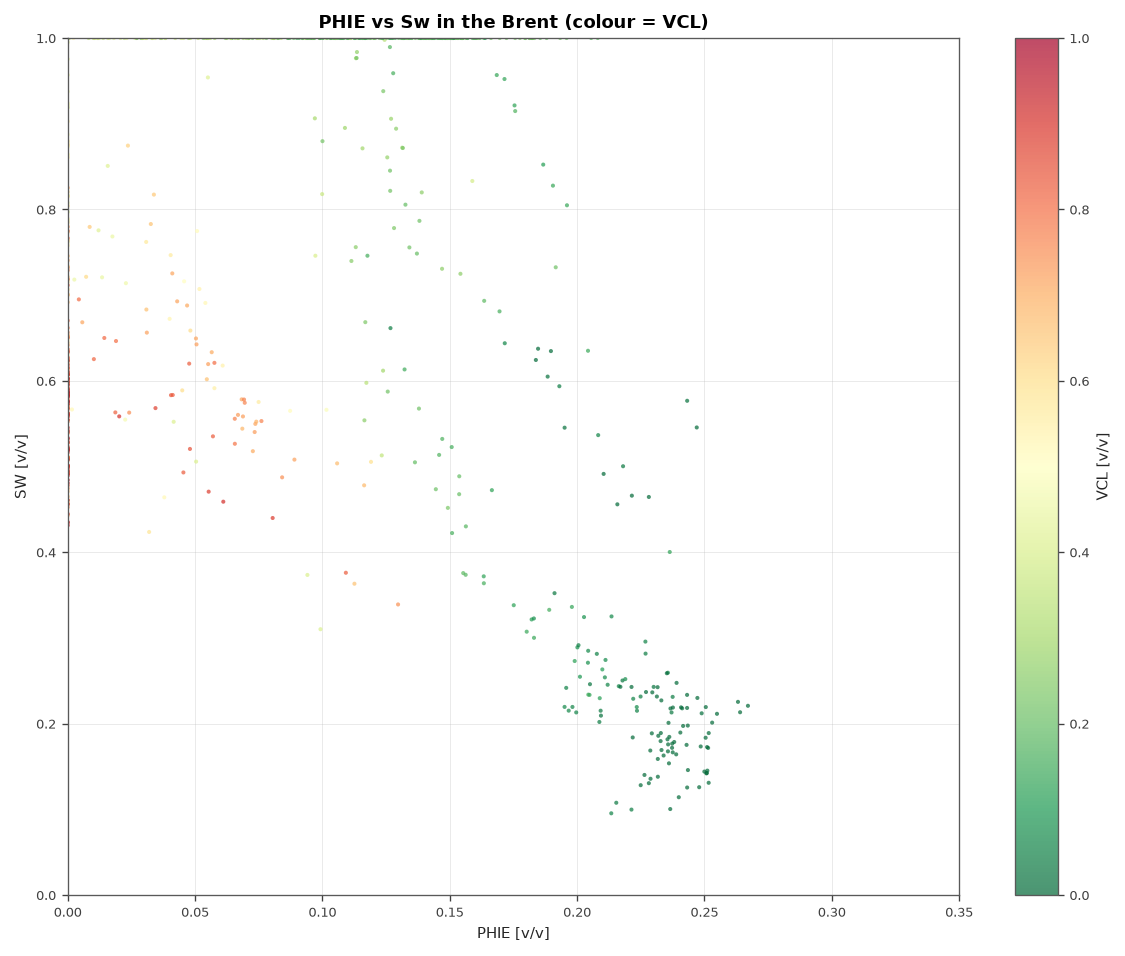

In [71]:
sw_x = create_crossplot(
    interp, x_curve="PHIE", y_curve="SW", color_curve="VCL", depth_range=(BRENT_TOP, BRENT_BASE),
    title="PHIE vs Sw in the Brent (colour = VCL)", xlim=(0, 0.35), ylim=(0, 1),
    cmap="RdYlGn_r", marker_size=6,
)
sw_x.show()

### 16e. Pickett plot

On log-log axes of Rt against PHIE, Archie's equation becomes straight lines of
constant Sw with slope -m. Water-bearing clean rock should plot along the
Sw = 100 % line, which checks Rw and m together. We use the water-bearing
Statfjord Fm. sand (3223-3556 m) and the Rw corrected to its temperature, then
fit a trend through its clean, porous, wet points.

Rw at Statfjord temperature: 0.0646 ohm.m
Trend through 343 clean wet points: m = 1.52 (assumed m = 2.0)


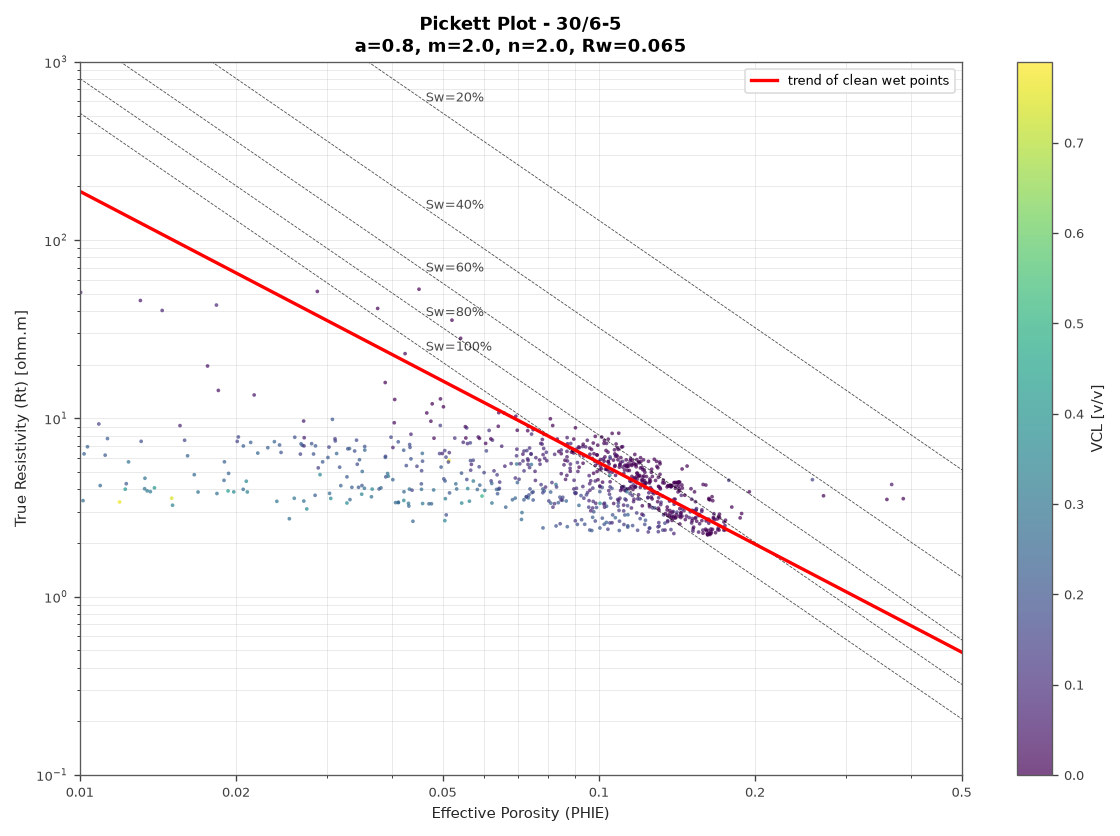

In [72]:
from petrophys.visualization import create_pickett_plot

STATFJORD = (3223.0, 3556.0)
sd = interp.depth
in_statfjord = (sd >= STATFJORD[0]) & (sd <= STATFJORD[1])
rw_statfjord = float(np.nanmedian(interp["RW"].data[in_statfjord]))
pickett = create_pickett_plot(interp, rw=rw_statfjord, phie_curve="PHIE", rt_curve="RDEP",
                              color_curve="VCL", depth_range=STATFJORD, a=A, m=M, n=N, figsize=(10, 7))

p_phie, p_rt = interp["PHIE"].data, interp["RDEP"].data
wet_clean = (in_statfjord & (interp["VCL"].data < 0.15) & (interp["SW"].data > 0.8)
             & (p_phie > 0.10) & np.isfinite(p_rt))
slope_m, intercept = pickett.add_trend_line(p_phie[wet_clean], p_rt[wet_clean], color="red",
                                            label="trend of clean wet points")
print(f"Rw at Statfjord temperature: {rw_statfjord:.4f} ohm.m")
print(f"Trend through {wet_clean.sum()} clean wet points: m = {slope_m:.2f} (assumed m = {M})")
pickett.show()

Compare the fitted slope with the assumed m and check where the points sit
relative to the Sw = 100 % line. A least-squares trend through points that span
a narrow porosity range is poorly constrained and usually flatter than the true
m (noise in porosity pulls the slope towards zero), so treat it as a check, not
a measurement.

### 16f. Zone flags and formation shading

`plot_zone_flags` draws the net-flag curves as coloured columns, and
`add_zone_shading` paints named depth spans onto any matplotlib axis. The spans
here come straight from the formation-rank tops table.

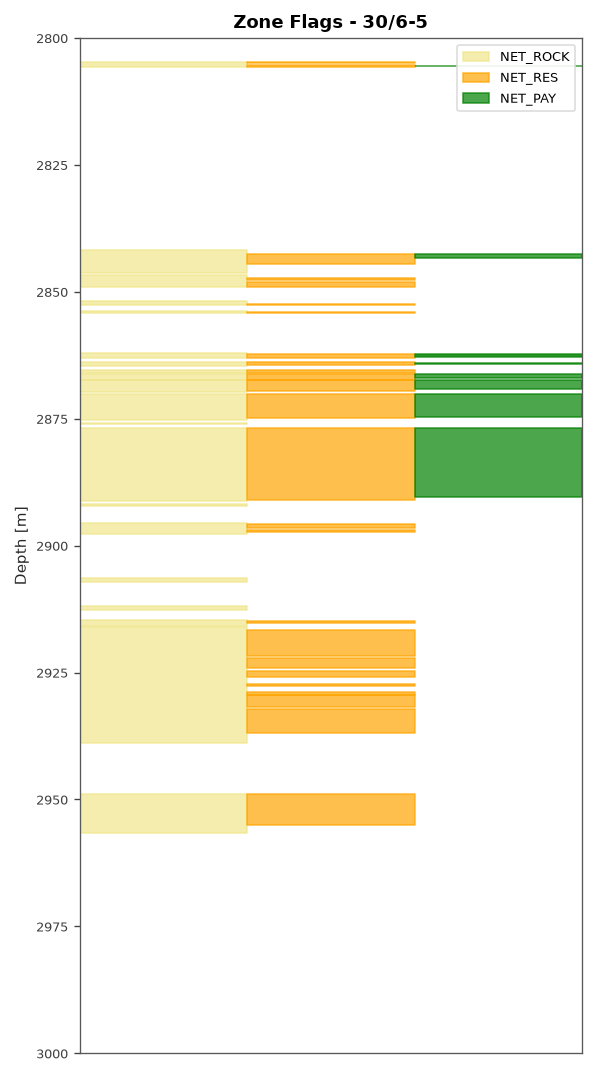

In [73]:
from petrophys.visualization import plot_zone_flags, add_zone_shading

fig, ax = plot_zone_flags(interp, flag_curves=["NET_ROCK", "NET_RES", "NET_PAY"],
                          colors={"NET_ROCK": "khaki", "NET_RES": "orange", "NET_PAY": "green"},
                          depth_range=WINDOW, figsize=(5, 9))
plt.show()

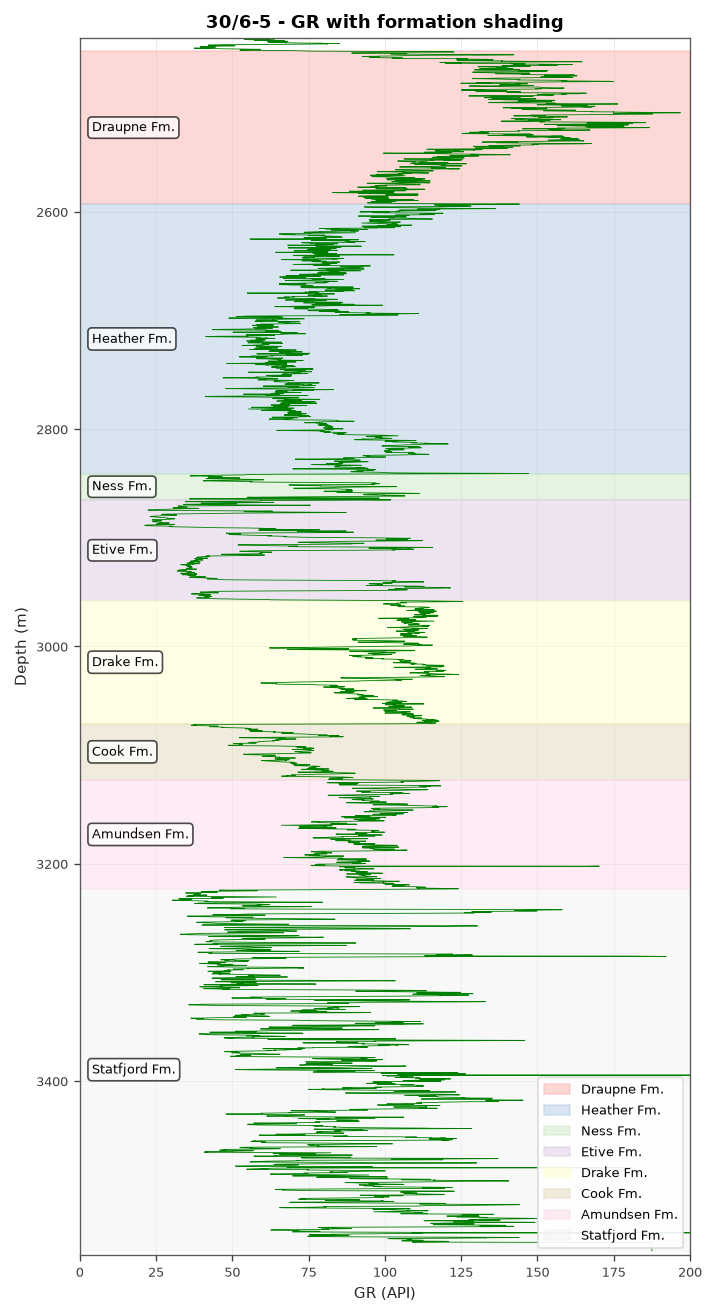

In [74]:
SHADE = ["Draupne Fm.", "Heather Fm.", "Ness Fm.", "Etive Fm.", "Drake Fm.", "Cook Fm.",
         "Amundsen Fm.", "Statfjord Fm."]
colors = plt.cm.Pastel1(np.linspace(0, 1, len(SHADE)))
zones_to_shade = [
    {"name": row.formation_name, "top": row.top_depth, "bottom": row.bottom_depth, "color": color}
    for row, color in zip(fm_table[fm_table["formation_name"].isin(SHADE)].itertuples(), colors)
]

fig, ax = plt.subplots(figsize=(6, 11))
ax.plot(interp["GR"].data, interp.depth, color="green", lw=0.5)
ax.set_xlim(0, 200); ax.set_ylim(3560, 2440)
ax.set_xlabel("GR (API)"); ax.set_ylabel("Depth (m)"); ax.grid(alpha=0.3)
add_zone_shading(ax, zones_to_shade, alpha=0.5)
ax.legend(fontsize=8, loc="lower right")
ax.set_title(f"{interp.name} - GR with formation shading")
plt.tight_layout()
plt.show()

---
## Pitfalls

- **Rw needs its temperature.** Pass `rw_meas_temp_f` with every `rw`; without
  it the value is taken at the median formation temperature and saturation
  shifts strongly.
- **Whole-well totals are not reservoir numbers.** Shallow unconsolidated
  sediment can pass net-pay cutoffs, the more so because one Rw serves the whole
  well while shallow formation water is usually fresher. Report a reservoir
  window or `formation_summary(rank="formation")` rows you can justify
  geologically, or give shallow zones their own Rw (zoned header parameters,
  lesson 10).
- **Mixed-rank tops overlap.** Choose one rank before adding rows or labelling
  samples; never sum a group and its formations.
- **Gamma-ray endpoints are a choice,** and `vcl_from_gr` (and so `VclModule`)
  widens them to at most 20 API clean and at least 100 API shale.
- **One bad clay indicator spoils a minimum.** `VclModule` keeps the lowest of
  the GR, SP and neutron-density estimates; check each one in known shales and
  sands first (section 4), and drop an SP without a clean shale-sand contrast.
  The workflow takes the minimum of GR and neutron-density only; it adds the SP
  estimate only when you set both SP baselines (`sp_min`, `sp_max`) for an SP
  without baseline drift.
- **Check shale-parameter estimates.** `calculate_rcl` returns the median over
  whatever samples your mask or VCL threshold selects; print how many samples
  that is, and pass an explicit shale mask when the threshold selects few.
- **Calibrate against core, but check core depths first.** A metre-scale core
  depth offset (25/5-1) degrades every calibration statistic;
  `find_core_depth_shift` finds it.
- **Empirical permeability can be biased by an order of magnitude.** Prefer a
  core-calibrated transform where core exists, and do not apply it far outside
  the porosity range of the plugs. The workflow's `PERM_CC` applies its
  core fit at every depth of the well (section 10 counts the samples at its
  10,000 mD clip); read it only inside the cored interval.
- **Shaly-sand models can have no solution in shale.** Where the shale term
  exceeds the measured conductivity, North Sea and Nigeria-Schlumberger return
  NaN (the model does not apply there). Average Sw over reservoir-quality rock,
  not over a whole interval.
- **Core saturation units.** `SWC`/`SOC` in 30/6-5 are percent labelled `frac`;
  `standardize_curves` (and so `pp.interpret`) infers the percent scale,
  converts them to v/v and warns. Use `standardize_core_saturation` with an
  explicit `source_unit` to declare the unit yourself.
- **`run_dynamic_workflow` changes its input well;** `pp.interpret` does not.

## Recap

- `pp.read` loads a well (with optional tops and lithology), `pp.interpret` runs
  the full interpretation on a copy, and `pp.plot` draws it; `result.summary`,
  `result.formation_summary` and `result.to_dataframe` report it.
- The same chain is available step by step: `petrophys.preprocessing` for
  standardization and QC, `petrophys.interpretation.*` for clay volume,
  porosity, temperature and Rw, saturation and permeability, and
  `petrophys.evaluation.*` for net pay, intervals, summaries and volumes.
- Interval analysis (`FormationTops`, `IntervalAnalyzer`, `calculate_zone_summary`)
  turns curves into per-formation numbers; choose one rank and a reservoir window.
- Core calibration (`petrophys.interpretation.core_analysis`) measures and
  removes log bias; depth-match the core first.
- Sensitivity runs (`cutoff_sensitivity`, `parameter_sensitivity`) show which
  inputs control the answer.

## Exercises

1. Change `sw_model` in the section 10 config to `"north_sea"` and to
   `"archie"`. How does Brent net pay change, and which formations gain or
   lose pay in `formation_summary(rank="formation")`?
2. Re-run section 4 with the GR endpoints taken over the Brent window only.
   How do the VCL methods and the Brent net pay from section 8 respond?
3. Apply the best depth shift found for 25/5-1 to its core and repeat the
   poro-perm transform of section 15 on that well. Compare the transform with
   the 30/6-5 one.
4. Add `"bht_f"` (a temperature of your choice) to the 16/7-1 settings in
   section 11 and see how its Rw decision and net pay change. What would you
   need to replace the assumption?

## What's next

Work through the lessons in the table at the top for depth on any section,
starting with [lesson 10](part_b_advanced/10_dynamic_workflow_glass_box.ipynb)
for the workflow and [lesson 11](part_b_advanced/11_formation_and_interval_analysis.ipynb)
for formation reporting. To run the same steps on your own LAS file, tops and
core data, continue with [Your own data](own_data.ipynb).

---
## API quick reference

The functions and classes used in this tour, by module. The cell after the
table imports every name listed, so the table cannot drift from the library.

**Front door** (`import petrophys as pp`)

| Name | Purpose |
|---|---|
| `pp.read(path, formations=, lithology=)` | Read LAS/DLIS/CSV/TSV into a `Well`, optionally attaching tops and lithology |
| `pp.interpret(well, config=None, formations=, lithology=, output=, **settings)` | Full interpretation on a copy; returns a `DynamicWorkflowResult` |
| `pp.plot(well_or_result, top=, bottom=, template=)` | Template-driven multi-track log viewer |
| `pp.DynamicWorkflowConfig` | Validated interpretation settings |
| `pp.sample(name)`, `pp.list_samples()` | Paths of bundled sample data |
| `pp.read_formations(source, well=, rank=)` | Formation tops or intervals as a validated table |
| `pp.Well` | The data model: a well |

**Workflow, data model and warnings** (`petrophys.workflow`, `petrophys.model`, `petrophys.exceptions`)

| Name | Purpose |
|---|---|
| `workflow.DynamicWorkflowResult` | Interpreted well, trace, summaries and exports |
| `workflow.run_dynamic_workflow(well, config)` | Like `pp.interpret` but adds curves to the given well |
| `model.Curve` | One log curve |
| `exceptions.DataQualityWarning` | Warning category for unit, range and metadata problems |

**Preprocessing** (`petrophys.preprocessing`)

| Name | Purpose |
|---|---|
| `CurveStandardizer(...).report(well)` | Preview mnemonic and unit standardization |
| `standardize_curves(well)` | Standardize mnemonics and units in place |
| `apply_value_range_qc(well)` | Replace implausible values with NaN and report changes |
| `generate_bad_hole_flags(well)` | Washout, large-hole, low-density, PEF and combined flags |

**Interpretation** (`petrophys.interpretation.*`)

| Name | Purpose |
|---|---|
| `clay_volume.vcl_linear`, `vcl_larionov_tertiary`, `vcl_larionov_older`, `vcl_steiber`, `vcl_clavier` | Gamma-ray index and its non-linear transforms |
| `clay_volume.vcl_from_gr(gr, gr_min, gr_max, method)` | GR clay volume with clamped endpoints |
| `clay_volume.VclModule(...).calculate(well)`, `calculate_vcl(well, ...)` | Combined GR / SP / neutron-density clay volume |
| `clay_volume.calculate_rcl(rdep, vcl=, shale_mask=)` | Shale (clay) resistivity |
| `porosity.density_porosity`, `sonic_porosity`, `total_porosity`, `effective_porosity` | Porosity equations |
| `porosity.PorosityModule(...).calculate(well, vcl=)` | All porosity types from a well |
| `temperature.calculate_temperature_profile(well, bht=, td=)` | Temperature at every depth |
| `electrical.rw.correct_rw_temperature(rw, from_temp, to_temp)` | Arps temperature correction of Rw |
| `saturation.archie`, `north_sea_shaly_sand`, `nigeria_schlumberger`, `indonesia` | Water-saturation models |
| `permeability.timur`, `coates_denoo` | Empirical permeability |
| `permeability.PermeabilityModule(method=).calculate(well)` | Permeability with Swirr resolution |
| `core_analysis.core_data_from_well(well)`, `CoreData` | Core plugs as a `CoreData` object |
| `core_analysis.calibrate_porosity`, `calibrate_permeability`, `calibrate_saturation` | Log-core comparison statistics |
| `core_analysis.fit_porosity_correction`, `apply_porosity_correction` | Linear log-to-core porosity correction |
| `core_analysis.fit_log_poro_perm_transform`, `apply_poro_perm_transform` | Log porosity to core permeability transform |
| `core_analysis.correct_porosity_with_grain_density` | Density porosity with measured grain density |
| `core_analysis.estimate_archie_m`, `interpolate_log_at_core` | m from core Sw; log values at plug depths |
| `core_analysis.find_core_depth_shift`, `shift_core_depths` | Core-to-log depth-shift scan; apply the shift |

**Evaluation** (`petrophys.evaluation.*`)

| Name | Purpose |
|---|---|
| `net_pay.NetPayModule(vcl_cutoff=, phie_cutoff=, sw_cutoff=)` | NET_ROCK / NET_RES / NET_PAY flags |
| `calculate_bvw`, `calculate_rqi`, `calculate_phi_z`, `calculate_fzi` | Bulk volume water and rock-quality measures |
| `calculate_flow_units(perm, phie)` | Hydraulic flow units from FZI |
| `cutoff_sensitivity`, `parameter_sensitivity` | Net pay over a cutoff grid; one-at-a-time tornado data |
| `intervals.FormationTops`, `Formation`, `Zone`, `SubZone`, `ManualInterval` | Interval geometry and hierarchy |
| `intervals.IntervalAnalyzer(well).analyze_all(tops)` | Per-interval net pay and averages |
| `intervals.label_depths(depth, intervals)` | Formation or lithology name at each depth |
| `summaries.calculate_zone_summary`, `summarize_zones`, `calculate_net_gross` | Window and zone roll-ups |
| `summaries.calculate_hcpv`, `calculate_ooip`, `calculate_ogip` | Hydrocarbon pore volume and in-place volumes |

**Input/output** (`petrophys.io`) and **visualization** (`petrophys.visualization`)

| Name | Purpose |
|---|---|
| `io.read_lithology_intervals(source, well=)` | Lithology intervals as a validated table |
| `io.export_las`, `export_csv`, `export_excel` | Write a well |
| `LogPlot`, `create_log_plot` | Custom multi-track plots |
| `create_triple_combo` | GR / resistivity / density-neutron display |
| `create_crossplot`, `CrossPlot` | General crossplots with overlays |
| `create_pickett_plot`, `PickettPlot` | Pickett plot with Sw lines and trend fitting |
| `create_buckles_plot`, `create_flow_unit_plot` | Buckles and flow-unit plots |
| `plot_zone_flags`, `add_zone_shading` | Flag columns and formation shading |
| `create_multiwell_overlay`, `create_bar_comparison`, `create_histogram_comparison` | Multi-well comparison charts |
| `create_heatmap`, `create_tornado_plot` | Sensitivity charts |
| `visualization.core.plot_calibration`, `plot_poro_perm`, `plot_core_on_logs` | Core calibration plots |

In [75]:
import importlib

REFERENCE = {
    "petrophys": ["read", "interpret", "plot", "DynamicWorkflowConfig", "sample", "list_samples",
                  "read_formations", "Well"],
    "petrophys.workflow": ["DynamicWorkflowResult", "run_dynamic_workflow"],
    "petrophys.model": ["Curve"],
    "petrophys.exceptions": ["DataQualityWarning"],
    "petrophys.preprocessing": ["CurveStandardizer", "standardize_curves", "apply_value_range_qc",
                                "generate_bad_hole_flags"],
    "petrophys.interpretation.clay_volume": ["vcl_linear", "vcl_larionov_tertiary", "vcl_larionov_older",
                                             "vcl_steiber", "vcl_clavier", "vcl_from_gr", "VclModule",
                                             "calculate_vcl", "calculate_rcl"],
    "petrophys.interpretation.porosity": ["density_porosity", "sonic_porosity", "total_porosity",
                                          "effective_porosity", "PorosityModule"],
    "petrophys.interpretation.temperature": ["calculate_temperature_profile"],
    "petrophys.interpretation.electrical.rw": ["correct_rw_temperature"],
    "petrophys.interpretation.saturation": ["archie", "north_sea_shaly_sand", "nigeria_schlumberger",
                                            "indonesia"],
    "petrophys.interpretation.permeability": ["timur", "coates_denoo", "PermeabilityModule"],
    "petrophys.interpretation.core_analysis": ["core_data_from_well", "CoreData", "calibrate_porosity",
                                               "calibrate_permeability", "calibrate_saturation",
                                               "fit_porosity_correction", "apply_porosity_correction",
                                               "fit_log_poro_perm_transform", "apply_poro_perm_transform",
                                               "correct_porosity_with_grain_density", "estimate_archie_m",
                                               "interpolate_log_at_core", "find_core_depth_shift",
                                               "shift_core_depths"],
    "petrophys.evaluation": ["calculate_bvw", "calculate_rqi", "calculate_phi_z", "calculate_fzi",
                             "calculate_flow_units", "cutoff_sensitivity", "parameter_sensitivity"],
    "petrophys.evaluation.net_pay": ["NetPayModule"],
    "petrophys.evaluation.intervals": ["FormationTops", "Formation", "Zone", "SubZone", "ManualInterval",
                                       "IntervalAnalyzer", "label_depths"],
    "petrophys.evaluation.summaries": ["calculate_zone_summary", "summarize_zones", "calculate_net_gross",
                                       "calculate_hcpv", "calculate_ooip", "calculate_ogip"],
    "petrophys.io": ["read_lithology_intervals", "export_las", "export_csv", "export_excel"],
    "petrophys.visualization": ["LogPlot", "create_log_plot", "create_triple_combo", "create_crossplot",
                                "CrossPlot", "create_pickett_plot", "PickettPlot", "create_buckles_plot",
                                "create_flow_unit_plot", "plot_zone_flags", "add_zone_shading",
                                "create_multiwell_overlay", "create_bar_comparison",
                                "create_histogram_comparison", "create_heatmap", "create_tornado_plot"],
    "petrophys.visualization.core": ["plot_calibration", "plot_poro_perm", "plot_core_on_logs"],
}
missing = [f"{module}.{name}" for module, names in REFERENCE.items()
           for name in names if not hasattr(importlib.import_module(module), name)]
assert not missing, missing
print(f"All {sum(len(v) for v in REFERENCE.values())} names in the quick reference resolve.")

All 97 names in the quick reference resolve.
